# TPI IA 2026P · Grupo 16 · Comprensión visual de escenas

Pipeline completa: `imagen → detección (OWLv2) → segmentación (SAM2) → SceneJSON → preguntas (determinista / LLM)`.

- **Parte 0 · EDA:** qué tiene el dataset y qué decisiones motiva.
- **Parte A:** detección con OWLv2 sobre las 120 imágenes de desarrollo, evaluación de cajas con la política LVIS (IoU ≥ 0,5) y análisis de errores.
- **Parte B:** segmentación con SAM2 usando las cajas como prompt, evaluación de máscaras y conversión al RLE del TP.
- **Parte C:** SceneJSON: objetos, geometría, color dominante, relaciones y validación.
- **Parte D:** pipeline para una imagen arbitraria, imágenes de test y traza de ejecución.
- **Parte E:** motor determinista de consultas (JSON intermedio común, fidelidad, exactitud).
- **Parte F:** modo con LLM (`questions_llm`): interpreta el texto, ejecuta mediante el motor común y reformula una respuesta factual. Mapeo T1 fijo.
- **Parte G:** evaluación por etapa, cajas derivadas de las máscaras y propagación de errores.
- **Parte H:** experimento controlado.
- **Parte I:** armado y validación del envío.

Las anotaciones se usan solo para EDA y evaluación (ground truth y métricas), nunca para predecir. Las secciones separan lo observado (detecciones, máscaras), lo medido (métricas contra el ground truth) y lo derivado.

## A.0 · Configuración y recursos declarados

| Recurso | Uso | Origen |
|---|---|---|
| `google/owlv2-base-patch16-ensemble` | detección open-vocabulary | Hugging Face, `transformers` (Owlv2) |
| `facebook/sam2.1-hiera-large` | segmentación a partir de cajas | Hugging Face, `transformers` (Sam2) |
| `Qwen/Qwen2.5-1.5B-Instruct` | modo con LLM: interpretar la pregunta (solo su texto) y redactar la respuesta a partir de los hechos que devuelve el motor | Hugging Face, `transformers` |
| `Helsinki-NLP/opus-mt-es-en` | traducir al inglés la mención de una pregunta (mapeo T1 fijo, F.4); solo texto | Hugging Face, `transformers` (Marian) |
| `intfloat/multilingual-e5-small` | comparar textos con los nombres de las 120 categorías (F.4); solo texto | Hugging Face, `transformers` (AutoModel) |
| `pycocotools`, `torchvision`, `jsonschema`, `numpy`, `pandas`, `matplotlib`, `Pillow` | RLE y IoU de máscaras, NMS e IoU de cajas, validación, análisis y gráficos | librerías públicas |

Los pesos se descargan al correr la notebook (internet habilitado). No se reutiliza código de terceros más allá del uso de estas librerías. Las licencias de los modelos hay que verificarlas en sus model cards antes de la entrega.

La celda siguiente fija las rutas (Kaggle o local), las semillas y los imports.

**Esta rama requiere una nueva ejecución en Kaggle.** Las salidas de E en adelante se limpiaron al cambiar el flujo LLM; las métricas V3 son referencias históricas, no resultados de esta implementación. Ver `docs/VERIFICACION_LLM.md`.


In [1]:
import json, random, re, time, unicodedata
from collections import Counter
from contextlib import contextmanager
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import transformers
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from torchvision.ops import box_iou, batched_nms
from pycocotools import mask as mask_utils
from jsonschema import Draft202012Validator

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

ON_KAGGLE = Path('/kaggle/input').exists()
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = Path('/kaggle/input') if ON_KAGGLE else PROJECT_DIR / 'dataset'
OUT_DIR = Path('/kaggle/working') if ON_KAGGLE else PROJECT_DIR / 'outputs'
OUT_DIR.mkdir(parents=True, exist_ok=True)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Dispositivo:', device, '| torch', torch.__version__, '| transformers', transformers.__version__)

paths = {p.name: p for p in DATA_DIR.rglob('*') if p.suffix.lower() in ('.jpg', '.jpeg', '.png')}

def img_name(r):
    return Path(r.get('file_name') or r['coco_url']).name


def archivo_referencia(nombre):
    """Kaggle: busca en la fuente montada; local: admite referencias en la raíz del repo."""
    if not ON_KAGGLE and (PROJECT_DIR / nombre).is_file():
        return PROJECT_DIR / nombre
    encontrados = sorted(DATA_DIR.rglob(nombre))
    if len(encontrados) != 1:
        raise FileNotFoundError(
            f'Se esperaba un único {nombre} en {DATA_DIR}; encontrados: {encontrados}')
    return encontrados[0]


Dispositivo: cuda | torch 2.11.0+cu128 | transformers 5.16.1


## A.0b · Traza de ejecución

Cada etapa de cada imagen (y cada pregunta) queda registrada como un evento con: imagen, etapa, **parámetros**, **artefactos** (cantidades producidas), **tiempo**, **estado** (`ok`, `error`, `respaldo`) y **error**. Al final se guarda en `traza_<nombre>.jsonl`.

**Por qué así:**
- Un *context manager* (`with traza.etapa(...)`) mide el tiempo y captura la excepción aunque la etapa falle, sin repetir `try/except` en cada lugar.
- Los parámetros van en cada evento (no solo en una configuración global) para que una fila de la traza se entienda sola: qué umbral, qué modelo, qué pregunta.
- JSONL (una línea por evento) se puede leer con `pandas` y es fácil de auditar; la traza se usa en G para localizar dónde se pierde cada objeto.
- La traza no reemplaza a las métricas: dice *qué pasó* en cada etapa; las métricas de G dicen *si estuvo bien*.

In [2]:
class Traza:
    """Una fila por (imagen, etapa): parámetros, artefactos, tiempo, estado y error."""

    def __init__(self, nombre):
        self.nombre, self.eventos = nombre, []

    @contextmanager
    def etapa(self, imagen, etapa, **params):
        ev = dict(traza=self.nombre, imagen=imagen, etapa=etapa, params=params,
                  artefactos={}, estado='ok', error=None, segundos=None)
        t0 = time.perf_counter()
        try:
            yield ev
        except Exception as exc:
            ev['estado'], ev['error'] = 'error', f'{type(exc).__name__}: {exc}'
            raise
        finally:
            ev['segundos'] = round(time.perf_counter() - t0, 4)
            self.eventos.append(ev)

    def tabla(self):
        return pd.DataFrame(self.eventos)

    def guardar(self):
        ruta = OUT_DIR / f'traza_{self.nombre}.jsonl'
        with ruta.open('w', encoding='utf-8') as f:
            for ev in self.eventos:
                f.write(json.dumps(ev, ensure_ascii=False, default=str) + '\n')
        return ruta


traza_dev, traza_test = Traza('desarrollo'), Traza('test')

# Parte 0 · Análisis exploratorio (EDA)

Cada bloque responde una pregunta y dice qué decisión de la pipeline motiva. Las anotaciones se usan acá solo para describir el dataset.

## 0.1 · Tablas de imágenes, anotaciones y categorías

Se lee `annotations.json` una sola vez; el resto de la notebook reutiliza `data`. Se calcula el área relativa de la **caja** y de la **máscara** (`area` de COCO/LVIS es el área del polígono).

**Por qué las dos áreas:** el `size` del SceneJSON se deriva de la máscara (C.1), así que los cortes de tamaño hay que mirarlos también sobre el área de máscara, no solo sobre la de caja.

In [3]:
data = json.load(open(next(DATA_DIR.rglob('annotations.json'))))

imgs = pd.DataFrame(data['images']).rename(columns={'id': 'image_id'})
anns = pd.DataFrame(data['annotations'])
cats = pd.DataFrame(data['categories']).rename(columns={'id': 'category_id', 'name': 'category'})
anns = (anns.merge(cats[['category_id', 'category']], on='category_id')
            .merge(imgs[['image_id', 'width', 'height']], on='image_id'))
area_img = anns['width'] * anns['height']
anns['rel_area_caja'] = anns['bbox'].apply(lambda b: b[2] * b[3]) / area_img
anns['rel_area_mascara'] = anns['area'] / area_img

print(f"{len(imgs)} imágenes · {len(cats)} categorías · {len(anns)} instancias anotadas")

120 imágenes · 120 categorías · 1790 instancias anotadas


## 0.2 · ¿Cuántos objetos hay por imagen?

**Decisión que motiva:** en la corrida anterior la mediana fue 10,5 objetos y el máximo 66, así que el límite de 300 objetos del esquema no restringe. Las relaciones sí: con *n* objetos hay hasta 3·*n*·(*n*−1) relaciones dirigidas (izquierda/derecha, arriba/abajo y superposición, cada una con su inversa); con 66 objetos son 12.870 y a partir de 83 se supera el máximo de 20.000. Como el detector llega a 80 objetos por imagen, C.2 prioriza los pares más cercanos y registra cuántas relaciones se omiten.

count    120.0
mean      14.9
std       11.6
min        5.0
25%        8.0
50%       10.5
75%       15.2
max       66.0
dtype: float64
Relaciones dirigidas posibles con 66 objetos: 12870


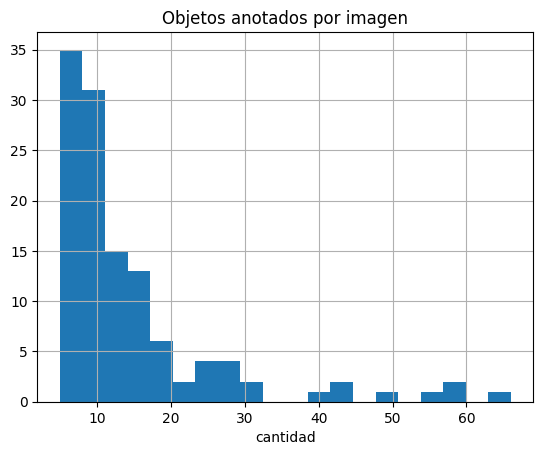

In [4]:
objs_per_img = anns.groupby('image_id').size().reindex(imgs['image_id']).fillna(0)
print(objs_per_img.describe().round(1))
n_max = int(objs_per_img.max())
print(f'Relaciones dirigidas posibles con {n_max} objetos: {3 * n_max * (n_max - 1)}')
objs_per_img.hist(bins=20); plt.title('Objetos anotados por imagen'); plt.xlabel('cantidad'); plt.show()

## 0.3 · ¿Qué tan grandes son los objetos?

**Decisión que motiva:**
- Por área de caja, el 59 % de las instancias ocupa menos del 1 % de la imagen (mediana 0,6 %). Los objetos chicos son el caso difícil: por eso el detector se corre con un umbral crudo bajo (A.5) y el recall se analiza por tamaño (A.10, B.8).
- Los cortes de `size` (1 % y 10 %) son una **decisión del grupo**. Se miran sobre el área de máscara porque así se calcula `size` en C.1; la salida muestra cómo queda repartido el dataset con esos cortes.

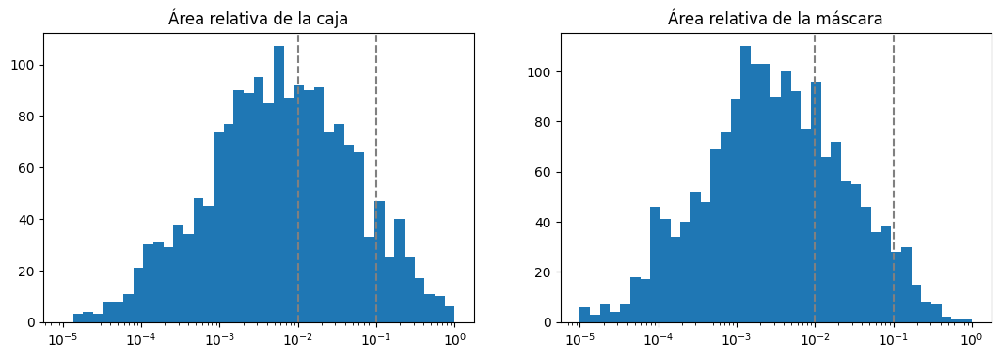

rel_area_caja {'small': 0.59, 'medium': 0.32, 'large': 0.09}
rel_area_mascara {'small': 0.71, 'medium': 0.24, 'large': 0.05}


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, col, titulo in zip(ax, ['rel_area_caja', 'rel_area_mascara'], ['caja', 'máscara']):
    a.hist(anns[col], bins=np.logspace(-5, 0, 40)); a.set_xscale('log')
    for corte in (0.01, 0.10):
        a.axvline(corte, ls='--', c='gray')
    a.set_title(f'Área relativa de la {titulo}')
plt.show()

for col in ('rel_area_caja', 'rel_area_mascara'):
    reparto = pd.cut(anns[col], [0, 0.01, 0.10, 1], labels=['small', 'medium', 'large'])
    print(col, reparto.value_counts(normalize=True).round(2).to_dict())

## 0.4 · ¿Qué categorías aparecen y con qué frecuencia?

**Decisión que motiva:** las 120 categorías aparecen al menos una vez y la distribución tiene cola larga (`book` 46 instancias; dos categorías con 3 o menos). El vocabulario del detector son los 120 nombres fijos (A.2), sin elegir clases por imagen. Las métricas por categoría con pocas instancias son inestables, así que se informan solo con al menos 5 instancias (A.10).

Categorías con al menos 1 instancia: 120 de 120
category
book       46
car        44
chair      40
box        40
wheel      37
pillow     31
shoe       31
curtain    29
person     29
sock       28
cabinet    28
knife      27
bicycle    27
hat        26
lamp       24
Name: count, dtype: int64
Categorías con 3 instancias o menos: 2


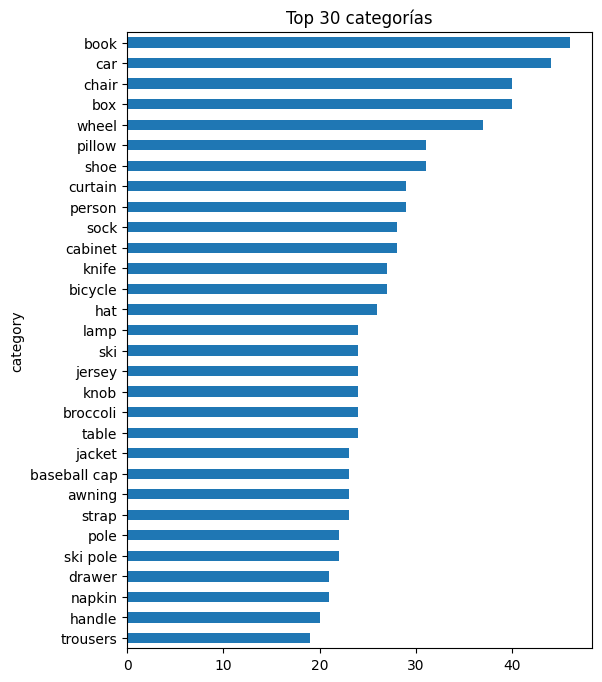

In [6]:
freq = anns['category'].value_counts()
print(f"Categorías con al menos 1 instancia: {len(freq)} de {len(cats)}")
print(freq.head(15))
print("Categorías con 3 instancias o menos:", (freq <= 3).sum())
freq.head(30).plot.barh(figsize=(6, 8)).invert_yaxis(); plt.title('Top 30 categorías'); plt.show()

## 0.5 · ¿Cómo están las etiquetas LVIS?

**Decisión que motiva:** por imagen hay en promedio 6,4 categorías positivas, 1,0 negativa verificada y 112,6 no verificadas. La mayoría de las predicciones cae en categorías no verificadas y se **ignora** al calcular la precisión. Por eso la precisión se informa junto con su **cobertura** (A.7).

In [7]:
flags = imgs.set_index('image_id').copy()
flags['n_pos'] = anns.groupby('image_id')['category_id'].nunique().reindex(flags.index).fillna(0)
flags['n_neg'] = flags['neg_category_ids'].apply(len)
flags['n_no_exhaustivas'] = flags['not_exhaustive_category_ids'].apply(len)
flags['n_no_verificadas'] = len(cats) - flags['n_pos'] - flags['n_neg']
print(flags[['n_pos', 'n_neg', 'n_no_exhaustivas', 'n_no_verificadas']].describe().round(1))

       n_pos  n_neg  n_no_exhaustivas  n_no_verificadas
count  120.0  120.0             120.0             120.0
mean     6.4    1.0               0.4             112.6
std      1.4    1.0               0.7               1.9
min      3.0    0.0               0.0             108.0
25%      6.0    0.0               0.0             112.0
50%      7.0    1.0               0.0             112.0
75%      7.2    2.0               1.0             114.0
max      8.0    4.0               4.0             117.0


## 0.6 · ¿Cómo son las imágenes?

**Decisión que motiva:** el lado mayor es como mucho 640 px y hay varias relaciones de aspecto (4:3, 3:2, verticales). No se redimensiona: OWLv2 rellena la imagen hasta hacerla cuadrada y las cajas se reescalan con el lado mayor (A.3); máscaras y RLE se generan al tamaño original.

In [8]:
print(imgs[['width', 'height']].describe())
print((imgs['width'] / imgs['height']).round(2).value_counts().head())

            width      height
count  120.000000  120.000000
mean   562.058333  495.583333
std    101.542333   93.951407
min    224.000000  332.000000
25%    480.000000  427.000000
50%    640.000000  480.000000
75%    640.000000  612.000000
max    640.000000  640.000000
1.33    33
1.50    20
0.75    13
0.67     9
1.51     7
Name: count, dtype: int64


## 0.7 · ¿Qué preguntas tiene el benchmark de lenguaje?

60 consignas sobre 20 imágenes: 20 descripciones, 10 de conteo, 10 de existencia, 5 de posición, 5 de tamaño y 10 de relación.

Las preguntas de posición, tamaño y relación hablan de **"la instancia de X"**. Se cuenta cuántas instancias anotadas tiene esa clase en la imagen: si hay más de una, la pregunta es ambigua.

**Lo que se ve:** en el benchmark todas las clases de las preguntas tienen exactamente una instancia anotada, así que la ambigüedad no aparece en el ground truth. Sí puede aparecer en las predicciones si el detector duplica o fragmenta un objeto.

**Decisión que motiva:** el motor mantiene una política de ambigüedad (E.2) para ese caso, y E.5 cuenta cuántas respuestas la usan en las escenas predichas, en vez de suponer que ocurre.

In [9]:
consignas_eda = pd.read_json(archivo_referencia('questions_dev.jsonl'), lines=True)
print(consignas_eda['type'].value_counts())

clave = lambda s: re.sub(r'[^a-z0-9]+', ' ', s.lower()).strip()
nombre_a_id = {clave(c['name']): c['id'] for c in data['categories']}
inst_por_clase = anns.groupby(['image_id', 'category_id']).size()
filas = [dict(tipo=q['type'], clase=clase,
              instancias=int(inst_por_clase.get((q['image_id'], nombre_a_id.get(clave(clase))), 0)))
         for _, q in consignas_eda[consignas_eda['type'].isin(['position', 'size', 'relation'])].iterrows()
         for clase in q['class_en']]
amb = pd.DataFrame(filas)
print(amb.groupby('tipo')['instancias'].describe()[['count', 'mean', 'max']])
print('"La instancia de X" con más de una instancia anotada:', round((amb['instancias'] > 1).mean(), 2))

type
description    20
count          10
existence      10
relation       10
position        5
size            5
Name: count, dtype: int64
          count  mean  max
tipo                      
position    5.0   1.0  1.0
relation   20.0   1.0  1.0
size        5.0   1.0  1.0
"La instancia de X" con más de una instancia anotada: 0.0


## A.1 · Modelo de detección

OWLv2 (`google/owlv2-base-patch16-ensemble`) en modo de evaluación sobre GPU.

In [10]:
from transformers import Owlv2Processor, Owlv2ForObjectDetection

MODEL_ID = 'google/owlv2-base-patch16-ensemble'
processor = Owlv2Processor.from_pretrained(MODEL_ID)
model = Owlv2ForObjectDetection.from_pretrained(MODEL_ID).to(device).eval()

preprocessor_config.json:   0%|          | 0.00/425 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.10k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/67.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/121 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  620MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/418 [00:00<?, ?it/s]

## A.2 · Vocabulario y datos

Las consultas de texto son los nombres de las 120 categorías, con guiones bajos y paréntesis reemplazados. El prompt es el nombre solo, sin plantilla. Es el vocabulario fijo del TP: no depende de la imagen y no usa las anotaciones de cada imagen.

`annotations.json` ya se leyó en la EDA (`data`); de ahí se toman categorías e imágenes de desarrollo. Las anotaciones de objetos solo se usan para evaluar.

In [11]:
categories = data['categories']                          # id + name
# Vocabulario: nombre de las 120 categorías. No se usan anotaciones de imágenes.
queries = [c['name'].replace('_', ' ').replace('(', '').replace(')', '') for c in categories]
print(len(queries), queries[:8])

images = data['images']
print(images[0])

120 ['sofa', 'laptop', 'pillow', 'bench', 'jacket', 'signboard', 'backpack', 'traffic light']
{'id': 1, 'file_name': 'tpi_0001.jpg', 'width': 480, 'height': 640, 'license': 3, 'neg_category_ids': [1, 7], 'not_exhaustive_category_ids': []}


## A.3 · Función de detección

`detect()` corre OWLv2 sobre una imagen con las 120 consultas y devuelve cajas en formato `xywh` (píxeles de la imagen original), score y categoría.

- OWLv2 rellena la imagen hasta hacerla cuadrada; por eso las cajas se reescalan con `target_sizes = (max(w, h), max(w, h))`.
- Umbral por defecto 0,1. Las cajas no se recortan a la imagen en esta etapa; el recorte se hace antes de pasarlas a SAM2 (sección B.2).

In [12]:
@torch.no_grad()
def detect(image, threshold=0.1):
    image = image.convert("RGB")
    w, h = image.size
    inputs = processor(text=[queries], images=image, return_tensors='pt').to(device)
    outputs = model(**inputs)
    side = max(w, h)    # OWLv2 rellena la imagen hasta hacerla cuadrada
    results = processor.image_processor.post_process_object_detection(
        outputs, threshold=threshold,
        target_sizes=torch.tensor([[side, side]], device=device))[0]
    dets = []
    for box, score, label in zip(results['boxes'].cpu().tolist(),
                                 results['scores'].cpu().tolist(),
                                 results['labels'].cpu().tolist()):
        x1, y1, x2, y2 = box
        dets.append({'category_id': categories[label]['id'],
                     'category': categories[label]['name'],
                     'score': round(score, 4),
                     'bbox': [round(x1, 1), round(y1, 1), round(x2 - x1, 1), round(y2 - y1, 1)]})
    return dets

## A.3b · Detección adoptada: recortes + NMS por IoS (EXP-011)

Desde EXP-011 (H.2.8) la pipeline no detecta solo sobre la imagen completa:

1. **Recortes:** además de la imagen completa, se detecta sobre 4 recortes solapados (grilla 2×2, solape 25 %). Cada objeto chico ocupa más parches de la entrada de OWLv2. Se descartan las cajas cortadas por un borde interior del recorte.
2. **NMS por IoS:** para eliminar repetidos de la misma categoría se usa la intersección dividida por el área de la caja **más chica** (umbral 0,5), el criterio por defecto de SAHI. Así se eliminan las cajas parciales que quedan dentro de otra caja, que el NMS por IoU no detecta.

Cada caja guarda su `origen` (`completa` o `recorte_k`). La detección de la imagen completa sola (`raw_completa`, A.6) es exactamente la de EXP-001 y se usa como línea base en los experimentos. `POSTPROCESO = 'iou'` y `detect()` reproducen EXP-001.


In [13]:
GRILLA, SOLAPE, MARGEN = (2, 2), 0.25, 0.02
POSTPROCESO = 'ios'          # 'iou' = NMS clásico (EXP-001) · 'ios' = NMS por IoS (EXP-011, adoptado)

def recortes_imagen(ancho, alto, grilla=GRILLA, solape=SOLAPE):
    """Recortes (x0, y0, x1, y1) que cubren toda la imagen, con `solape` compartido entre vecinos."""
    def ejes(largo, n):
        if n == 1:
            return [(0, largo)]
        lado = largo / (n - (n - 1) * solape)
        paso = lado * (1 - solape)
        return [(int(round(i * paso)), min(largo, int(round(i * paso + lado)))) for i in range(n)]
    xs, ys = ejes(ancho, grilla[0]), ejes(alto, grilla[1])
    return [(x0, y0, x1, y1) for (y0, y1) in ys for (x0, x1) in xs]

def detectar_final(imagen, umbral):
    """Detección sobre la imagen completa + recortes. Cajas en coordenadas de la imagen completa."""
    ancho, alto = imagen.size
    dets = [dict(d, origen='completa') for d in detect(imagen, threshold=umbral)]
    for k, (x0, y0, x1, y1) in enumerate(recortes_imagen(ancho, alto)):
        tw, th = x1 - x0, y1 - y0
        mx, my = max(2.0, MARGEN * tw), max(2.0, MARGEN * th)
        for d in detect(imagen.crop((x0, y0, x1, y1)), threshold=umbral):
            x, y, w, h = d['bbox']
            xa, ya, xb, yb = max(0.0, x), max(0.0, y), min(float(tw), x + w), min(float(th), y + h)
            if xb - xa < 1 or yb - ya < 1:
                continue
            if ((x0 > 0 and xa <= mx) or (x1 < ancho and xb >= tw - mx)
                    or (y0 > 0 and ya <= my) or (y1 < alto and yb >= th - my)):
                continue                    # caja cortada por un borde interior del recorte
            dets.append(dict(d, bbox=[round(xa + x0, 1), round(ya + y0, 1), round(xb - xa, 1), round(yb - ya, 1)],
                             origen=f'recorte_{k}'))
    return dets

def nms_ios(dets, thr=0.5):
    """NMS por categoría con IoS: descarta una caja si está casi toda dentro de otra de la misma clase con más score."""
    keep = []
    for d in sorted(dets, key=lambda d: -d['score']):
        x, y, w, h = d['bbox']
        tapada = False
        for k in keep:
            if k['category_id'] != d['category_id']:
                continue
            X, Y, W, H = k['bbox']
            iw = max(0, min(x + w, X + W) - max(x, X)); ih = max(0, min(y + h, Y + H) - max(y, Y))
            if iw * ih / max(min(w * h, W * H), 1e-6) >= thr:
                tapada = True; break
        if not tapada:
            keep.append(d)
    return keep

print('Recortes de una imagen de 640x480:', recortes_imagen(640, 480))


Recortes de una imagen de 640x480: [(0, 0, 366, 274), (274, 0, 640, 274), (0, 206, 366, 480), (274, 206, 640, 480)]


## A.4 · Control visual

Cuatro imágenes de desarrollo con umbral 0,3, para comprobar que las cajas y las etiquetas tienen sentido antes de correr todo.

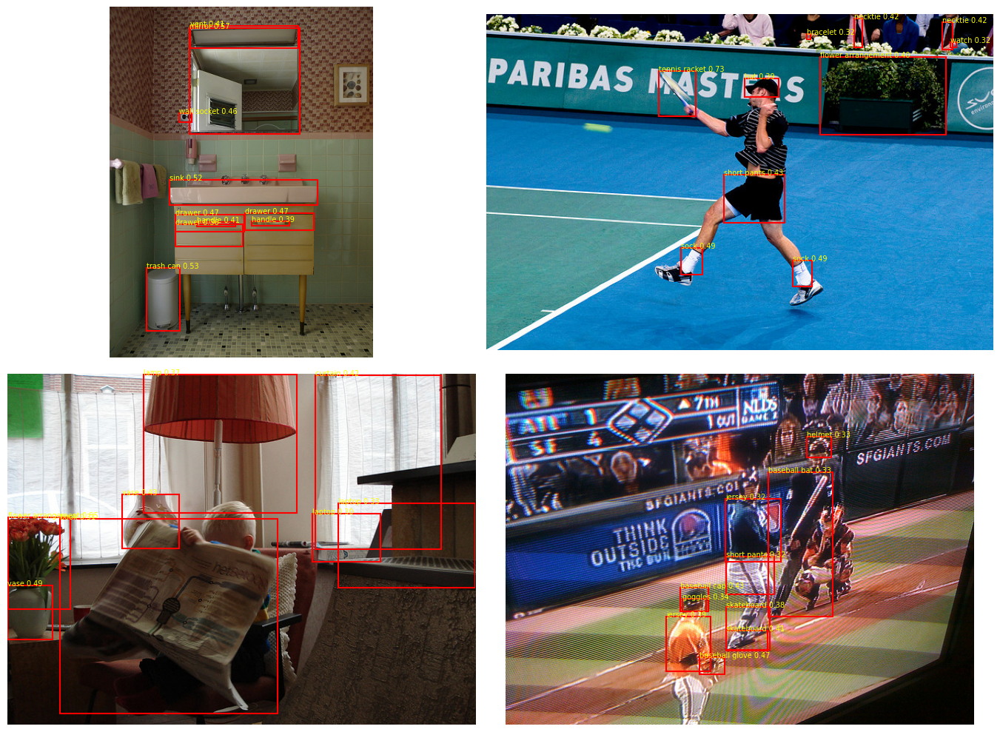

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, r in zip(axes.ravel(), images[:4]):
    im = Image.open(paths[img_name(r)]).convert('RGB')
    ax.imshow(im); ax.axis('off')
    for d in detect(im, threshold=0.3):
        x, y, bw, bh = d['bbox']
        ax.add_patch(patches.Rectangle((x, y), bw, bh, fill=False, edgecolor='red', lw=1.5))
        ax.text(x, y, f"{d['category']} {d['score']:.2f}", color='yellow', fontsize=7)
plt.tight_layout(); plt.show()

## A.5 · Detección sobre las 120 imágenes

Se corre el detector una sola vez con un umbral crudo bajo (0,05) y se guardan todas las detecciones. Los umbrales y el NMS se prueban después sobre ese archivo, sin volver a usar la GPU.

Desde EXP-011 cada imagen se detecta con `detectar_final` (imagen completa + 4 recortes, A.3b): ≈ 5 pasadas por imagen.


In [15]:
RAW_THR = 0.05      # bajo a propósito: filtramos después, sin volver a usar GPU
raw = {}
t0 = time.time()
for i, r in enumerate(images):
    with traza_dev.etapa(Path(img_name(r)).stem, 'deteccion', modelo=MODEL_ID, umbral_crudo=RAW_THR,
                         grilla=GRILLA, solape=SOLAPE, margen=MARGEN) as paso:
        im = Image.open(paths[img_name(r)]).convert('RGB')
        raw[r['id']] = detectar_final(im, RAW_THR)
        paso['artefactos']['detecciones_crudas'] = len(raw[r['id']])
    if i % 20 == 0:
        print(i, f'{time.time() - t0:.0f}s')

with open(OUT_DIR / 'detections_raw_owlv2.json', 'w') as f:
    json.dump({'model': MODEL_ID, 'raw_threshold': RAW_THR, 'deteccion': 'completa + recortes',
               'grilla': GRILLA, 'solape': SOLAPE, 'margen': MARGEN, 'detections': raw}, f)
print('Listo:', sum(len(v) for v in raw.values()), 'detecciones en', len(raw), 'imágenes')

0 2s
20 43s
40 89s
60 139s
80 188s
100 236s
Listo: 40677 detecciones en 120 imágenes


## A.6 · Detecciones y anotaciones

Se cargan las detecciones crudas y se arman las estructuras de evaluación: `gt` (cajas anotadas por imagen y categoría), `neg` (categorías verificadas como ausentes) y `nonex` (categorías positivas no exhaustivas). Estas estructuras se usan solo para evaluar, nunca para predecir.

In [16]:
img_info = {r['id']: r for r in images}
cat_name = {c['id']: c['name'] for c in data['categories']}

# Detecciones crudas guardadas en la sección A.5 (sin filtrar)
saved = json.load(open(OUT_DIR / 'detections_raw_owlv2.json'))
raw = {int(k): v for k, v in saved['detections'].items()}
raw_completa = {i: [d for d in v if d['origen'] == 'completa'] for i, v in raw.items()}   # = detección de EXP-001, para comparar


# ---- Anotaciones: SOLO para EVALUAR, nunca para predecir ----
gt = {}   # gt[image_id][category_id] = lista de cajas [x, y, ancho, alto]
for a in data['annotations']:
    gt.setdefault(a['image_id'], {}).setdefault(a['category_id'], []).append(a['bbox'])
neg   = {r['id']: set(r.get('neg_category_ids', [])) for r in images}
nonex = {r['id']: set(r.get('not_exhaustive_category_ids', [])) for r in images}

n_gt = sum(len(b) for d in gt.values() for b in d.values())
print('Instancias anotadas (GT):', n_gt)
print('Detecciones crudas:', sum(len(v) for v in raw.values()))
print('Imágenes con categorías negativas:', sum(1 for s in neg.values() if s))
print('Imágenes con categorías no exhaustivas:', sum(1 for s in nonex.values() if s))

Instancias anotadas (GT): 1790
Detecciones crudas: 40677
Imágenes con categorías negativas: 74
Imágenes con categorías no exhaustivas: 36


In [17]:
# Control: la detección de la imagen completa sola es la de EXP-001 (17797 detecciones crudas)
print('Detecciones crudas: total', sum(len(v) for v in raw.values()),
      '| solo imagen completa', sum(len(v) for v in raw_completa.values()), '(EXP-001: 17797)')


Detecciones crudas: total 40677 | solo imagen completa 17797 (EXP-001: 17797)


## A.7 · Funciones de evaluación (política LVIS)

- `filtrar`: filtra por umbral y elimina repetidos por categoría. Por defecto usa `POSTPROCESO` (`'ios'`, adoptado en EXP-011); con `tipo='iou'` reproduce el NMS clásico de EXP-001.
- `evaluar`: empareja cada predicción con una caja anotada de su misma categoría (IoU ≥ 0,5, mayor score primero) y clasifica el resto según la política LVIS:
  - falso positivo si la categoría está verificada como ausente, o es positiva exhaustiva y sobra;
  - ignorada si la categoría es positiva no exhaustiva o no está verificada.
- El recall se calcula sobre todas las instancias anotadas. La precisión solo cuenta predicciones decidibles, por eso se informa junto con la **cobertura** (decidibles / total).

In [18]:
def xywh_to_xyxy(boxes):
    t = torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4)
    t[:, 2] += t[:, 0]
    t[:, 3] += t[:, 1]
    return t

def filtrar(dets, thr, nms_iou=None, tipo=None):
    """Se queda con las detecciones de score >= thr y (opcional) elimina repetidos de la misma categoría.
    tipo='iou': NMS clásico (EXP-001) · tipo='ios': NMS por IoS (EXP-011). Por defecto, POSTPROCESO."""
    tipo = tipo or POSTPROCESO
    dets = [d for d in dets if d['score'] >= thr]
    if nms_iou is not None and dets:
        if tipo == 'ios':
            return nms_ios(dets, nms_iou)
        boxes  = xywh_to_xyxy([d['bbox'] for d in dets])
        scores = torch.tensor([d['score'] for d in dets])
        cats   = torch.tensor([d['category_id'] for d in dets])
        keep = batched_nms(boxes, scores, cats, nms_iou)
        dets = [dets[i] for i in keep.tolist()]
    return dets

def evaluar(thr, nms_iou=0.5, iou_thr=0.5, detalle=False, fuente=None):
    TP = FP = FN = ign = 0
    pred_rows, gt_rows = [], []
    for img_id, info in img_info.items():
        area_img = info['width'] * info['height']
        dets = filtrar(raw.get(img_id, []), thr, nms_iou) if fuente is None else fuente.get(img_id, [])
        por_cat = {}
        for d in dets:
            por_cat.setdefault(d['category_id'], []).append(d)
        positivas = gt.get(img_id, {})

        for cat in set(por_cat) | set(positivas):
            preds  = sorted(por_cat.get(cat, []), key=lambda d: -d['score'])
            gboxes = positivas.get(cat, [])
            gmatch = [False] * len(gboxes)
            ious = None
            if preds and gboxes:
                ious = box_iou(xywh_to_xyxy([d['bbox'] for d in preds]),
                               xywh_to_xyxy(gboxes)).numpy()

            for i, d in enumerate(preds):
                best_j, best_iou = -1, 0.0
                if ious is not None:
                    for j in range(len(gboxes)):
                        if not gmatch[j] and ious[i, j] > best_iou:
                            best_j, best_iou = j, float(ious[i, j])
                if best_j >= 0 and best_iou >= iou_thr:
                    gmatch[best_j] = True
                    estado = 'TP'; TP += 1
                elif cat in neg[img_id]:
                    estado = 'FP'; FP += 1                 # ausente verificada
                elif cat in positivas:
                    if cat in nonex[img_id]:
                        estado = 'ignorada'; ign += 1      # positiva no exhaustiva
                    else:
                        estado = 'FP'; FP += 1             # positiva exhaustiva: sobra
                else:
                    estado = 'ignorada'; ign += 1          # no verificada
                if detalle:
                    pred_rows.append(dict(image_id=img_id, category_id=cat,
                                          category=cat_name[cat], score=d['score'],
                                          bbox=d['bbox'], estado=estado))

            for j, b in enumerate(gboxes):
                if not gmatch[j]:
                    FN += 1
                if detalle:
                    gt_rows.append(dict(image_id=img_id, category_id=cat,
                                        category=cat_name[cat], bbox=b,
                                        rel_area=b[2] * b[3] / area_img,
                                        detectado=gmatch[j]))

    juzgadas = TP + FP
    total = TP + FP + ign
    precision = TP / juzgadas if juzgadas else 0.0
    recall = TP / (TP + FN) if (TP + FN) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    m = dict(umbral=thr, nms='sin NMS' if nms_iou is None else f'NMS {nms_iou}',
             TP=TP, FP=FP, FN=FN, ignoradas=ign, predicciones=total,
             precision=round(precision, 4), recall=round(recall, 4), f1=round(f1, 4),
             cobertura=round(juzgadas / total, 4) if total else 0.0)
    if detalle:
        return m, pd.DataFrame(pred_rows), pd.DataFrame(gt_rows)
    return m

## A.8 · Barrido de umbral y NMS

F1, precisión, recall y cobertura para umbrales entre 0,05 y 0,5, sin NMS y con NMS 0,5. Las líneas del gráfico marcan los F1 de 0,40 (aprobado) y 0,50 (promoción).

,umbral,nms,TP,FP,FN,ignoradas,predicciones,precision,recall,f1,cobertura
0,0.05,sin NMS,1508,9684,282,29485,40677,0.1347,0.8425,0.2323,0.2751
1,0.10,sin NMS,1434,4658,356,12713,18805,0.2354,0.8011,0.3639,0.3240
2,0.15,sin NMS,1344,2901,446,7190,11435,0.3166,0.7508,0.4454,0.3712
3,0.20,sin NMS,1240,1983,550,4482,7705,0.3847,0.6927,0.4947,0.4183
4,0.25,sin NMS,1137,1414,653,2855,5406,0.4457,0.6352,0.5238,0.4719
5,0.30,sin NMS,1026,1042,764,1883,3951,0.4961,0.5732,0.5319,0.5234
6,0.35,sin NMS,897,777,893,1236,2910,0.5358,0.5011,0.5179,0.5753
7,0.40,sin NMS,774,578,1016,809,2161,0.5725,0.4324,0.4927,0.6256
8,0.50,sin NMS,529,301,1261,318,1148,0.6373,0.2955,0.4038,0.7230
9,0.05,NMS 0.5,1282,2102,508,11371,14755,0.3788,0.7162,0.4956,0.2293


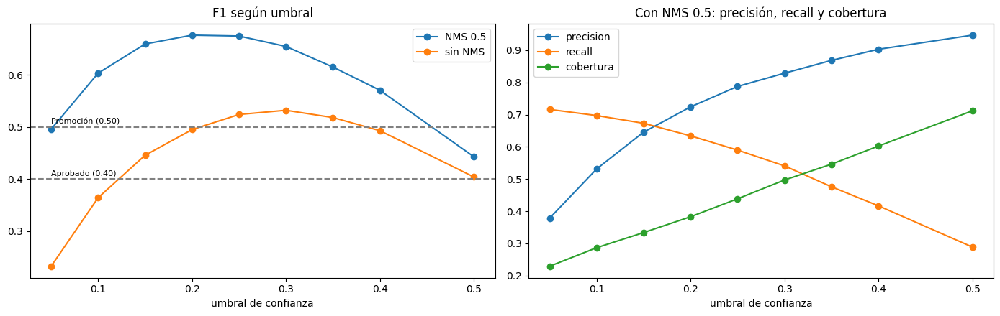

In [19]:
umbrales = [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5]
filas = [evaluar(t, nms) for nms in (None, 0.5) for t in umbrales]
tabla = pd.DataFrame(filas)
display(tabla)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for nms, g in tabla.groupby('nms'):
    ax[0].plot(g['umbral'], g['f1'], marker='o', label=nms)
ax[0].axhline(0.40, ls='--', c='gray'); ax[0].text(0.05, 0.405, 'Aprobado (0.40)', fontsize=8)
ax[0].axhline(0.50, ls='--', c='gray'); ax[0].text(0.05, 0.505, 'Promoción (0.50)', fontsize=8)
ax[0].set_title('F1 según umbral'); ax[0].set_xlabel('umbral de confianza'); ax[0].legend()

g = tabla[tabla['nms'] == 'NMS 0.5']
for col in ('precision', 'recall', 'cobertura'):
    ax[1].plot(g['umbral'], g[col], marker='o', label=col)
ax[1].set_title('Con NMS 0.5: precisión, recall y cobertura'); ax[1].set_xlabel('umbral de confianza')
ax[1].legend()
plt.tight_layout(); plt.show()

## A.9 · Configuración base

Se toma la combinación con mayor F1 del barrido. El umbral y el NMS se eligen sobre las mismas 120 imágenes en las que se mide el F1, así que el valor está sobreajustado a desarrollo (limitación a declarar en el reporte).

Desde EXP-011 el barrido de A.8 corre sobre la detección adoptada (recortes + NMS por IoS); la fila `NMS 0.5` corresponde al NMS por IoS con umbral 0,5. Línea base de EXP-001: umbral 0,20, NMS por IoU 0,5, F1 0,6512.


In [20]:
mejor = tabla.sort_values('f1', ascending=False).iloc[0]
UMBRAL  = float(mejor['umbral'])
NMS_IOU = None if mejor['nms'] == 'sin NMS' else 0.5

print('Configuración elegida:', UMBRAL, NMS_IOU)
m, pred_df, gt_df = evaluar(UMBRAL, NMS_IOU, detalle=True)
print(m)

Configuración elegida: 0.2 0.5
{'umbral': 0.2, 'nms': 'NMS 0.5', 'TP': 1135, 'FP': 432, 'FN': 655, 'ignoradas': 2525, 'predicciones': 4092, 'precision': 0.7243, 'recall': 0.6341, 'f1': 0.6762, 'cobertura': 0.3829}


## A.10 · Dónde acierta y dónde falla

Resultado por tipo (TP, FP, ignoradas, FN), recall según tamaño del objeto, separación de scores entre aciertos y falsos positivos, y categorías con peor recall y más falsos positivos. Los cortes de tamaño (1 % y 10 % del área de la imagen) son provisorios.

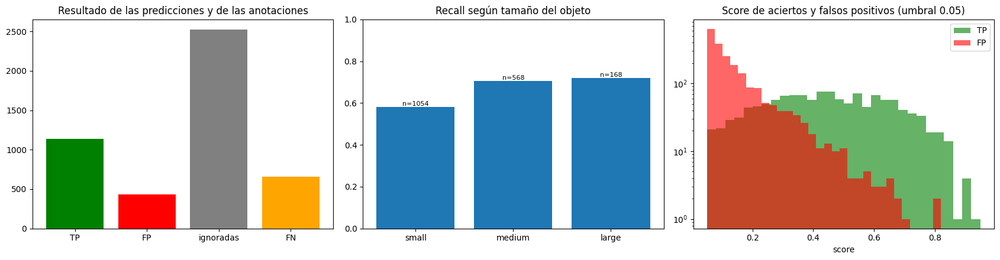

--- Categorías con peor recall (al menos 5 instancias) ---
             n_gt    recall
category                   
book           46  0.108696
strap          23  0.217391
curtain        29  0.275862
broccoli       24  0.291667
doorknob       10  0.300000
mirror         19  0.315789
wheel          37  0.324324
streetlight     9  0.333333
cabinet        28  0.357143
blanket        10  0.400000

--- Categorías con más falsos positivos ---
category
traffic light    24
sock             15
wall socket      14
box              14
ski              10
knife            10
pillow            9
streetlight       9
baseball bat      9
car               9
Name: count, dtype: int64


In [21]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

# 1) Recuento de resultados
vals = [m['TP'], m['FP'], m['ignoradas'], m['FN']]
ax[0].bar(['TP', 'FP', 'ignoradas', 'FN'], vals, color=['g', 'r', 'gray', 'orange'])
ax[0].set_title('Resultado de las predicciones y de las anotaciones')

# 2) Recall por tamaño del objeto
gt_df['tamaño'] = pd.cut(gt_df['rel_area'], [0, 0.01, 0.10, 1], labels=['small', 'medium', 'large'])
rec = gt_df.groupby('tamaño', observed=True)['detectado'].agg(['mean', 'count'])
ax[1].bar(rec.index.astype(str), rec['mean'])
for i, (v, n) in enumerate(zip(rec['mean'], rec['count'])):
    ax[1].text(i, v, f'n={n}', ha='center', va='bottom', fontsize=8)
ax[1].set_ylim(0, 1); ax[1].set_title('Recall según tamaño del objeto')

# 3) Score de aciertos vs falsos positivos (con umbral bajo, para ver dónde convendría cortar)
_, p_low, _ = evaluar(0.05, NMS_IOU, detalle=True)
for estado, color in (('TP', 'g'), ('FP', 'r')):
    ax[2].hist(p_low.loc[p_low['estado'] == estado, 'score'], bins=30, alpha=0.6,
               color=color, label=estado)
ax[2].set_yscale('log'); ax[2].legend()
ax[2].set_title('Score de aciertos y falsos positivos (umbral 0.05)'); ax[2].set_xlabel('score')
plt.tight_layout(); plt.show()

# Categorías que más fallan
por_cat = gt_df.groupby('category')['detectado'].agg(n_gt='count', recall='mean')
print('--- Categorías con peor recall (al menos 5 instancias) ---')
print(por_cat[por_cat['n_gt'] >= 5].sort_values('recall').head(10))
print('\n--- Categorías con más falsos positivos ---')
print(pred_df[pred_df['estado'] == 'FP']['category'].value_counts().head(10))

## A.11 · Ejemplos

Cuatro imágenes al azar (semilla fija): verde = acierto, rojo = falso positivo, naranja punteado = objeto anotado no detectado.

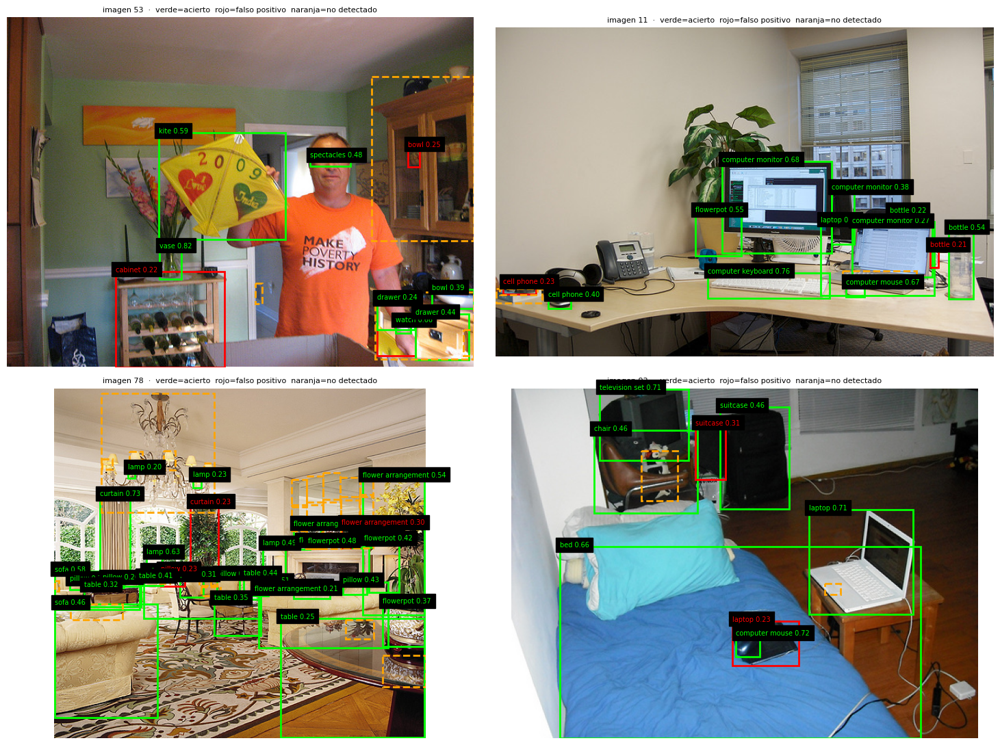

In [22]:
rng = np.random.default_rng(42)
ids = rng.choice(list(img_info), 4, replace=False)

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
for ax, img_id in zip(axes.ravel(), ids):
    im = Image.open(paths[img_name(img_info[img_id])]).convert('RGB')
    ax.imshow(im); ax.axis('off')
    for _, r in pred_df[(pred_df['image_id'] == img_id) & pred_df['estado'].isin(['TP', 'FP'])].iterrows():
        x, y, w, h = r['bbox']
        c = 'lime' if r['estado'] == 'TP' else 'red'
        ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, edgecolor=c, lw=2))
        ax.text(x, y, f"{r['category']} {r['score']:.2f}", color=c, fontsize=7, backgroundcolor='black')
    for _, r in gt_df[(gt_df['image_id'] == img_id) & (~gt_df['detectado'])].iterrows():
        x, y, w, h = r['bbox']
        ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, edgecolor='orange', lw=2, ls='--'))
    ax.set_title(f'imagen {img_id}  ·  verde=acierto  rojo=falso positivo  naranja=no detectado', fontsize=8)
plt.tight_layout(); plt.show()

## A.12 · Resultado auditable

Se guarda en `eval_exp001.json` la configuración (modelo, umbral, NMS, IoU), la política de evaluación, las métricas y el barrido completo.

In [23]:
resultado = dict(
    experimento='EXP-001', modelo=saved['model'],
    umbral=UMBRAL, nms_iou=NMS_IOU, iou_para_acierto=0.5,
    politica='LVIS: FP solo en ausentes verificadas y positivas exhaustivas',
    metricas=m, barrido=tabla.to_dict('records'))
with open(OUT_DIR / 'eval_exp001.json', 'w') as f:
    json.dump(resultado, f, indent=2, default=lambda o: o.item() if hasattr(o, 'item') else str(o))
print('Guardado')

Guardado


## A.13 · Control de la política LVIS

Comprueba que ninguna categoría sea a la vez positiva y negativa en una imagen, y cuenta cuántas predicciones cae en cada tipo de categoría (ausente verificada, no verificada, positiva exhaustiva y no exhaustiva).

In [24]:
def tipo_categoria(img_id, cat):
    if cat in neg[img_id]:
        return 'ausente verificada'
    if cat in gt.get(img_id, {}):
        return 'positiva no exhaustiva' if cat in nonex[img_id] else 'positiva exhaustiva'
    return 'no verificada'

# Sanidad: ninguna categoría debería ser a la vez positiva y negativa en una imagen
print('Contradicciones positiva/negativa:',
      sum(1 for i in img_info for c in gt.get(i, {}) if c in neg[i]))

m, pred_df, gt_df = evaluar(UMBRAL, NMS_IOU, detalle=True)
pred_df['tipo'] = [tipo_categoria(i, c) for i, c in zip(pred_df['image_id'], pred_df['category_id'])]
print(pd.crosstab(pred_df['tipo'], pred_df['estado'], margins=True))

Contradicciones positiva/negativa: 0
estado                   FP    TP  ignorada   All
tipo                                             
ausente verificada        3     0         0     3
no verificada             0     0      2461  2461
positiva exhaustiva     429  1036         0  1465
positiva no exhaustiva    0    99        64   163
All                     432  1135      2525  4092


## A.14 · Tipos de falsos positivos

Para cada falso positivo de categoría positiva exhaustiva se mide el mayor IoU con una caja anotada de la misma categoría: caja mal ubicada (0,1 ≤ IoU < 0,5), objeto extra o sin relación (IoU < 0,1) o duplicado de un objeto ya detectado (IoU ≥ 0,5). También se calcula la precisión si las no exhaustivas contaran como positivas normales.

In [25]:
fp = pred_df[(pred_df['estado'] == 'FP') & (pred_df['tipo'] == 'positiva exhaustiva')].copy()

def max_iou_misma_categoria(r):
    gboxes = gt[r['image_id']][r['category_id']]
    iou = box_iou(xywh_to_xyxy([r['bbox']]), xywh_to_xyxy(gboxes))
    return float(iou.max())

fp['max_iou'] = fp.apply(max_iou_misma_categoria, axis=1)
fp['causa'] = pd.cut(fp['max_iou'], [-0.01, 0.1, 0.5, 1.01], right=False,
                     labels=['objeto extra o sin relación (IoU<0.1)',
                             'caja mal ubicada (0.1≤IoU<0.5)',
                             'duplicado de objeto ya detectado (IoU≥0.5)'])
print(fp['causa'].value_counts())
print(fp['causa'].value_counts(normalize=True).round(2))

# Recall y F1 de la configuración elegida
print({k: m[k] for k in ('TP', 'FP', 'FN', 'precision', 'recall', 'f1', 'cobertura')})

# Sensibilidad: ¿y si las no exhaustivas contaran como positivas normales?
extra = ((pred_df['tipo'] == 'positiva no exhaustiva') & (pred_df['estado'] == 'ignorada')).sum()
print('Precisión si las no exhaustivas contaran:',
      round(m['TP'] / (m['TP'] + m['FP'] + extra), 4))

causa
objeto extra o sin relación (IoU<0.1)         297
caja mal ubicada (0.1≤IoU<0.5)                132
duplicado de objeto ya detectado (IoU≥0.5)      0
Name: count, dtype: int64
causa
objeto extra o sin relación (IoU<0.1)         0.69
caja mal ubicada (0.1≤IoU<0.5)                0.31
duplicado de objeto ya detectado (IoU≥0.5)    0.00
Name: proportion, dtype: float64
{'TP': 1135, 'FP': 432, 'FN': 655, 'precision': 0.7243, 'recall': 0.6341, 'f1': 0.6762, 'cobertura': 0.3829}
Precisión si las no exhaustivas contaran: 0.6959


# Parte B · Segmentación con SAM2

Se segmenta cada detección con SAM2 usando su caja como único prompt, y se evalúan las máscaras con la misma política LVIS. Las detecciones de entrada son las de la configuración base (umbral y NMS de la sección A.9).

## B.1 · Carga de SAM2 y selección de detecciones

Modelo `facebook/sam2.1-hiera-large`, sin comparar con las variantes más livianas. Se segmentan las detecciones filtradas con el umbral y el NMS elegidos, con un máximo de objetos por imagen tomado de `scene_schema.json`.

In [26]:
from transformers import Sam2Processor, Sam2Model

with archivo_referencia('scene_schema.json').open(encoding='utf-8') as f:
    schema = json.load(f)
MAX_OBJ = schema['properties']['objects']['maxItems']          # 300

SAM_ID = 'facebook/sam2.1-hiera-large'     # alternativas más livianas: ...-base-plus, ...-small, ...-tiny
sam_processor = Sam2Processor.from_pretrained(SAM_ID)
sam_model = Sam2Model.from_pretrained(SAM_ID).to(device).eval()

# Detecciones que pasan a segmentación: umbral + NMS elegidos antes, y como máximo MAX_OBJ por imagen
filtradas, excedidas = {}, 0
for i in img_info:
    with traza_dev.etapa(Path(img_name(img_info[i])).stem, 'filtrado',
                         umbral=UMBRAL, nms_iou=NMS_IOU, max_objetos=MAX_OBJ) as paso:
        completas = filtrar(raw.get(i, []), UMBRAL, NMS_IOU)
        excedidas += len(completas) > MAX_OBJ
        filtradas[i] = sorted(completas, key=lambda d: -d['score'])[:MAX_OBJ]
        paso['artefactos'].update(entrada=len(raw.get(i, [])), salida=len(filtradas[i]))

print('Detecciones a segmentar:', sum(len(v) for v in filtradas.values()))
print(f'Imágenes que superaban el máximo de {MAX_OBJ} objetos:', excedidas)
print('Máximo por imagen:', max(len(v) for v in filtradas.values()))

processor_config.json:   0%|          | 0.00/95.0 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/683 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/5.71k [00:00<?, ?B/s]

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


model.safetensors: reconstructing file:   0%|          |  0.00B /  898MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/741 [00:00<?, ?it/s]

Detecciones a segmentar: 4092
Imágenes que superaban el máximo de 300 objetos: 0
Máximo por imagen: 115


## B.2 · Función de segmentación

Las cajas se pasan a esquina-esquina y se recortan a los bordes de la imagen (OWLv2 puede devolver cajas fuera de la imagen por el padding). SAM2 recibe solo la imagen y las cajas, de a 16 por vez para cuidar la memoria. Con `multimask_output=False` devuelve una máscara por caja, a tamaño original.

In [27]:
@torch.no_grad()
def segmentar(image, dets, chunk=16):
    """Una máscara binaria (H, W) por cada detección, en el mismo orden."""
    if not dets:
        return []
    w, h = image.size
    out = []
    for i in range(0, len(dets), chunk):          # de a 16 cajas, para no agotar memoria
        cajas = []
        for d in dets[i:i + chunk]:
            x, y, bw, bh = d['bbox']
            cajas.append([max(0, x), max(0, y), min(w, x + bw), min(h, y + bh)])  # recorta a la imagen
        inputs = sam_processor(images=image, input_boxes=[cajas], return_tensors='pt').to(device)
        outputs = sam_model(**inputs, multimask_output=False)
        masks = sam_processor.post_process_masks(outputs.pred_masks.cpu(),
                                                 inputs['original_sizes'])[0]
        out.extend(masks[:, 0].numpy().astype(bool))      # (n, 1, H, W) -> (n, H, W)
    return out

## B.3 · Control visual de las máscaras

Tres imágenes al azar (semilla fija). Se busca que las máscaras se apoyen sobre los objetos y no se salgan al fondo ni partan el objeto.

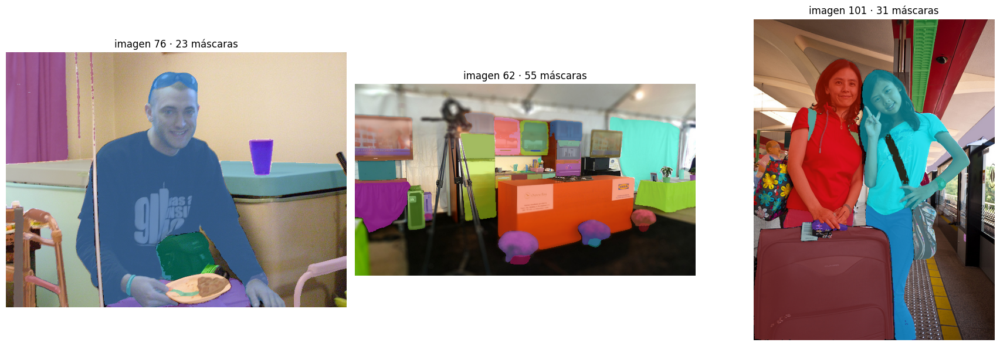

In [28]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, img_id in zip(axes, rng.choice(list(img_info), 3, replace=False)):
    im = Image.open(paths[img_name(img_info[img_id])]).convert('RGB')
    ms = segmentar(im, filtradas[img_id])
    canvas = np.array(im).astype(float)
    for m_ in ms:
        color = rng.integers(0, 255, 3)
        canvas[m_] = 0.5 * canvas[m_] + 0.5 * color
    ax.imshow(canvas.astype(np.uint8)); ax.axis('off')
    ax.set_title(f'imagen {img_id} · {len(ms)} máscaras')
plt.tight_layout(); plt.show()

## B.4 · Segmentación de las 120 imágenes

Se guardan las máscaras en el formato comprimido de `pycocotools` solo para evaluar rápido. Se descartan las máscaras vacías (`area_ratio` tiene que ser > 0) y se cuentan las imágenes cuyo tamaño real no coincide con el declarado. El formato del TP (RLE sin comprimir) se genera en la sección B.6.

In [29]:
rles = {}          # rles[image_id] = lista de RLE (pycocotools), alineada con filtradas[image_id]
vacias = tam_distinto = 0
t0 = time.time()
for k, (img_id, dets) in enumerate(list(filtradas.items())):
    info = img_info[img_id]
    with traza_dev.etapa(Path(img_name(info)).stem, 'segmentacion', modelo=SAM_ID, chunk=16) as paso:
        im = Image.open(paths[img_name(info)]).convert('RGB')
        if im.size != (info['width'], info['height']):
            tam_distinto += 1                        # el tamaño del archivo no coincide con el declarado
        keep_d, keep_r = [], []
        for d, m_ in zip(dets, segmentar(im, dets)):
            if not m_.any():                         # máscara vacía -> area_ratio = 0 -> invalidaría la fila
                vacias += 1
                continue
            keep_d.append(d)
            keep_r.append(mask_utils.encode(np.asfortranarray(m_.astype(np.uint8))))
        paso['artefactos'].update(cajas=len(dets), mascaras=len(keep_r), vacias=len(dets) - len(keep_r))
    filtradas[img_id] = keep_d                   # se actualiza para que siga alineada con rles
    rles[img_id] = keep_r
    if k % 20 == 0:
        print(k, f'{time.time() - t0:.0f}s')

print('Máscaras válidas:', sum(len(v) for v in rles.values()))
print('Máscaras vacías descartadas:', vacias)
print('Imágenes cuyo archivo no coincide con width/height del dataset:', tam_distinto)

0 2s
20 43s
40 86s
60 141s
80 180s
100 228s
Máscaras válidas: 4092
Máscaras vacías descartadas: 0
Imágenes cuyo archivo no coincide con width/height del dataset: 0


## B.5 · F1 de máscaras

Misma lógica LVIS que en las cajas, pero el solapamiento se mide entre máscaras (IoU de máscaras ≥ 0,5). El enunciado no define cómo se calcula el F1 de máscaras: este es un **supuesto del grupo**, a registrar en `DECISIONES.md`.

Las cajas se reevalúan sobre exactamente las mismas detecciones para que la comparación sea justa.

In [30]:
def gt_a_rle(ann, h, w):
    seg = ann['segmentation']
    if isinstance(seg, list):                         # polígonos
        return mask_utils.merge(mask_utils.frPyObjects(seg, h, w))
    if isinstance(seg['counts'], list):               # RLE sin comprimir
        return mask_utils.frPyObjects(seg, h, w)
    return seg                                        # RLE comprimido

gt_rle = {}
for a in data['annotations']:
    info = img_info[a['image_id']]
    gt_rle.setdefault(a['image_id'], {}).setdefault(a['category_id'], []).append(
        gt_a_rle(a, info['height'], info['width']))

def evaluar_mascaras(iou_thr=0.5, detalle=False):
    TP = FP = FN = ign = 0
    pred_rows, gt_rows = [], []
    for img_id, info in img_info.items():
        area_img = info['width'] * info['height']
        por_cat = {}
        for idx, (d, r) in enumerate(zip(filtradas[img_id], rles[img_id])):
            por_cat.setdefault(d['category_id'], []).append((idx, d, r))
        positivas = gt_rle.get(img_id, {})
        for cat in set(por_cat) | set(positivas):
            preds = sorted(por_cat.get(cat, []), key=lambda t: -t[1]['score'])
            grles = positivas.get(cat, [])
            gmatch = [False] * len(grles)
            ious = None
            if preds and grles:
                ious = mask_utils.iou([r for _, _, r in preds], grles, [0] * len(grles))
            for i, (idx, d, _) in enumerate(preds):
                best_j, best = -1, 0.0
                if ious is not None:
                    for j in range(len(grles)):
                        if not gmatch[j] and ious[i][j] > best:
                            best_j, best = j, float(ious[i][j])
                if best_j >= 0 and best >= iou_thr:
                    gmatch[best_j] = True
                    estado = 'TP'; TP += 1
                elif cat in neg[img_id]:
                    estado = 'FP'; FP += 1
                elif cat in gt.get(img_id, {}):
                    if cat in nonex[img_id]:
                        estado = 'ignorada'; ign += 1
                    else:
                        estado = 'FP'; FP += 1
                else:
                    estado = 'ignorada'; ign += 1
                if detalle:
                    pred_rows.append(dict(image_id=img_id, category_id=cat, category=cat_name[cat],
                                          score=d['score'], estado=estado, idx=idx,
                                          mask_iou=best, gt_j=best_j))
            FN += sum(not g for g in gmatch)
            if detalle:
                for j, g in enumerate(gmatch):
                    b = gt[img_id][cat][j]
                    gt_rows.append(dict(image_id=img_id, category_id=cat, category=cat_name[cat],
                                        rel_area=b[2] * b[3] / area_img, detectado=g))
    p = TP / (TP + FP) if TP + FP else 0.0
    r = TP / (TP + FN) if TP + FN else 0.0
    f1 = 2 * p * r / (p + r) if p + r else 0.0
    m = dict(TP=TP, FP=FP, FN=FN, ignoradas=ign, precision=round(p, 4),
             recall=round(r, 4), f1=round(f1, 4))
    if detalle:
        return m, pd.DataFrame(pred_rows), pd.DataFrame(gt_rows)
    return m

m_masc, pm, gm = evaluar_mascaras(detalle=True)
m_caja, pc, gc = evaluar(UMBRAL, NMS_IOU, detalle=True, fuente=filtradas)   # cajas, sobre exactamente las mismas detecciones
print('Cajas   :', {k: m_caja[k] for k in ('TP', 'FP', 'FN', 'precision', 'recall', 'f1')})
print('Máscaras:', m_masc)


Cajas   : {'TP': 1135, 'FP': 432, 'FN': 655, 'precision': 0.7243, 'recall': 0.6341, 'f1': 0.6762}
Máscaras: {'TP': 1088, 'FP': 475, 'FN': 702, 'ignoradas': 2529, 'precision': 0.6961, 'recall': 0.6078, 'f1': 0.649}


## B.6 · Formato de máscara del TP

Conversión a RLE sin comprimir, column-major, con `size = [alto, ancho]`, y validación de todas las máscaras: subesquema `mask` de `scene_schema.json`, `size` igual al tamaño de la imagen y suma de `counts` igual a alto × ancho. Además:

- Ida y vuelta: convertir y decodificar tiene que devolver la misma máscara.
- Comparación con la fila de ejemplo de `sample_submission.csv`: el orden `[alto, ancho]` queda confirmado; el formato de bbox quedó confirmado por el evaluador como esquinas, con orden y extremo exclusivo deducidos y `centroid` no (el ejemplo es un único píxel).

In [31]:
def rle_esquema(mask):
    """Máscara booleana (H, W) -> {'size': [H, W], 'counts': [...]} sin comprimir, column-major."""
    h, w = mask.shape
    flat = mask.astype(np.uint8).flatten(order='F')            # column-major
    cortes = np.flatnonzero(np.diff(flat)) + 1
    runs = np.diff(np.concatenate(([0], cortes, [flat.size]))).tolist()
    if flat[0] == 1:
        runs = [0] + runs                                       # siempre se empieza contando ceros
    return {'size': [int(h), int(w)], 'counts': [int(r) for r in runs]}   # enteros de Python (JSON)

def rle_a_esquema(rle):
    """RLE comprimido de pycocotools -> formato del esquema."""
    return rle_esquema(mask_utils.decode(rle).astype(bool))

# El validador usa el subesquema de 'mask' tal como está escrito en scene_schema.json
val_mask = Draft202012Validator(schema['properties']['objects']['items']['properties']['mask'])

def chequear_mascara(r, h, w):
    errs = [e.message for e in val_mask.iter_errors(r)]
    if r['size'] != [h, w]:                errs.append(f"size {r['size']} != [alto, ancho] {[h, w]}")
    if sum(r['counts']) != h * w:          errs.append('counts no suma alto*ancho')
    return errs

# 1) Validar TODAS las máscaras que vamos a entregar
malas, total = [], 0
for img_id, lst in rles.items():
    info = img_info[img_id]
    for rle in lst:
        total += 1
        errs = chequear_mascara(rle_a_esquema(rle), info['height'], info['width'])
        if errs:
            malas.append((img_id, errs))
print(f'Máscaras validadas: {total} · con errores: {len(malas)}')
print(malas[:3])

# 2) Ida y vuelta: convertir y decodificar tiene que devolver la misma máscara
img_id = next(i for i in filtradas if filtradas[i])
im = Image.open(paths[img_name(img_info[img_id])]).convert('RGB')
ms = segmentar(im, filtradas[img_id][:5])
ok = all(np.array_equal(
            mask_utils.decode(mask_utils.frPyObjects(rle_esquema(m_), *m_.shape)).astype(bool), m_)
         for m_ in ms)
print('Ida y vuelta correcta:', ok)

# 3) Comparar con el ejemplo válido de la cátedra
sub = pd.read_csv(archivo_referencia('sample_submission.csv'))
ej = json.loads(sub.loc[0, 'SceneJSON'])
errores_ej = [e.message for e in Draft202012Validator(schema).iter_errors(ej)]
print('Errores del ejemplo contra el esquema completo:', errores_ej[:3] or 'ninguno')

H, W = ej['image']['height'], ej['image']['width']
print('Imagen del ejemplo (alto, ancho):', (H, W))
if ej['objects']:
    o = ej['objects'][0]
    ms_ = o['mask']['size']
    print('mask.size del ejemplo:', ms_,
          '-> orden [alto, ancho]' if ms_ == [H, W] and H != W else
          '-> orden [ancho, alto]' if ms_ == [W, H] and H != W else '-> ambiguo o no coincide')
    print('suma de counts == alto*ancho:', sum(o['mask']['counts']) == ms_[0] * ms_[1])
    rle_ej = mask_utils.frPyObjects(o['mask'], ms_[0], ms_[1])
    print('bbox del ejemplo:', o['bbox'])
    x, y, bw, bh = mask_utils.toBbox(rle_ej).tolist()
    print('bbox derivada de su máscara [xmin, ymin, xmax, ymax]:', [round(v) for v in (x, y, x + bw, y + bh)])
    print('centroid del ejemplo:', o['centroid'])

Máscaras validadas: 4092 · con errores: 0
[]
Ida y vuelta correcta: True
Errores del ejemplo contra el esquema completo: ninguno
Imagen del ejemplo (alto, ancho): (640, 425)
mask.size del ejemplo: [640, 425] -> orden [alto, ancho]
suma de counts == alto*ancho: True
bbox del ejemplo: [0, 0, 1, 1]
bbox derivada de su máscara [xmin, ymin, xmax, ymax]: [0, 0, 1, 1]
centroid del ejemplo: [0, 0]


## B.7 · Cajas vs. máscaras

Matriz TP/FP/FN para cajas y máscaras, y comparación de precisión, recall y F1.

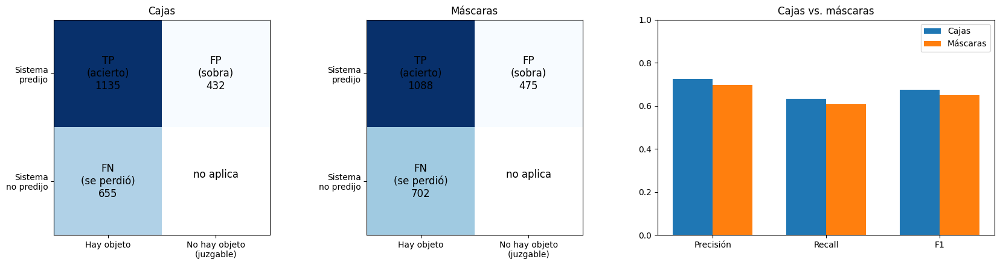

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), gridspec_kw={'width_ratios': [1, 1, 1.3]})
for ax, nombre, mm in zip(axes[:2], ['Cajas', 'Máscaras'], [m_caja, m_masc]):
    M = np.array([[mm['TP'], mm['FP']], [mm['FN'], np.nan]])
    ax.imshow(np.ma.masked_invalid(M), cmap='Blues')
    etiquetas = [['TP\n(acierto)', 'FP\n(sobra)'], ['FN\n(se perdió)', 'no aplica']]
    for (i, j), v in np.ndenumerate(M):
        ax.text(j, i, f"{etiquetas[i][j]}\n{'' if np.isnan(v) else int(v)}",
                ha='center', va='center', fontsize=12)
    ax.set_xticks([0, 1]); ax.set_xticklabels(['Hay objeto', 'No hay objeto\n(juzgable)'])
    ax.set_yticks([0, 1]); ax.set_yticklabels(['Sistema\npredijo', 'Sistema\nno predijo'])
    ax.set_title(nombre)

x = np.arange(3); w = 0.35
ax = axes[2]
ax.bar(x - w / 2, [m_caja[k] for k in ('precision', 'recall', 'f1')], w, label='Cajas')
ax.bar(x + w / 2, [m_masc[k] for k in ('precision', 'recall', 'f1')], w, label='Máscaras')
ax.set_xticks(x); ax.set_xticklabels(['Precisión', 'Recall', 'F1']); ax.set_ylim(0, 1)
ax.legend(); ax.set_title('Cajas vs. máscaras')
plt.tight_layout(); plt.show()

## B.8 · Recall según tamaño del objeto

¿Falla más en objetos chicos? Recall de cajas y de máscaras por tamaño (cortes provisorios 1 % y 10 % del área de la imagen).

         cajas  máscaras
tamaño                  
small   0.5816    0.5446
medium  0.7060    0.7025
large   0.7202    0.6845


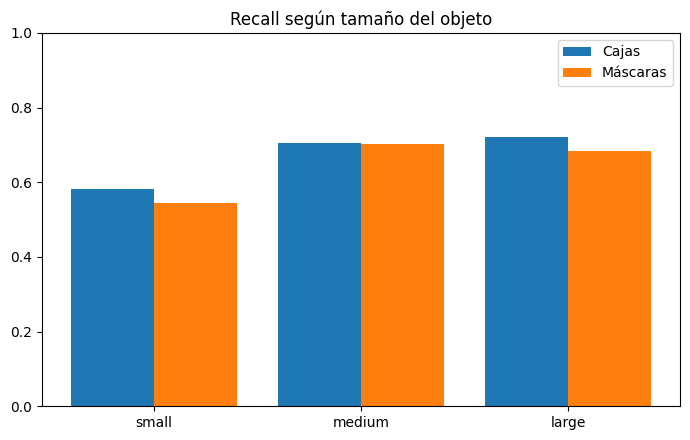

In [33]:
orden = ['small', 'medium', 'large']
for d_ in (gc, gm):
    d_['tamaño'] = pd.cut(d_['rel_area'], [0, 0.01, 0.10, 1], labels=orden)   # umbrales provisorios
rc = gc.groupby('tamaño', observed=True)['detectado'].mean().reindex(orden)
rm = gm.groupby('tamaño', observed=True)['detectado'].mean().reindex(orden)
print(pd.DataFrame({'cajas': rc, 'máscaras': rm}).round(4))

fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(3)
ax.bar(x - 0.2, rc, 0.4, label='Cajas'); ax.bar(x + 0.2, rm, 0.4, label='Máscaras')
ax.set_xticks(x); ax.set_xticklabels(orden); ax.set_ylim(0, 1); ax.legend()
ax.set_title('Recall según tamaño del objeto')
plt.tight_layout(); plt.show()

## B.9 · Casi aciertos

Falsos positivos con IoU de máscara entre 0,2 y 0,5: máscara predicha (rojo) contra la anotada (verde).

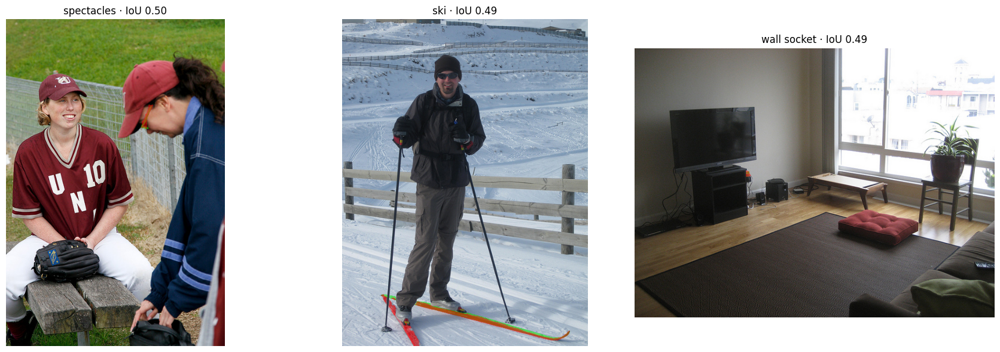

In [34]:
casi = pm[(pm['estado'] == 'FP') & (pm['mask_iou'].between(0.2, 0.5))].sort_values('mask_iou', ascending=False)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (_, r) in zip(axes, casi.head(3).iterrows()):
    im = Image.open(paths[img_name(img_info[r['image_id']])]).convert('RGB')
    canvas = np.array(im).astype(float)
    mp = mask_utils.decode(rles[r['image_id']][int(r['idx'])]).astype(bool)
    mg = mask_utils.decode(gt_rle[r['image_id']][r['category_id']][int(r['gt_j'])]).astype(bool)
    canvas[mg] = 0.5 * canvas[mg] + 0.5 * np.array([0, 255, 0])
    canvas[mp] = 0.5 * canvas[mp] + 0.5 * np.array([255, 0, 0])
    ax.imshow(canvas.astype(np.uint8)); ax.axis('off')
    ax.set_title(f"{r['category']} · IoU {r['mask_iou']:.2f}")
plt.tight_layout(); plt.show()

## B.10 · Tipos de falsos positivos de máscaras

Se separan en: confunden categoría (la máscara calza con un objeto anotado de otra categoría), misma categoría mal recortada, y sin relación con lo anotado.

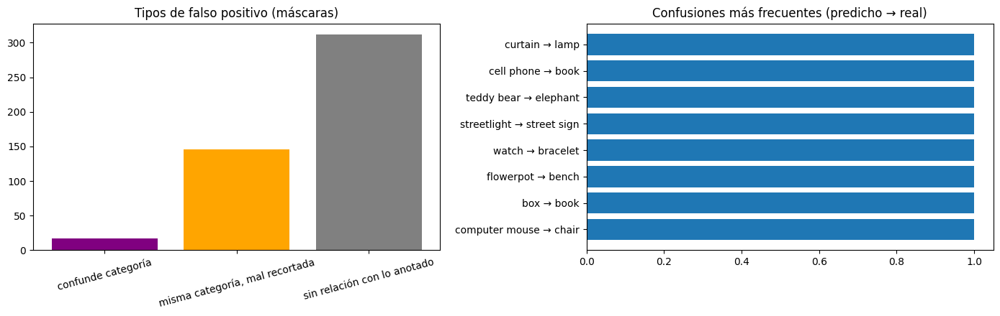

{'confunde categoría': 17, 'misma categoría, mal recortada': 146, 'sin relación con lo anotado': 312}


In [35]:
tipos = {'confunde categoría': 0, 'misma categoría, mal recortada': 0, 'sin relación con lo anotado': 0}
pares = []
for _, r in pm[pm['estado'] == 'FP'].iterrows():
    cand = [(c, g) for c, lst in gt_rle.get(r['image_id'], {}).items() for g in lst]
    mejor, cat_g = 0.0, None
    if cand:
        ious = mask_utils.iou([rles[r['image_id']][int(r['idx'])]], [g for _, g in cand], [0] * len(cand))[0]
        j = int(np.argmax(ious)); mejor, cat_g = float(ious[j]), cand[j][0]
    if mejor >= 0.5 and cat_g != r['category_id']:
        tipos['confunde categoría'] += 1
        pares.append(f"{r['category']} → {cat_name[cat_g]}")
    elif r['mask_iou'] > 0.1:
        tipos['misma categoría, mal recortada'] += 1
    else:
        tipos['sin relación con lo anotado'] += 1

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].bar(list(tipos), list(tipos.values()), color=['purple', 'orange', 'gray'])
ax[0].set_title('Tipos de falso positivo (máscaras)'); ax[0].tick_params(axis='x', labelrotation=15)
if pares:
    top = pd.Series(pares).value_counts().head(8)
    ax[1].barh(top.index[::-1], top.values[::-1]); ax[1].set_title('Confusiones más frecuentes (predicho → real)')
plt.tight_layout(); plt.show()
print(tipos)

# Parte C · Representación estructurada de la escena (consigna 4)

Las partes A y B ya producen detecciones y máscaras predichas. Ahora las convertimos en una ficha por imagen: `image`, `objects` y `relations`. Esta parte recibe `filtradas` y `rles`, alineadas por imagen; **no consulta cajas, máscaras ni categorías presentes del ground truth**. El nombre del archivo identifica la imagen y Pillow aporta sus dimensiones reales.

Alcance: SceneJSON de las 120 imágenes de desarrollo. Las mismas funciones construyen las escenas de test en la Parte D.

## C.1 · Convenciones y propiedades desde la máscara

- `bbox`: envolvente de la máscara en píxeles, `[xmin, ymin, xmax, ymax]`, con xmax e ymax exclusivos (una máscara de un píxel en (0, 0) da `[0, 0, 1, 1]`).
- `centroid`: `[cx, cy]`, promedio de las coordenadas de los píxeles de la máscara, con origen `(0, 0)` arriba a la izquierda.
- `area_ratio`: píxeles de la máscara / píxeles de la imagen. No se usa el área de la caja.
- `position`: centroide en una grilla de tercios. Una frontera exacta pertenece a la zona de la derecha o de abajo.
- `size`: `small` si el área relativa es ≤ 1 %, `medium` si es > 1 % y ≤ 10 %, y `large` si supera 10 %. Son decisiones del grupo, no umbrales oficiales.
- `color` y `color_fraction` (atributo; el esquema admite campos extra): cada píxel de la máscara se clasifica en uno de 11 colores básicos según su tono, saturación y brillo (HSV) y se guarda el color con más píxeles y qué fracción de la máscara ocupa.
  - **Por qué votar por píxel y no promediar el RGB:** el promedio de un objeto rojo y blanco da un rosa que no está en el objeto; el voto devuelve un color que sí está.
  - **Por qué HSV:** separa el tono del brillo, así una sombra sobre un objeto rojo sigue siendo roja. Los umbrales de blanco, gris y negro son heurísticos (decisión del grupo).
  - `color_fraction` baja indica un objeto multicolor o una máscara que incluye fondo; el motor la usa para bajar la confianza de la respuesta.
- Clase y confianza vienen del detector. La máscara se guarda como RLE sin comprimir column-major usando la conversión de B.6. Los ids `obj_0001`, ... son únicos dentro de cada escena y siguen el orden recibido de B.4.

Las cajas de A siguen siendo las del detector; las cajas del SceneJSON se derivan de SAM2. Por eso el F1 histórico de A no es una nueva medición de estas cajas derivadas.

In [36]:
# El esquema completo conserva sus $defs y referencias internas.
Draft202012Validator.check_schema(schema)
val_scene = Draft202012Validator(schema)
MAX_OBJ_SCENE = schema['properties']['objects']['maxItems']
MAX_REL_SCENE = schema['properties']['relations']['maxItems']
SIZE_SMALL, SIZE_MEDIUM = 0.01, 0.10
REGIONES = (
    ('top_left', 'top_center', 'top_right'),
    ('middle_left', 'center', 'middle_right'),
    ('bottom_left', 'bottom_center', 'bottom_right'),
)


def posicion_scene(cx, cy, ancho, alto):
    columna = min(2, int(3 * cx / ancho))
    fila = min(2, int(3 * cy / alto))
    return REGIONES[fila][columna]


def tamanio_scene(area_ratio):
    if area_ratio <= SIZE_SMALL:
        return 'small'
    return 'medium' if area_ratio <= SIZE_MEDIUM else 'large'


def propiedades_mascara(mask):
    """Geometría calculada exclusivamente desde una máscara binaria (H, W)."""
    if mask.ndim != 2 or not mask.any():
        raise ValueError('La máscara debe ser bidimensional y no vacía')
    alto, ancho = mask.shape
    ys, xs = np.nonzero(mask)
    cx, cy = float(xs.mean()), float(ys.mean())
    area_ratio = float(len(xs) / (alto * ancho))
    return dict(
        bbox=[int(xs.min()), int(ys.min()),
              int(xs.max()) + 1, int(ys.max()) + 1],      # [xmin, ymin, xmax, ymax]; xmax e ymax exclusivos
        centroid=[cx, cy], area_ratio=area_ratio,
        position=posicion_scene(cx, cy, ancho, alto), size=tamanio_scene(area_ratio))


def decodificar_prediccion(rle, ancho, alto):
    """Admite el RLE de B.4 y el RLE sin comprimir, sin modificar la entrada."""
    if list(rle['size']) != [alto, ancho]:
        raise ValueError('La máscara no coincide con las dimensiones reales de la imagen')
    if isinstance(rle['counts'], list):
        errores = chequear_mascara(rle, alto, ancho)
        if errores:
            raise ValueError('; '.join(errores))
        rle = mask_utils.frPyObjects(rle, alto, ancho)
    mask = mask_utils.decode(rle).astype(bool)
    if mask.shape != (alto, ancho):
        raise ValueError('La máscara decodificada tiene dimensiones incorrectas')
    return mask


COLORES = ('red', 'orange', 'yellow', 'green', 'blue', 'purple', 'pink', 'brown', 'black', 'white', 'gray')
LIMITES_TONO = np.array([11, 25, 46, 120, 185, 213, 241, 256])     # tono H de PIL (0-255), límite superior
TONOS = np.array(['red', 'orange', 'yellow', 'green', 'blue', 'purple', 'pink', 'red'], dtype=object)


def nombre_color_pixeles(h, s, v):
    """Un nombre de color por píxel a partir de H, S y V (0-255)."""
    nombre = TONOS[np.searchsorted(LIMITES_TONO, h, side='right')]
    nombre[(nombre == 'orange') & (v < 170)] = 'brown'                 # naranja oscuro
    gris = s < 40
    nombre[gris] = np.where(v[gris] > 200, 'white', 'gray')
    nombre[v < 50] = 'black'
    return nombre


def color_dominante(hsv, mask):
    """Color con más píxeles dentro de la máscara y la fracción de la máscara que ocupa."""
    h, s, v = (hsv[..., k][mask].astype(int) for k in range(3))
    valores, cuentas = np.unique(nombre_color_pixeles(h, s, v).astype(str), return_counts=True)
    k = int(np.argmax(cuentas))
    return str(valores[k]), round(float(cuentas[k] / cuentas.sum()), 4)

## C.2 · Relaciones espaciales

`left_of` / `right_of` comparan la coordenada horizontal de los centroides; `above` / `below`, la vertical. Si las coordenadas son iguales, no se agrega una relación sobre ese eje. `overlaps` significa que **las máscaras comparten al menos un píxel**, aunque sus centroides coincidan. No implica profundidad ni que un objeto esté físicamente delante de otro.

Cada relación se guarda junto con su inversa. Para respetar el máximo del esquema, los pares se recorren de menor a mayor distancia entre centroides, normalizada por ancho y alto, con desempate por orden de objeto. Se conserva un par solo si entran todas sus relaciones. Los descartes quedan contabilizados en `derivation`: si hay recorte, la ausencia de una relación no demuestra que sea falsa.

In [37]:
def relaciones_scene(objetos, mascaras_coco, ancho, alto, limite=MAX_REL_SCENE):
    if not isinstance(limite, int) or isinstance(limite, bool) or limite < 0:
        raise ValueError('El límite de relaciones debe ser un entero no negativo')
    limite = min(limite, MAX_REL_SCENE)
    n = len(objetos)
    overlaps = (mask_utils.iou(mascaras_coco, mascaras_coco, [0] * n) > 0
                if n else np.zeros((0, 0), dtype=bool))
    pares = []
    for i in range(n):
        xi, yi = objetos[i]['centroid']
        for j in range(i + 1, n):
            xj, yj = objetos[j]['centroid']
            distancia = ((xi - xj) / ancho) ** 2 + ((yi - yj) / alto) ** 2
            pares.append((distancia, i, j))

    relaciones, total = [], 0
    for _, i, j in sorted(pares):
        a, b = objetos[i], objetos[j]
        xa, ya = a['centroid']; xb, yb = b['centroid']
        predicados = []
        if xa != xb:
            predicados.append(('left_of', 'right_of') if xa < xb else ('right_of', 'left_of'))
        if ya != yb:
            predicados.append(('above', 'below') if ya < yb else ('below', 'above'))
        if overlaps[i, j]:
            predicados.append(('overlaps', 'overlaps'))
        grupo = []
        for directo, inverso in predicados:
            grupo.extend([
                dict(subject=a['id'], predicate=directo, object=b['id']),
                dict(subject=b['id'], predicate=inverso, object=a['id']),
            ])
        total += len(grupo)
        if len(relaciones) + len(grupo) <= limite:
            relaciones.extend(grupo)
    return relaciones, dict(relations_total=total,
                             relations_omitted=total - len(relaciones),
                             relations_complete=(total == len(relaciones)))

## C.3 · Validación del esquema y de la consistencia

El esquema controla estructura, tipos, rangos y límites. Agregamos lo que no alcanza a verificar: ids únicos, dimensiones y suma de runs, máscara no vacía, geometría coherente con la máscara y relaciones sin duplicados, autorreferencias ni ids inexistentes. También comprobamos que cada relación esté sustentada y tenga su inversa, y que la `evidence` de `questions` y `questions_llm` apunte a ids existentes: una referencia inexistente invalida la fila entera en Kaggle. La serialización estricta impide guardar NaN o infinitos.

In [38]:
def validar_scenejson(scene):
    try:
        json.dumps(scene, allow_nan=False)
    except (ValueError, TypeError) as exc:
        return [f'JSON no serializable: {exc}']
    errores = [f"{'/'.join(map(str, e.absolute_path)) or 'raíz'}: {e.message}"
               for e in val_scene.iter_errors(scene)]
    if errores:
        return errores

    ancho, alto = scene['image']['width'], scene['image']['height']
    ids = [o['id'] for o in scene['objects']]
    if len(set(ids)) != len(ids):
        errores.append('Los ids de objetos deben ser únicos')
    mascaras_coco = []
    for obj in scene['objects']:
        etiqueta = obj['id']
        problemas = chequear_mascara(obj['mask'], alto, ancho)
        if problemas:
            errores.extend(f'{etiqueta}/mask: {e}' for e in problemas)
            continue
        try:
            coco = mask_utils.frPyObjects(obj['mask'], alto, ancho)
            mask = mask_utils.decode(coco).astype(bool)
            esperado = propiedades_mascara(mask)
        except Exception as exc:
            errores.append(f'{etiqueta}/mask: {type(exc).__name__}: {exc}')
            continue
        mascaras_coco.append(coco)
        for campo in ('bbox', 'centroid', 'area_ratio'):
            if not np.allclose(obj[campo], esperado[campo], rtol=1e-9, atol=1e-9):
                errores.append(f'{etiqueta}/{campo}: no coincide con la máscara')
        for campo in ('position', 'size'):
            if obj[campo] != esperado[campo]:
                errores.append(f'{etiqueta}/{campo}: no coincide con la máscara')
        x0, y0, x1, y1 = obj['bbox']
        if not (0 <= x0 < x1 <= ancho and 0 <= y0 < y1 <= alto):
            errores.append(f'{etiqueta}/bbox: debe cumplir 0 <= xmin < xmax <= ancho y 0 <= ymin < ymax <= alto')
    if errores:
        return errores

    objetos = {o['id']: o for o in scene['objects']}
    for campo in ('questions', 'questions_llm'):
        for q in scene.get(campo, []):
            faltan = [e for e in q['evidence'] if e not in objetos]
            if faltan:
                errores.append(f"{campo}/{q['question_id']}: evidencia inexistente {faltan}")
    indices = {oid: i for i, oid in enumerate(ids)}
    triples = [(r['subject'], r['predicate'], r['object']) for r in scene['relations']]
    conjunto = set(triples)
    if len(conjunto) != len(triples):
        errores.append('Hay relaciones duplicadas')
    inversa = dict(left_of='right_of', right_of='left_of', above='below',
                   below='above', overlaps='overlaps')
    n = len(objetos)
    overlaps = (mask_utils.iou(mascaras_coco, mascaras_coco, [0] * n) > 0
                if n else np.zeros((0, 0), dtype=bool))
    for sujeto, predicado, objeto in triples:
        if sujeto not in objetos or objeto not in objetos:
            errores.append(f'Relación con id inexistente: {(sujeto, predicado, objeto)}')
            continue
        if sujeto == objeto:
            errores.append(f'Autorrelación: {(sujeto, predicado, objeto)}')
            continue
        xa, ya = objetos[sujeto]['centroid']; xb, yb = objetos[objeto]['centroid']
        verdadera = dict(left_of=xa < xb, right_of=xa > xb, above=ya < yb,
                          below=ya > yb, overlaps=bool(overlaps[indices[sujeto], indices[objeto]]))
        if not verdadera[predicado]:
            errores.append(f'Relación no sustentada: {(sujeto, predicado, objeto)}')
        if (objeto, inversa[predicado], sujeto) not in conjunto:
            errores.append(f'Relación sin inversa: {(sujeto, predicado, objeto)}')
    return errores


def construir_scenejson(image_id, ancho, alto, detecciones, mascaras_rle, pixeles=None):
    """Solo recibe predicciones, metadatos y píxeles de la imagen; no usa anotaciones."""
    if not isinstance(image_id, str) or not image_id.strip():
        raise ValueError('image_id debe ser un texto no vacío')
    if any(isinstance(v, (bool, np.bool_)) or not isinstance(v, (int, np.integer))
           or v <= 0 for v in (ancho, alto)):
        raise ValueError('Ancho y alto deben ser enteros positivos')
    ancho, alto = int(ancho), int(alto)
    if len(detecciones) != len(mascaras_rle):
        raise ValueError('Las detecciones y las máscaras no están alineadas')
    if len(detecciones) > MAX_OBJ_SCENE:
        raise ValueError(f'Se superó el máximo de {MAX_OBJ_SCENE} objetos de B.4')

    hsv = None
    if pixeles is not None:
        if pixeles.shape != (alto, ancho, 3):
            raise ValueError('Los píxeles no coinciden con ancho y alto')
        hsv = np.asarray(Image.fromarray(pixeles).convert('HSV'))

    objetos, mascaras_coco = [], []
    for indice, (det, rle) in enumerate(zip(detecciones, mascaras_rle), 1):
        categoria = det['category_id']
        if isinstance(categoria, (bool, np.bool_)) or not isinstance(categoria, (int, np.integer)):
            raise ValueError('category_id debe ser un entero')
        mask = decodificar_prediccion(rle, ancho, alto)
        objeto = dict(id=f'obj_{indice:04d}', category_id=int(categoria),
                      confidence=float(det['score']), mask=rle_esquema(mask),
                      **propiedades_mascara(mask))
        if det.get('category'):
            objeto['category'] = det['category']
        if hsv is not None:
            objeto['color'], objeto['color_fraction'] = color_dominante(hsv, mask)
        objetos.append(objeto)
        mascaras_coco.append(mask_utils.encode(np.asfortranarray(mask.astype(np.uint8))))
    relaciones, detalle = relaciones_scene(objetos, mascaras_coco, ancho, alto)
    scene = dict(image=dict(id=image_id, width=ancho, height=alto),
                 objects=objetos, relations=relaciones, generation_status='ok',
                 derivation=dict(bbox_format='xyxy_end_exclusive', centroid_format='xy_pixels',
                                 size_thresholds=[SIZE_SMALL, SIZE_MEDIUM],
                                 relation_selection='nearest_centroids_complete_pairs',
                                 color_method='voto_por_pixel_hsv' if hsv is not None else None,
                                 **detalle))
    errores = validar_scenejson(scene)
    if errores:
        raise ValueError('; '.join(errores))
    return scene


def scenejson_seguro(image_id, ancho, alto, detecciones, mascaras_rle, pixeles=None):
    """Un fallo de predicciones deja una escena vacía válida y un error visible."""
    try:
        scene = construir_scenejson(image_id, ancho, alto, detecciones, mascaras_rle, pixeles)
        return scene, []
    except Exception as exc:
        vacia = dict(image=dict(id=image_id, width=ancho, height=alto),
                     objects=[], relations=[], generation_status='error')
        errores_vacia = validar_scenejson(vacia)
        if errores_vacia:
            raise ValueError('No se puede construir una escena de respaldo válida: '
                             + '; '.join(errores_vacia)) from exc
        return vacia, [f'{type(exc).__name__}: {exc}']

## C.4 · SceneJSON de desarrollo y artefactos

Esta celda se ejecuta **después de B.4** y usa sus predicciones, sin volver a llamar a los modelos. Se leen únicamente nombre y dimensiones de la imagen, nunca sus anotaciones de objetos. Si las predicciones de una imagen fallan, se guarda una escena vacía validada con `generation_status='error'` y se conserva la causa en el informe; eso no demuestra que la imagen carezca de objetos. Si falta el archivo de imagen o no se pueden leer sus dimensiones, se interrumpe para no inventarlas.

Salidas en `/kaggle/working` (o `outputs/` local):

- `scenejson_dev.jsonl`: un SceneJSON completo por imagen, incluidas las máscaras. Permite continuar trabajando sin volver a usar GPU.
- `scenejson_validacion.json`: configuración geométrica, recuentos y errores por imagen. Las escenas de respaldo se cuentan por separado; pasar el esquema no equivale a una inferencia exitosa.

Las relaciones omitidas por el límite también se informan. Cada imagen deja un evento `scenejson` en la traza. `questions` y `questions_llm` se agregan en las Partes E y F, y el envío se arma en la Parte I.

In [39]:
if set(filtradas) != set(img_info) or set(rles) != set(img_info):
    raise ValueError('Faltan predicciones de desarrollo: ejecutar las partes A y B completas')

scenejsons, controles_scene = {}, []
for img_id, info in img_info.items():
    nombre = img_name(info)                        # solo el nombre, no las etiquetas
    image_id = Path(nombre).stem                  # tpi_0001, no el id entero de evaluación
    if image_id in scenejsons:
        raise ValueError(f'Identificador de imagen repetido: {image_id}')
    with Image.open(paths[nombre]) as imagen:
        pixeles = np.asarray(imagen.convert('RGB'))   # dimensiones reales y colores; no etiquetas
    alto, ancho = pixeles.shape[:2]
    with traza_dev.etapa(image_id, 'scenejson', size_thresholds=[SIZE_SMALL, SIZE_MEDIUM]) as paso:
        scene, errores = scenejson_seguro(image_id, ancho, alto, filtradas[img_id], rles[img_id], pixeles)
        paso['artefactos'].update(objetos=len(scene['objects']), relaciones=len(scene['relations']))
        if errores:
            paso['estado'], paso['error'] = 'respaldo', errores[0]
    scenejsons[image_id] = scene
    controles_scene.append(dict(
        image_id=image_id, estado=scene['generation_status'], errores=errores,
        objetos=len(scene['objects']), relaciones=len(scene['relations']),
        relaciones_omitidas=scene.get('derivation', {}).get('relations_omitted', 0)))

resumen_scene = dict(
    imagenes=len(scenejsons),
    objetos=sum(c['objetos'] for c in controles_scene),
    relaciones=sum(c['relaciones'] for c in controles_scene),
    imagenes_con_error=sum(c['estado'] == 'error' for c in controles_scene),
    relaciones_omitidas=sum(c['relaciones_omitidas'] for c in controles_scene))
politica_scene = dict(
    bbox='xyxy_pixels_fin_exclusivo', centroid='xy_pixels',
    position='centroide_en_tercios; frontera_derecha_o_abajo',
    size_thresholds=[SIZE_SMALL, SIZE_MEDIUM],
    overlaps='interseccion_de_mascaras_mayor_a_cero',
    relation_selection='nearest_centroids_complete_pairs',
    max_objects=MAX_OBJ_SCENE, max_relations=MAX_REL_SCENE)

with (OUT_DIR / 'scenejson_dev.jsonl').open('w', encoding='utf-8') as f:
    for scene in scenejsons.values():
        f.write(json.dumps(scene, ensure_ascii=False, allow_nan=False) + '\n')
with (OUT_DIR / 'scenejson_validacion.json').open('w', encoding='utf-8') as f:
    json.dump(dict(resumen=resumen_scene, politica=politica_scene, imagenes=controles_scene),
              f, ensure_ascii=False, indent=2, allow_nan=False)
print('Resultado SceneJSON:', resumen_scene)
print('Archivos guardados en:', OUT_DIR)
print('Escenas de respaldo (requieren revisión):',
      [c['image_id'] for c in controles_scene if c['estado'] == 'error'])

Resultado SceneJSON: {'imagenes': 120, 'objetos': 4092, 'relaciones': 382428, 'imagenes_con_error': 0, 'relaciones_omitidas': 6436}
Archivos guardados en: /kaggle/working
Escenas de respaldo (requieren revisión): []


## C.5 · Inspección de una escena

La tabla permite ver lo que antes eran máscaras sueltas convertido en objetos con propiedades. La máscara completa permanece en el archivo; se omite de la tabla para que sea legible. El ejemplo se elige automáticamente entre las escenas con objetos, sin consultar ground truth.

In [40]:
ejemplo_scene = next((s for s in scenejsons.values() if s['objects']), None)
if ejemplo_scene is not None:
    print('Imagen:', ejemplo_scene['image'])
    display(pd.DataFrame([{k: v for k, v in o.items() if k != 'mask'}
                          for o in ejemplo_scene['objects']]).head(10))
    print('Primeras relaciones:', ejemplo_scene['relations'][:10])
    print('Errores de validación:', validar_scenejson(ejemplo_scene))
else:
    print('No hay escenas con objetos; revisar el resumen de validación anterior.')

Imagen: {'id': 'tpi_0001', 'width': 480, 'height': 640}


,id,category_id,confidence,bbox,centroid,area_ratio,position,size,category,color,color_fraction
0,obj_0001,19,0.6695,"[67, 477, 126, 592]","[95.85479632063075, 532.9797963206307]",0.019818,bottom_left,medium,trash can,gray,0.7446
1,obj_0002,11,0.6416,"[159, 392, 229, 400]","[193.61016949152543, 395.15466101694915]",0.001536,center,small,handle,yellow,0.9322
2,obj_0003,11,0.6248,"[259, 391, 330, 399]","[293.6046065259117, 394.4740882917466]",0.001696,center,small,handle,yellow,0.8810
3,obj_0004,67,0.5747,"[126, 193, 149, 211]","[137.1608040201005, 201.45979899497488]",0.001296,top_left,small,wall socket,gray,0.5327
4,obj_0005,86,0.5697,"[149, 35, 345, 231]","[246.0964957104053, 133.3868703439744]",0.121038,top_center,large,mirror,gray,0.3685
5,obj_0006,41,0.5529,"[240, 306, 253, 325]","[245.79227053140096, 315.65700483091786]",0.000674,center,small,faucet,brown,0.3478
6,obj_0007,62,0.5508,"[245, 380, 372, 408]","[308.5676945668135, 393.3453744493392]",0.011084,center,medium,drawer,yellow,0.9721
7,obj_0008,62,0.5304,"[118, 381, 243, 435]","[179.93870321885106, 407.5912521176652]",0.021136,center,medium,drawer,yellow,0.9658
8,obj_0009,89,0.5195,"[109, 311, 380, 361]","[244.71935020642613, 337.672859450727]",0.036270,center,medium,sink,brown,0.5879
9,obj_0010,41,0.5174,"[204, 308, 220, 326]","[211.0632911392405, 316.8691983122363]",0.000771,center,small,faucet,brown,0.3418


Primeras relaciones: [{'subject': 'obj_0010', 'predicate': 'overlaps', 'object': 'obj_0027'}, {'subject': 'obj_0027', 'predicate': 'overlaps', 'object': 'obj_0010'}, {'subject': 'obj_0011', 'predicate': 'left_of', 'object': 'obj_0015'}, {'subject': 'obj_0015', 'predicate': 'right_of', 'object': 'obj_0011'}, {'subject': 'obj_0011', 'predicate': 'below', 'object': 'obj_0015'}, {'subject': 'obj_0015', 'predicate': 'above', 'object': 'obj_0011'}, {'subject': 'obj_0011', 'predicate': 'overlaps', 'object': 'obj_0015'}, {'subject': 'obj_0015', 'predicate': 'overlaps', 'object': 'obj_0011'}, {'subject': 'obj_0004', 'predicate': 'right_of', 'object': 'obj_0028'}, {'subject': 'obj_0028', 'predicate': 'left_of', 'object': 'obj_0004'}]
Errores de validación: []


# Parte D · Pipeline para una imagen, test y traza

## D.1 · Pipeline para una sola imagen

`escena_desde_imagen` encadena todas las etapas para **una imagen arbitraria**: solo recibe la ruta del archivo, sin anotaciones (condición de validez; se puede pedir en la defensa). Cada etapa deja un evento en la traza que se le pase.

**Por qué una función por imagen además de los lotes de A y B:** los lotes sirven para experimentar sin repetir GPU (las detecciones crudas se guardan una vez). La función por imagen es la que demuestra que la inferencia no depende del dataset de desarrollo. El control de abajo comprueba que las dos producen lo mismo.

**Manejo de errores:** si falla una etapa después de leer la imagen, se registra el error en la traza y se entrega una escena vacía con `generation_status='error'`, para que el CSV siga siendo válido y el fallo quede visible. Si no se puede leer la imagen, se corta: no se inventan dimensiones.

In [41]:
@torch.no_grad()
def escena_desde_imagen(ruta, traza):
    """Pipeline completo para UNA imagen. Recibe solo el archivo: no lee anotaciones."""
    stem = Path(ruta).stem
    with traza.etapa(stem, 'carga') as paso:
        with Image.open(ruta) as im:
            imagen = im.convert('RGB')
        ancho, alto = imagen.size
        paso['artefactos'].update(ancho=ancho, alto=alto)
    try:
        with traza.etapa(stem, 'deteccion', modelo=MODEL_ID, umbral_crudo=RAW_THR, grilla=GRILLA,
                         solape=SOLAPE, margen=MARGEN) as paso:
            crudas = detectar_final(imagen, RAW_THR)
            paso['artefactos']['detecciones_crudas'] = len(crudas)
        with traza.etapa(stem, 'filtrado', umbral=UMBRAL, nms_iou=NMS_IOU, postproceso=POSTPROCESO,
                         max_objetos=MAX_OBJ) as paso:
            dets = sorted(filtrar(crudas, UMBRAL, NMS_IOU), key=lambda d: -d['score'])[:MAX_OBJ]
            paso['artefactos'].update(entrada=len(crudas), salida=len(dets))
        with traza.etapa(stem, 'segmentacion', modelo=SAM_ID, chunk=16) as paso:
            keep_d, keep_r = [], []
            for d, m_ in zip(dets, segmentar(imagen, dets)):
                if m_.any():                                   # descarta máscaras vacías
                    keep_d.append(d)
                    keep_r.append(mask_utils.encode(np.asfortranarray(m_.astype(np.uint8))))
            paso['artefactos'].update(cajas=len(dets), mascaras=len(keep_r), vacias=len(dets) - len(keep_r))
        with traza.etapa(stem, 'scenejson', size_thresholds=[SIZE_SMALL, SIZE_MEDIUM]) as paso:
            escena, errores = scenejson_seguro(stem, ancho, alto, keep_d, keep_r, np.asarray(imagen))
            paso['artefactos'].update(objetos=len(escena['objects']), relaciones=len(escena['relations']))
            if errores:
                paso['estado'], paso['error'] = 'respaldo', errores[0]
        return escena, errores
    except Exception as exc:
        vacia = dict(image=dict(id=stem, width=ancho, height=alto), objects=[], relations=[],
                     generation_status='error')
        return vacia, [f'{type(exc).__name__}: {exc}']

# Control: debe reproducir lo ya obtenido para desarrollo (la cantidad de objetos debería coincidir)
for nombre in ['tpi_0001.jpg', 'tpi_0002.jpg', 'tpi_0003.jpg']:
    escena, errs = escena_desde_imagen(paths[nombre], Traza('control'))
    previa = scenejsons[Path(nombre).stem]
    print(nombre, '| objetos:', len(escena['objects']), 'vs', len(previa['objects']), '| errores:', errs)

tpi_0001.jpg | objetos: 30 vs 30 | errores: []
tpi_0002.jpg | objetos: 31 vs 31 | errores: []
tpi_0003.jpg | objetos: 24 vs 24 | errores: []


## D.2 · Imágenes de test

Las 60 imágenes de test pasan por la misma función, con su propia traza.

In [42]:
test_rutas = sorted(p for n, p in paths.items() if n.startswith('test_'))
print('Imágenes de test encontradas:', len(test_rutas))        # esperado: 60

scenes_test, errores_test = {}, {}
t0 = time.time()
for k, ruta in enumerate(test_rutas):
    escena, errs = escena_desde_imagen(ruta, traza_test)
    scenes_test[ruta.stem] = escena
    if errs:
        errores_test[ruta.stem] = errs
    if k % 10 == 0:
        print(k, f'{time.time() - t0:.0f}s')
print('Con error:', errores_test)

Imágenes de test encontradas: 60
0 5s
10 53s
20 101s
30 148s
40 203s
50 255s
Con error: {}


## D.3 · Resumen de la traza de percepción

Tiempo por etapa, estados y errores. En desarrollo las etapas corrieron en lotes (A.5, B.1, B.4, C.4) y en test por imagen (D.2); las dos quedan en el mismo formato. Las preguntas se agregan a la traza en E y F, y todo se guarda en la Parte I.

In [43]:
tr = pd.concat([traza_dev.tabla(), traza_test.tabla()], ignore_index=True)
display(tr.groupby(['traza', 'etapa'], sort=False)['segundos'].agg(['count', 'mean', 'sum']).round(3))
display(pd.crosstab([tr['traza'], tr['etapa']], tr['estado']))
problemas_traza = tr[tr['estado'] != 'ok']
print(problemas_traza[['traza', 'imagen', 'etapa', 'estado', 'error']] if len(problemas_traza) else 'Sin errores ni respaldos')

count   mean      sum
traza      etapa                              
desarrollo deteccion       120  2.354  282.490
           filtrado        120  0.000    0.029
           segmentacion    120  2.317  278.098
           scenejson       120  0.387   46.429
test       carga            60  0.016    0.968
           deteccion        60  2.441  146.476
           filtrado         60  0.000    0.016
           segmentacion     60  2.274  136.469
           scenejson        60  0.356   21.370

estado                    ok
traza      etapa            
desarrollo deteccion     120
           filtrado      120
           scenejson     120
           segmentacion  120
test       carga          60
           deteccion      60
           filtrado       60
           scenejson      60
           segmentacion   60

Sin errores ni respaldos


# Parte E · Motor determinista de consultas

Arquitectura común a los dos modos, como pide la consigna:

`pregunta → JSON intermedio validado → ejecución determinista sobre el SceneJSON → respuesta normalizada + verbalización`

- **Modo determinista (`questions`):** el JSON intermedio se arma con los campos estructurados de la consigna (`type`, `class_en`, `class_es`). El predicado de las relaciones se lee del texto con expresiones regulares. La respuesta en lenguaje natural sale de plantillas.
- **Modo LLM (`questions_llm`, Parte F):** el JSON intermedio lo genera el LLM a partir **solo del texto** de la pregunta, y el LLM redacta la respuesta a partir de los hechos que devuelve el motor (nunca ve la imagen).
- En los dos modos, la misma función `ejecutar_consulta` hace conteos, filtros y comparaciones con código, leyendo únicamente el SceneJSON predicho.

**Por qué un JSON intermedio común:**
- Garantiza por construcción que el LLM no calcula la respuesta: lo único que puede producir es una consulta, y la consulta se valida antes de ejecutarse.
- Los dos modos se pueden comparar con las mismas métricas: si fallan distinto, la diferencia está en la interpretación, no en el motor.
- La respuesta se puede auditar contra el JSON (fidelidad, E.4).

## E.1 · El JSON intermedio

| Campo | Valores | Quién lo decide |
|---|---|---|
| `intent` | `description`, `count`, `existence`, `position`, `size`, `color`, `relation`, `compare_count`, `compare_size`, `unsupported` | el LLM (modo LLM) o el `type` de la consigna (determinista) |
| `targets` | 0, 1 o 2 objetos `{mention, color}` | el LLM: `mention` es la **copia literal** de las palabras de la pregunta que nombran el objeto; `color` es un filtro opcional |
| `relation` | `left_of`, `right_of`, `above`, `below`, `overlaps` o `null` | el LLM (solo en relaciones) |
| `output` | `integer`, `yes_no`, `region`, `size_label`, `color`, `text`, `none` | **el código**, como función de `intent` |

En el modo determinista cada `target` lleva además `category` (el `class_en` de la consigna). **En el modo LLM `category` está prohibida**: el LLM no elige categorías, solo copia menciones; qué categoría es la decide el código (F.4).

Además del esquema (`jsonschema`), se valida la coherencia: cantidad de `targets` según la intención, `relation` presente solo en relaciones y, en modo LLM, **que cada `mention` aparezca literalmente en el texto de la pregunta**.

**Por qué así:**
- **El LLM solo copia y clasifica.** En la corrida anterior el mismo modelo, cuando tuvo que traducir nombres al inglés, devolvió una categoría equivocada sin avisar en 8 de 50 casos (por ejemplo, `tomacorriente` → `motorcycle`). Copiar una mención se puede verificar con una línea de código; traducir, no.
- **`output` lo completa el código.** El enunciado pide que el JSON tenga el tipo de salida, pero ese tipo es una función exacta de la intención. Cuando se lo pedimos al LLM, escribió una descripción inventada en ese campo (en las 20 consignas de descripción). Es una decisión del grupo y se documenta en el reporte.
- **Las seis primeras intenciones** son los tipos del benchmark; `color`, `compare_count` y `compare_size` cubren atributos y comparaciones (promoción); `unsupported` permite decir explícitamente "esto no se puede responder con la escena".


In [44]:
def _norm(s):
    s = unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode().lower()
    s = s.replace('_', ' ')
    s = re.sub(r'[^a-z0-9 ]+', ' ', s)
    return re.sub(r'\s+', ' ', s).strip()


def construir_indice_categorias(categorias):
    """Nombre normalizado -> ids, solo desde el vocabulario (no son anotaciones de imágenes)."""
    indice = {}
    for c in categorias:
        for nombre in [c['name']] + list(c.get('synonyms', [])):
            indice.setdefault(_norm(nombre), set()).add(c['id'])
    return indice


def ids_de_clase(nombre_en, indice):
    return sorted(indice.get(_norm(nombre_en), set()))


INSUF, NO_SOPORTADA = 'insufficient_information', 'unsupported'
PREDICADOS = ('left_of', 'right_of', 'above', 'below', 'overlaps')
PATRONES_PRED = [(r'por encima de', 'above'), (r'por debajo de', 'below'),
                 (r'a la izquierda de', 'left_of'), (r'a la derecha de', 'right_of'),
                 (r'se superpone con', 'overlaps')]
TEXTO_PRED = {'above': 'por encima de', 'below': 'por debajo de', 'left_of': 'a la izquierda de',
              'right_of': 'a la derecha de', 'overlaps': 'superpuesto con'}
COLOR_ES = {'red': 'rojo', 'orange': 'naranja', 'yellow': 'amarillo', 'green': 'verde', 'blue': 'azul',
            'purple': 'violeta', 'pink': 'rosa', 'brown': 'marrón', 'black': 'negro',
            'white': 'blanco', 'gray': 'gris'}
assert set(COLOR_ES) == set(COLORES)
INTENCIONES = {                        # intención -> (cantidad de objetos, tipo de salida)
    'description': (0, 'text'), 'count': (1, 'integer'), 'existence': (1, 'yes_no'),
    'position': (1, 'region'), 'size': (1, 'size_label'), 'color': (1, 'color'),
    'relation': (2, 'yes_no'), 'compare_count': (2, 'yes_no'), 'compare_size': (2, 'yes_no'),
    'unsupported': (0, 'none')}

OBJETIVO_SCHEMA = {
    'type': 'object', 'additionalProperties': False, 'required': ['mention'],
    'properties': {'mention': {'type': 'string', 'minLength': 1},
                   'category': {'type': 'string', 'minLength': 1},          # solo modo determinista
                   'color': {'enum': [*COLORES, None]}}}
CONSULTA_SCHEMA = {
    'type': 'object', 'additionalProperties': False,
    'required': ['intent', 'targets', 'relation', 'output'],
    'properties': {'intent': {'enum': list(INTENCIONES)},
                   'targets': {'type': 'array', 'maxItems': 2, 'items': OBJETIVO_SCHEMA},
                   'relation': {'enum': [*PREDICADOS, None]},
                   'output': {'enum': sorted({s for _, s in INTENCIONES.values()})}}}
val_consulta = Draft202012Validator(CONSULTA_SCHEMA)


def completar_salida(q):
    """El tipo de salida es función de la intención: lo completa el código, no el LLM."""
    if isinstance(q, dict) and q.get('intent') in INTENCIONES:
        return {**q, 'output': INTENCIONES[q['intent']][1]}
    return q


def _contiene_palabras(texto, frase):
    return f' {_norm(frase)} ' in f' {_norm(texto)} '


def validar_consulta(q, pregunta=None):
    """Errores de esquema y de coherencia (lista vacía si es válida).
    Con `pregunta` (modo LLM) exige además que cada mención sea una copia del texto de la pregunta."""
    if not isinstance(q, dict):
        return ['la consulta no es un objeto JSON']
    errores = [e.message for e in val_consulta.iter_errors(q)]
    if errores:
        return errores
    n, salida = INTENCIONES[q['intent']]
    if len(q['targets']) != n:
        errores.append(f"intent={q['intent']} requiere {n} target(s)")
    if q['output'] != salida:
        errores.append(f"intent={q['intent']} requiere output={salida}")
    if (q['relation'] is not None) != (q['intent'] == 'relation'):
        errores.append('relation es obligatoria con intent=relation y debe ser null en los demás casos')
    if pregunta is not None:
        for t in q['targets']:
            if 'category' in t:
                errores.append('el LLM no elige categorías: solo copia la mención')
            if not _contiene_palabras(pregunta, t['mention']):
                errores.append(f"la mención «{t['mention']}» no aparece en la pregunta")
    return errores


def predicado_desde_texto(pregunta):
    for patron, pred in PATRONES_PRED:
        if re.search(patron, pregunta.lower()):
            return pred
    return None


def consulta_determinista(c):
    """Modo determinista: JSON intermedio desde los campos estructurados de la consigna."""
    tipo = c['type']
    relacion = predicado_desde_texto(c['question']) if tipo == 'relation' else None
    if tipo not in INTENCIONES or (tipo == 'relation' and relacion is None):
        return dict(intent='unsupported', targets=[], relation=None, output='none')
    objetivos = [dict(mention=es, category=en) for en, es in zip(c['class_en'], c['class_es'])]
    return dict(intent=tipo, targets=objetivos, relation=relacion, output=INTENCIONES[tipo][1])

## E.2 · Ejecución determinista

`ejecutar_consulta` recibe una consulta **ya validada** y las categorías ya mapeadas a ids, y devuelve `(answer, normalized_answer, evidence, confidence)`. Todo se calcula con código sobre `objects` y `relations` del SceneJSON.

Políticas (decisiones del grupo, a justificar en el reporte):
- **Abstención.** `insufficient_information` cuando la pregunta es válida pero la escena no alcanza (no se detectó el objeto, falta el atributo, no hay relación registrada). `unsupported` cuando la pregunta está fuera de alcance o la categoría no está en el vocabulario. Nunca se inventa: la consigna prefiere "una respuesta incompleta pero sustentada" a una "fluida inventada".
- **Ambigüedad ("la instancia de X" con varias instancias).** Si todas las instancias (o todos los pares, en relaciones) dan la misma respuesta, se responde con confianza normal. Si no, se responde con la instancia o par de mayor confianza, el texto lo aclara y la confianza se divide por 2. En el ground truth del benchmark no ocurre (EDA 0.7), pero sí puede ocurrir en las escenas predichas; E.5 cuenta cuántas respuestas la usan.
- **Existencia y conteo sin detecciones.** Se responde `no` / `0` con confianza 0,5: no detectar no prueba que no exista.
- **Confianza.** Sale de la confianza del detector (promedio en conteos, máximo en existencia, mínimo del par en relaciones) multiplicada por `color_fraction` en las preguntas de color.
- **Respuesta base con plantillas.** En el modo determinista se entrega directamente. En el modo LLM se reformula en F.7; el resultado normalizado, la evidencia y la confianza permanecen en manos del motor.
- `conf_min` (por defecto 0) permite exigir una confianza mínima a los objetos usados para responder, sin tocar el SceneJSON. Es la variable del experimento de la Parte H.


In [45]:
def _ids(objs):
    return [o['id'] for o in objs]


def _media(objs):
    return sum(o['confidence'] for o in objs) / len(objs)


def _mejor(objs):
    """Instancia de mayor confianza (si empatan, la más grande)."""
    return max(objs, key=lambda o: (o['confidence'], o['area_ratio']))


def _nombre(o):
    return str(o.get('category') or f"categoría {o['category_id']}").replace('_', ' ')


def _candidatos(scene, ids, color, conf_min):
    return [o for o in scene['objects'] if o['category_id'] in ids and o['confidence'] >= conf_min
            and (color is None or o.get('color') == color)]


def _mencion(t):
    color = f" {COLOR_ES[t['color']]}" if t.get('color') else ''
    return f"«{t['mention']}{color}»"


def _describir(scene, conf_min):
    objs = [o for o in scene['objects'] if o['confidence'] >= conf_min]
    if not objs:
        return 'No hay información suficiente: no se detectaron objetos.', INSUF, [], 0.0
    top = Counter(_nombre(o) for o in objs).most_common(4)
    grandes = sorted(objs, key=lambda o: -o['area_ratio'])[:3]

    def detalle(o):
        color = f", {COLOR_ES[o['color']]}" if o.get('color') in COLOR_ES else ''
        return f"{_nombre(o)} ({o['position']}{color})"

    texto = (f'Escena con {len(objs)} objetos detectados. Categorías más frecuentes: '
             + ', '.join(f'{n} ({k})' for n, k in top)
             + '. Objetos de mayor tamaño: ' + ', '.join(detalle(o) for o in grandes) + '.')
    evidencia = _ids(grandes) + [_mejor([o for o in objs if _nombre(o) == n])['id'] for n, _ in top]
    ev = list(dict.fromkeys(evidencia))
    por_id = {o['id']: o for o in objs}
    return texto, texto, ev, sum(por_id[i]['confidence'] for i in ev) / len(ev)


CAMPO_TEXTO = {'position': 'está en la zona', 'size': 'tiene tamaño relativo', 'color': 'tiene color dominante'}


def _atributo(objs, campo, nombre):
    if not objs:
        return f'No hay información suficiente: no se detectó {nombre}.', INSUF, [], 0.0
    if any(campo not in o for o in objs):
        return f'No hay información suficiente: la escena no tiene el atributo {campo}.', INSUF, [], 0.0
    o = _mejor(objs)
    valor = COLOR_ES[o[campo]] if campo == 'color' else o[campo]
    conf = o['confidence'] * (o['color_fraction'] if campo == 'color' else 1.0)
    if len({x[campo] for x in objs}) == 1:
        nota = '' if len(objs) == 1 else f' (las {len(objs)} instancias coinciden)'
        return f'{nombre} {CAMPO_TEXTO[campo]} {valor}{nota}.', o[campo], _ids(objs), conf
    return (f'{nombre} {CAMPO_TEXTO[campo]} {valor} según la instancia de mayor confianza; la pregunta es '
            f'ambigua porque hay {len(objs)} instancias con valores distintos.', o[campo], [o['id']], conf * 0.5)


def _relacion(scene, grupos, pred, nombres):
    a_, b_ = grupos
    if not a_ or not b_:
        return f'No hay información suficiente: no se detectó {nombres[0] if not a_ else nombres[1]}.', INSUF, [], 0.0
    triples = {(r['subject'], r['predicate'], r['object']) for r in scene['relations']}

    def valor(a, b):
        if (a['id'], pred, b['id']) in triples:
            return 'yes'
        if any((a['id'], p, b['id']) in triples for p in PREDICADOS):
            return 'no'
        return None                                    # el par no tiene relaciones registradas

    conocidos = [(v, a, b) for a in a_ for b in b_ if a['id'] != b['id'] and (v := valor(a, b))]
    if not conocidos:
        return 'No hay información suficiente: la escena no registra relaciones entre esos objetos.', INSUF, [], 0.0
    v, a, b = max(conocidos, key=lambda t: (min(t[1]['confidence'], t[2]['confidence']),
                                             t[1]['confidence'] + t[2]['confidence']))
    conf = min(a['confidence'], b['confidence'])
    texto = f"{'Sí' if v == 'yes' else 'No'}, {nombres[0]} {'' if v == 'yes' else 'no '}está {TEXTO_PRED[pred]} {nombres[1]}"
    if len({t[0] for t in conocidos}) > 1:
        return (texto + ' según el par de mayor confianza; la pregunta es ambigua porque otros pares de '
                'instancias dan la respuesta opuesta.', v, [a['id'], b['id']], conf * 0.5)
    nota = '' if len(conocidos) == 1 else f' (los {len(conocidos)} pares de instancias coinciden)'
    return texto + nota + '.', v, [a['id'], b['id']], conf


def ejecutar_consulta(scene, q, ids, conf_min=0.0):
    """Ejecuta una consulta validada sobre el SceneJSON. ids: una lista de category_id por target.
    Devuelve (answer, normalized_answer, evidence, confidence). Todo se calcula con código."""
    intent, objetivos = q['intent'], q['targets']
    if intent == 'description':
        return _describir(scene, conf_min)
    grupos = [_candidatos(scene, i, t.get('color'), conf_min) for i, t in zip(ids, objetivos)]
    nombres = [_mencion(t) for t in objetivos]
    if intent == 'count':
        objs = grupos[0]
        if not objs:
            return f'No se detectó ninguna instancia de {nombres[0]}.', 0, [], 0.5
        texto = f'Se detectó 1 instancia de {nombres[0]}.' if len(objs) == 1 else f'Se detectaron {len(objs)} instancias de {nombres[0]}.'
        return texto, len(objs), _ids(objs), _media(objs)
    if intent == 'existence':
        objs = grupos[0]
        if not objs:
            return f'No se detectó ninguna instancia de {nombres[0]}.', 'no', [], 0.5
        return (f'Sí, se detectó al menos una instancia de {nombres[0]}.', 'yes', _ids(objs),
                max(o['confidence'] for o in objs))
    if intent in ('position', 'size', 'color'):
        return _atributo(grupos[0], intent, nombres[0])
    if intent == 'relation':
        return _relacion(scene, grupos, q['relation'], nombres)
    if intent == 'compare_count':
        a, b = grupos
        v = 'yes' if len(a) > len(b) else 'no'
        conf = min(_media(a) if a else 0.5, _media(b) if b else 0.5)
        return (f"{'Sí' if v == 'yes' else 'No'}: se detectaron {len(a)} de {nombres[0]} y {len(b)} de {nombres[1]}.",
                v, _ids(a + b), conf)
    if intent == 'compare_size':
        a_, b_ = grupos
        if not a_ or not b_:
            return f'No hay información suficiente: no se detectó {nombres[0] if not a_ else nombres[1]}.', INSUF, [], 0.0
        a, b = _mejor(a_), _mejor(b_)
        if a['id'] == b['id']:
            return 'No hay información suficiente: los dos nombres señalan el mismo objeto.', INSUF, [], 0.0
        v = 'yes' if a['area_ratio'] > b['area_ratio'] else 'no'
        conf = min(a['confidence'], b['confidence']) * (0.5 if len(a_) > 1 or len(b_) > 1 else 1.0)
        return (f"{'Sí' if v == 'yes' else 'No'}, {nombres[0]} {'' if v == 'yes' else 'no '}ocupa más área que "
                f"{nombres[1]} ({a['area_ratio']:.1%} frente a {b['area_ratio']:.1%} de la imagen).",
                v, [a['id'], b['id']], conf)
    return 'Tipo de consulta no soportado.', NO_SOPORTADA, [], 0.0


## E.3 · De la consigna a la respuesta

`responder_con_consulta` valida, resuelve categorías y ejecuta el motor común. Para redactar se reutiliza su **respuesta base**, sin incluir atributos ajenos a lo preguntado. En descripciones, el código prepara solo tres hechos: total de objetos y ubicación de las dos instancias de mayor área.

`aplicar_verbalizacion` se comparte entre benchmark y preguntas libres. Solo puede reemplazar `answer`: `normalized_answer`, `evidence` y `confidence` son los calculados por el motor. Si el motor se abstiene, no se llama al redactor. Los intentos completos y la respuesta base se guardan en el registro y la traza.


In [46]:
def _resp(c, answer, normalizada, evidencia, confianza):
    return dict(question_id=c['question_id'], type=c['type'], question=c['question'],
                answer=answer, normalized_answer=normalizada,
                evidence=list(dict.fromkeys(evidencia)),           # ids únicos, mismo orden
                confidence=round(min(1.0, max(0.0, float(confianza))), 4))


def resolver_vocabulario(objetivo):
    """Modo determinista: la consigna ya trae el nombre del vocabulario (class_en)."""
    ids = ids_de_clase(objetivo['category'], indice) if objetivo.get('category') else []
    return ids, dict(metodo='vocabulario' if ids else 'sin_mapeo', nombre=objetivo.get('category'))



REGION_ES = dict(top_left='parte superior izquierda', top_center='parte superior central',
                 top_right='parte superior derecha', middle_left='parte central izquierda',
                 center='centro', middle_right='parte central derecha',
                 bottom_left='parte inferior izquierda', bottom_center='parte inferior central',
                 bottom_right='parte inferior derecha')
TAMANIO_ES = dict(small='pequeño', medium='mediano', large='grande')


def construir_ficha(scene, c, q, normalizada, evidencia, respuesta_base, conf_min=0.0):
    """Contexto mínimo, exclusivamente del motor y del SceneJSON predicho."""
    if normalizada in (INSUF, NO_SOPORTADA):
        return None
    base, ev = respuesta_base, list(evidencia)
    if q['intent'] == 'description':
        objetos = [o for o in scene['objects'] if o['confidence'] >= conf_min]
        grandes = sorted(objetos, key=lambda o: -o['area_ratio'])[:2]
        base = f'Escena con {len(objetos)} objetos detectados. ' + ' '.join(
            f"1 instancia de {_nombre(o)} está en la zona {o['position']}." for o in grandes)
        ev = _ids(grandes)
    for etiqueta, traduccion in {**REGION_ES, **TAMANIO_ES}.items():
        base = re.sub(r'(?<!\w)' + re.escape(etiqueta) + r'(?!\w)', traduccion, base)
    return dict(pregunta=c['question'], intent=q['intent'],
                resultado=None if q['intent'] == 'description' else normalizada,
                base=base, evidencia=ev)


def aplicar_verbalizacion(respuesta, ficha, verbalizar):
    """Único punto de redacción; nunca modifica los datos calculados por el motor."""
    if ficha is None:
        frase, info = None, dict(metodo='plantilla', intentos=0, problemas=['el motor se abstuvo'],
                                 intentos_detalle=[])
    else:
        frase, info = verbalizar(ficha)
    nueva = {**respuesta, 'verbalization': info['metodo']}
    if frase:
        nueva['answer'] = frase
    return nueva, info


def responder_con_consulta(scene, c, q, resolver, conf_min=0.0):
    """Valida la consulta, mapea las categorías y ejecuta.
    Devuelve (respuesta, ids, resolución, ficha de hechos)."""
    errores = validar_consulta(q)
    if errores:
        return _resp(c, 'No se pudo interpretar la pregunta como una consulta válida.',
                     NO_SOPORTADA, [], 0.0), [], [dict(errores=errores)], None
    if q['intent'] == 'unsupported':
        return _resp(c, 'La pregunta está fuera del alcance del sistema: no se responde con objetos, '
                        'posiciones, tamaños, colores o relaciones de la escena.', NO_SOPORTADA, [], 0.0), [], [], None
    ids, resolucion = [], []
    for t in q['targets']:
        i, info = resolver(t)
        ids.append(i); resolucion.append(info)
    faltantes = [t['mention'] for t, i in zip(q['targets'], ids) if not i]
    if faltantes:
        return _resp(c, f'No se pudo asociar «{faltantes[0]}» con suficiente certeza al vocabulario del sistema.',
                     NO_SOPORTADA, [], 0.0), ids, resolucion, None
    try:
        answer, normalizada, evidencia, confianza = ejecutar_consulta(scene, q, ids, conf_min)
        ficha = construir_ficha(scene, c, q, normalizada, evidencia, answer, conf_min)
    except Exception as exc:
        return _resp(c, f'Error al resolver la consulta: {type(exc).__name__}.', NO_SOPORTADA, [], 0.0), ids, resolucion, None
    return _resp(c, answer, normalizada, evidencia, confianza), ids, resolucion, ficha


def responder_benchmark(scenes, consignas, interpretar, resolver, traza, modo, conf_min=0.0, verbalizar=None):
    """interpretar(c) -> (consulta, info). Devuelve {stem: [respuestas]} y un registro por pregunta.
    verbalizar(ficha) -> (frase o None, info): solo en modo LLM; si no hay frase válida queda la plantilla."""
    respuestas, registros = {}, []
    for c in consignas:
        stem = Path(c['image_file']).stem
        with traza.etapa(stem, f'qa_{modo}', question_id=c['question_id'], conf_min=conf_min) as paso:
            q, info = interpretar(c)
            r, ids, resolucion, ficha = responder_con_consulta(scenes[stem], c, q, resolver, conf_min)
            resultado_motor = dict(r)
            vinfo = None
            if modo == 'llm':
                r['interpreted_query'] = q
                r['mapped_categories'] = ids
                if verbalizar is not None:
                    r, vinfo = aplicar_verbalizacion(r, ficha, verbalizar)
            paso['artefactos'].update(intent=q.get('intent'), respuesta=r['normalized_answer'],
                                      evidencia=len(r['evidence']), categorias=ids, resolucion=resolucion,
                                      respuesta_base=resultado_motor['answer'], contexto_redaccion=ficha,
                                      verbalizacion=vinfo)
            if vinfo and vinfo['metodo'] == 'plantilla' and vinfo['intentos']:
                paso['estado'], paso['error'] = 'respaldo', str(vinfo['problemas'])
        respuestas.setdefault(stem, []).append(r)
        registros.append(dict(stem=stem, question_id=c['question_id'], type=c['type'], consulta=q,
                              ids=ids, resolucion=resolucion, info=info, resultado_motor=resultado_motor,
                              contexto_redaccion=ficha, verbalizacion=vinfo))
    return respuestas, registros


def interpretar_determinista(c):
    return consulta_determinista(c), {}


## E.4 · Fidelidad de las respuestas respecto del JSON

**Definición (decisión del grupo):** una respuesta es **fiel** si lo que afirma se puede recalcular desde el SceneJSON con su propia evidencia. La verificación está escrita aparte del motor, para no validar el motor consigo mismo:
- todas las evidencias existen en `objects`;
- conteo: el número es la cantidad de objetos de esa categoría (con el filtro de color) y la evidencia es exactamente ese conjunto;
- existencia: `yes` si y solo si hay al menos un objeto, y la evidencia pertenece a ese conjunto;
- posición, tamaño y color: el valor coincide con el campo de cada objeto de la evidencia;
- relación: la tripleta (evidencia₁, predicado, evidencia₂) está en `relations` si y solo si la respuesta es `yes`;
- comparaciones: se recalculan conteos o áreas;
- descripción: el total de objetos coincide y cada objeto de la evidencia aparece nombrado en el texto.

Las abstenciones (`insufficient_information`, `unsupported`) no afirman nada sobre la escena, así que se cuentan aparte. **Fidelidad = fieles / (fieles + no fieles)**, informada junto con la **tasa de abstención**. Si se informara sola, abstenerse siempre daría fidelidad perfecta.

Es distinta de la **exactitud** (E.6): la fidelidad mide si el motor es coherente con *su* JSON; la exactitud mide si el JSON (la percepción) describe bien la imagen.

In [47]:
def verificar_fidelidad(scene, r, q, ids, conf_min=0.0):
    """Recalcula desde el SceneJSON lo que la respuesta afirma. Devuelve (estado, problemas)."""
    objetos = {o['id']: o for o in scene['objects']}
    ev, n = r['evidence'], r['normalized_answer']
    problemas = [f'evidencia inexistente {e}' for e in ev if e not in objetos]
    if problemas:
        return 'no fiel', problemas
    if n in (INSUF, NO_SOPORTADA):
        return 'abstención', []
    intent = q['intent']
    if intent == 'description':
        visibles = [o for o in objetos.values() if o['confidence'] >= conf_min]
        referencia = n if isinstance(n, str) else r['answer']          # texto de la plantilla: lo que calcula el motor
        m = re.match(r'Escena con (\d+) objetos', referencia)
        if not m or int(m.group(1)) != len(visibles):
            problemas.append('el total de objetos no coincide con la escena')
        problemas += [f'{e} no aparece en el texto' for e in ev if _nombre(objetos[e]) not in referencia]
        return ('no fiel' if problemas else 'fiel'), problemas

    conjuntos = [{o['id'] for o in objetos.values()
                  if o['category_id'] in i and o['confidence'] >= conf_min
                  and (t.get('color') is None or o.get('color') == t.get('color'))}
                 for i, t in zip(ids, q['targets'])]
    if intent == 'count':
        if n != len(conjuntos[0]) or set(ev) != conjuntos[0]:
            problemas.append('el conteo o la evidencia no coinciden con la escena')
    elif intent == 'existence':
        if (n == 'yes') != bool(conjuntos[0]) or not set(ev) <= conjuntos[0]:
            problemas.append('la existencia no coincide con la escena')
    elif intent in ('position', 'size', 'color'):
        if not ev or not set(ev) <= conjuntos[0] or any(objetos[e].get(intent) != n for e in ev):
            problemas.append(f'el valor de {intent} no coincide con la evidencia')
    elif intent == 'relation':
        triples = {(x['subject'], x['predicate'], x['object']) for x in scene['relations']}
        if (len(ev) != 2 or ev[0] not in conjuntos[0] or ev[1] not in conjuntos[1]
                or ((ev[0], q['relation'], ev[1]) in triples) != (n == 'yes')):
            problemas.append('la relación no coincide con relations')
    elif intent == 'compare_count':
        if (n == 'yes') != (len(conjuntos[0]) > len(conjuntos[1])) or set(ev) != conjuntos[0] | conjuntos[1]:
            problemas.append('la comparación de conteos no coincide con la escena')
    elif intent == 'compare_size':
        if (len(ev) != 2 or ev[0] not in conjuntos[0] or ev[1] not in conjuntos[1]
                or (objetos[ev[0]]['area_ratio'] > objetos[ev[1]]['area_ratio']) != (n == 'yes')):
            problemas.append('la comparación de tamaños no coincide con la escena')
    return ('no fiel' if problemas else 'fiel'), problemas


def tabla_fidelidad(scenes, respuestas, registros, conf_min=0.0):
    por_q = {(x['stem'], x['question_id']): x for x in registros}
    filas = []
    for stem, rs in respuestas.items():
        for r in rs:
            reg = por_q[(stem, r['question_id'])]
            estado, problemas = verificar_fidelidad(scenes[stem], r, reg['consulta'], reg['ids'], conf_min)
            filas.append(dict(question_id=r['question_id'], tipo=r['type'], intent=reg['consulta'].get('intent'),
                              estado=estado, problemas=problemas))
    return pd.DataFrame(filas)


def resumen_fidelidad(df):
    decididas = df[df['estado'] != 'abstención']
    return dict(fidelidad=round(float((decididas['estado'] == 'fiel').mean()), 4) if len(decididas) else None,
                abstencion=round(float((df['estado'] == 'abstención').mean()), 4),
                respuestas=int(len(df)))


def fuera_de_formato(respuestas, por_id):
    """Respuestas normalizadas que no respetan el formato de la consigna (solo evaluación)."""
    malas = []
    for rs in respuestas.values():
        for r in rs:
            c, n = por_id[r['question_id']], r['normalized_answer']
            if n in (INSUF, NO_SOPORTADA) or c['type'] == 'description':
                continue
            if c.get('answer_format') == 'integer' and not isinstance(n, int):
                malas.append((r['question_id'], n))
            elif 'allowed_answers' in c and n not in c['allowed_answers']:
                malas.append((r['question_id'], n))
    return malas

## E.5 · Consignas y modo determinista

Se cargan las 60 consignas, se comprueba que cada `class_en` tenga un único id en el vocabulario y se responden con el modo determinista sobre los SceneJSON predichos de desarrollo.

In [48]:
def cargar_consignas():
    for nombre in ('questions_dev.jsonl', 'questions_dev.json'):
        try:
            ruta = archivo_referencia(nombre); break
        except FileNotFoundError:
            continue
    else:
        raise FileNotFoundError('No se encontró questions_dev.json ni questions_dev.jsonl')
    texto = Path(ruta).read_text(encoding='utf-8').strip()
    try:
        datos = json.loads(texto)
        return datos if isinstance(datos, list) else next(v for v in datos.values() if isinstance(v, list))
    except json.JSONDecodeError:
        return [json.loads(l) for l in texto.splitlines() if l.strip()]

consignas = cargar_consignas()
por_id = {c['question_id']: c for c in consignas}
indice = construir_indice_categorias(categories)        # 'categories' = vocabulario cargado antes
sin_mapa = sorted({n for c in consignas for n in c['class_en'] if len(ids_de_clase(n, indice)) != 1})
print('Consignas:', len(consignas), '| clases sin mapeo único:', sin_mapa or 'ninguna')

respuestas, registros_det = responder_benchmark(scenejsons, consignas, interpretar_determinista,
                                                 resolver_vocabulario, traza_dev, 'determinista')
fid_det = tabla_fidelidad(scenejsons, respuestas, registros_det)
print('Fidelidad (determinista):', resumen_fidelidad(fid_det))
print('Fuera de formato:', fuera_de_formato(respuestas, por_id) or 'ninguna')
print('Respuestas con ambigüedad declarada:', sum('ambigua' in r['answer'] for rs in respuestas.values() for r in rs))
if (fid_det['estado'] == 'no fiel').any():
    display(fid_det[fid_det['estado'] == 'no fiel'])

tabla_qa = pd.DataFrame([dict(question_id=r['question_id'], tipo=r['type'], respuesta=r['normalized_answer'],
                              evidencias=len(r['evidence']), confianza=r['confidence'])
                         for rs in respuestas.values() for r in rs])
display(tabla_qa[tabla_qa['tipo'] != 'description'])
print(respuestas['tpi_0001'][0]['answer'])

Consignas: 60 | clases sin mapeo único: ninguna
Fidelidad (determinista): {'fidelidad': 1.0, 'abstencion': 0.05, 'respuestas': 60}
Fuera de formato: ninguna
Respuestas con ambigüedad declarada: 1


,question_id,tipo,respuesta,evidencias,confianza
1,DEV-1-Q1,count,1,1,0.2039
2,DEV-1-Q2,existence,yes,1,0.5747
4,DEV-2-Q1,count,2,2,0.6123
5,DEV-2-Q2,existence,yes,1,0.7754
7,DEV-3-Q1,count,2,2,0.7665
8,DEV-3-Q2,existence,no,0,0.5000
10,DEV-4-Q1,count,2,2,0.2195
11,DEV-4-Q2,existence,no,0,0.5000
13,DEV-6-Q1,count,2,2,0.6457
14,DEV-6-Q2,existence,no,0,0.5000


Escena con 30 objetos detectados. Categorías más frecuentes: drawer (7), knob (4), faucet (3), vent (3). Objetos de mayor tamaño: mirror (top_center, gris), cabinet (bottom_center, amarillo), cabinet (bottom_center, amarillo).


## E.6 · Exactitud contra la referencia

No hay respuestas oficiales para las preguntas de desarrollo, así que la **referencia** es lo que respondería el mismo motor si la percepción fuera perfecta: se construye un SceneJSON con las máscaras anotadas y se responden las mismas consignas. Esas escenas se usan **solo para evaluar**: nunca entran al envío.

**Por qué así:** aísla el error de percepción. Si el motor responde distinto sobre la escena predicha y sobre la escena anotada, la diferencia viene de lo que se detectó o segmentó. La limitación (a declarar): si el motor tiene un error de criterio, aparece en las dos escenas y esta métrica no lo ve.

In [49]:
img_por_stem = {Path(img_name(info)).stem: (img_id, info) for img_id, info in img_info.items()}

escenas_ref = {}
for stem in respuestas:                                   # las 20 imágenes del benchmark
    img_id, info = img_por_stem[stem]
    with Image.open(paths[img_name(info)]) as im:
        pixeles = np.asarray(im.convert('RGB'))
    dets, rl = [], []
    for cat, lista in gt_rle.get(img_id, {}).items():
        for r in lista:
            dets.append(dict(category_id=cat, score=1.0, category=cat_name[cat]))
            rl.append(r)
    escena, errs = scenejson_seguro(stem, pixeles.shape[1], pixeles.shape[0], dets, rl, pixeles)
    if errs:
        print('Referencia con error:', stem, errs[:1])
    escenas_ref[stem] = escena

ref, _ = responder_benchmark(escenas_ref, consignas, interpretar_determinista, resolver_vocabulario,
                             Traza('referencia'), 'determinista')


def exactitud(resp, ref):
    filas = []
    for stem, rs in resp.items():
        refs = {r['question_id']: r for r in ref[stem]}
        for r in rs:
            if r['type'] == 'description':
                continue
            f = refs[r['question_id']]
            filas.append(dict(question_id=r['question_id'], tipo=r['type'], pred=r['normalized_answer'],
                              ref=f['normalized_answer'], acierto=r['normalized_answer'] == f['normalized_answer']))
    return pd.DataFrame(filas)


comp_det = exactitud(respuestas, ref)
display(comp_det)
print(comp_det.groupby('tipo')['acierto'].agg(aciertos='sum', total='count', exactitud='mean').round(2))
print('Exactitud global (determinista):', round(comp_det['acierto'].mean(), 3))

,question_id,tipo,pred,ref,acierto
0,DEV-1-Q1,count,1,2,False
1,DEV-1-Q2,existence,yes,yes,True
2,DEV-2-Q1,count,2,2,True
3,DEV-2-Q2,existence,yes,yes,True
4,DEV-3-Q1,count,2,2,True
5,DEV-3-Q2,existence,no,no,True
6,DEV-4-Q1,count,2,4,False
7,DEV-4-Q2,existence,no,no,True
8,DEV-6-Q1,count,2,2,True
9,DEV-6-Q2,existence,no,no,True


           aciertos  total  exactitud
tipo                                 
count             4     10        0.4
existence         9     10        0.9
position          5      5        1.0
relation          8     10        0.8
size              4      5        0.8
Exactitud global (determinista): 0.75


## E.7 · Casos fallidos

Para cada respuesta distinta de la referencia se muestran las mejores detecciones crudas (score ≥ 0,05) de las clases involucradas. Si aparece una candidata con score menor al umbral, el objeto se perdió por el umbral y no porque el detector no lo vio. G.2 hace el mismo análisis para todas las instancias.

In [50]:
def candidatas(stem, clase):
    img_id = img_por_stem[stem][0]
    ids = ids_de_clase(clase, indice)
    return sorted([(round(d['score'], 3), [round(v) for v in d['bbox']])
                   for d in raw[img_id] if d['category_id'] in ids], reverse=True)[:3]

for _, f in comp_det[~comp_det['acierto']].iterrows():
    c = por_id[f['question_id']]
    stem = Path(c['image_file']).stem
    print(f"{f['question_id']} ({f['tipo']}): predicho={f['pred']} | referencia={f['ref']}")
    for clase in c['class_en']:
        print(f'    {clase}: candidatas crudas (score, bbox xywh) {candidatas(stem, clase)}')

DEV-1-Q1 (count): predicho=1 | referencia=2
    doorknob: candidatas crudas (score, bbox xywh) [(0.204, [152, 131, 10, 16]), (0.11, [151, 132, 12, 16])]
DEV-4-Q1 (count): predicho=2 | referencia=4
    trousers: candidatas crudas (score, bbox xywh) [(0.237, [227, 402, 63, 78]), (0.202, [300, 249, 70, 118]), (0.201, [218, 403, 69, 76])]
DEV-5-Q1 (count): predicho=2 | referencia=3
    fork: candidatas crudas (score, bbox xywh) [(0.615, [331, 493, 95, 28]), (0.536, [330, 493, 95, 27]), (0.518, [333, 503, 91, 17])]
DEV-7-Q1 (count): predicho=1 | referencia=2
    shoe: candidatas crudas (score, bbox xywh) [(0.239, [514, 305, 26, 48]), (0.233, [514, 305, 27, 46]), (0.196, [366, 325, 41, 16])]
DEV-8-Q1 (count): predicho=1 | referencia=2
    glove: candidatas crudas (score, bbox xywh) [(0.679, [293, 338, 31, 43]), (0.41, [293, 338, 30, 44]), (0.069, [137, 190, 87, 39])]
DEV-9-Q1 (count): predicho=3 | referencia=2
    pillow: candidatas crudas (score, bbox xywh) [(0.455, [490, 408, 148, 72]), (0

# Parte F · Modo con LLM (`questions_llm`)

`texto → Qwen interpreta → JSON validado → mapeo T1 fijo → motor determinista → respuesta factual → Qwen reformula`

El intérprete recibe solo `question`, sin imagen, SceneJSON ni campos estructurados de la consigna. El redactor recibe exclusivamente la pregunta, el resultado y un texto factual derivado de la escena predicha. No hace conteos ni comparaciones. La consulta, la evidencia, los intentos y los respaldos quedan registrados.

## F.1 · Modelo

Se conserva `Qwen/Qwen2.5-1.5B-Instruct`, fp16 en GPU y decodificación greedy. Se mantienen el prompt de interpretación y sus ejemplos para aislar el cambio de redacción. No se agregan modelos ni dependencias. Cada respuesta completa necesita una generación de redacción, con un solo reintento como máximo.


In [51]:
from transformers import AutoTokenizer, AutoModelForCausalLM

LLM_ID = 'Qwen/Qwen2.5-1.5B-Instruct'
llm_tok = AutoTokenizer.from_pretrained(LLM_ID)
llm = AutoModelForCausalLM.from_pretrained(
    LLM_ID, dtype=torch.float16 if device == 'cuda' else torch.float32).to(device).eval()

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

## F.2 · Instrucciones y ejemplos de la interpretación

El prompt de sistema describe los campos del JSON intermedio y le prohíbe responder. Después van ejemplos *few-shot*: una pregunta y la consulta esperada.

**Por qué así:**
- **Solo pide `intent`, `targets` (`mention` y `color`) y `relation`.** No pide categorías ni tipo de salida: lo primero lo decide el código a partir de la mención (F.4) y lo segundo es función de la intención (E.1).
- **`mention` debe ser una copia literal de las palabras de la pregunta**, sin traducir. El validador lo comprueba.
- **Instrucciones en inglés:** los modelos chicos siguen mejor instrucciones en inglés. Las preguntas siguen en español, igual que en el benchmark.
- **Ejemplos con objetos que no están en el benchmark** (auto, silla, lámpara, libro…): enseñan el formato sin dar la respuesta de ninguna consigna. Las redacciones sí replican las del enunciado (por ejemplo, la consigna de descripción) porque es el formato real de entrada.
- **Los ejemplos se validan con el mismo validador**, así un ejemplo mal escrito no enseña un formato inválido.

In [52]:
PROMPT_SISTEMA = """You convert a question about an image, written in Spanish, into a JSON query.
You cannot see the image and you must NOT answer the question. Output only one JSON object with these keys and no others:
- "intent": one of description, count, existence, position, size, color, relation, compare_count, compare_size, unsupported.
- "targets": the objects mentioned in the question. 0 targets for description and unsupported; 1 for count, existence, position, size, color; 2 for relation, compare_count, compare_size (in the order they appear in the question).
  Each target is {"mention": ..., "color": ...}. "mention" is a COPY of the exact Spanish words of the question that name the object (do not translate it, do not change it, do not include the color word). "color" is an English color word if the question restricts the object by color, otherwise null.
  Allowed colors: red, orange, yellow, green, blue, purple, pink, brown, black, white, gray.
- "relation": for intent relation, one of left_of, right_of, above, below, overlaps (the first target is the subject). Otherwise null.
Use intent unsupported for anything that is not about which objects there are, how many, where, how big, what color or how they are placed (feelings, actions, reasons, text, brands, time, identity...)."""


def _t(mention, color=None):
    return dict(mention=mention, color=color)


def _q(intent, targets=(), relation=None):
    return dict(intent=intent, targets=list(targets), relation=relation)


EJEMPLOS = [
    ('¿Cuántos autos hay en la foto?', _q('count', [_t('autos')])),
    ('¿Cuántas instancias de la categoría "taza" aparecen en la imagen?', _q('count', [_t('taza')])),
    ('¿Hay al menos una instancia de la categoría "silla" en la imagen?', _q('existence', [_t('silla')])),
    ('¿En qué zona de la imagen está la instancia de "lámpara"?', _q('position', [_t('lámpara')])),
    ('¿Qué tamaño relativo tiene la instancia de "cortina"?', _q('size', [_t('cortina')])),
    ('¿La instancia de "libro" está a la izquierda de la instancia de "silla"?',
     _q('relation', [_t('libro'), _t('silla')], 'left_of')),
    ('¿El auto está a la derecha de la bicicleta?',
     _q('relation', [_t('auto'), _t('bicicleta')], 'right_of')),
    ('¿La instancia de "sombrero" está por encima de la instancia de "persona"?',
     _q('relation', [_t('sombrero'), _t('persona')], 'above')),
    ('¿La alfombra está por debajo de la mesa?',
     _q('relation', [_t('alfombra'), _t('mesa')], 'below')),
    ('¿La bicicleta se superpone con el auto?',
     _q('relation', [_t('bicicleta'), _t('auto')], 'overlaps')),
    ('¿De qué color es el gabinete?', _q('color', [_t('gabinete')])),
    ('¿Cuántos sombreros rojos hay?', _q('count', [_t('sombreros', 'red')])),
    ('¿Hay más libros que sillas?', _q('compare_count', [_t('libros'), _t('sillas')])),
    ('¿La bicicleta es más grande que la persona?', _q('compare_size', [_t('bicicleta'), _t('persona')])),
    ('Describí brevemente la escena usando sólo información sustentada por el SceneJSON.', _q('description')),
    ('¿Por qué está contenta la persona?', _q('unsupported')),
]
assert all(not validar_consulta(completar_salida(q), p) for p, q in EJEMPLOS)


def mensajes_llm(pregunta):
    mensajes = [{'role': 'system', 'content': PROMPT_SISTEMA}]
    for p, q in EJEMPLOS:
        mensajes += [{'role': 'user', 'content': p},
                     {'role': 'assistant', 'content': json.dumps(q, ensure_ascii=False)}]
    return mensajes + [{'role': 'user', 'content': pregunta}]

## F.3 · Generar, validar y reintentar

1. Se genera la salida del LLM y se extrae el primer objeto `{...}`.
2. Si el LLM escribió una clave `output`, se descarta: el tipo de salida lo completa el código desde la intención (`completar_salida`, E.1). Queda registrado.
3. Si la mención difiere de la pregunta solo en número o género (`guantes` por `guante`), `canonizar_menciones` la reemplaza por el fragmento real de la pregunta. En la corrida anterior ese caso se rechazó dos veces y la consulta quedó inválida.
4. Se valida con `validar_consulta(q, pregunta)`: esquema, coherencia y **que cada mención sea copia del texto de la pregunta**.
5. Si es inválida, se le devuelve al LLM su salida y la lista de errores y se le pide el JSON corregido. Hay `LLM_INTENTOS` intentos en total.
6. Si sigue siendo inválida, la consulta es `unsupported` y las salidas quedan en el registro.

**Por qué validar y reintentar en vez de decodificación restringida (gramáticas):**
- No agrega dependencias (`outlines`, `lm-format-enforcer`) que habría que instalar y justificar en Kaggle.
- Los fallos quedan **medidos**: la traza dice cuántos intentos necesitó cada pregunta.
- La gramática garantiza la sintaxis, pero no la coherencia (por ejemplo, `relation` con un solo objeto, o una mención que no está en la pregunta); esa validación hace falta igual.

In [53]:
LLM_INTENTOS = 2
LLM_MAX_TOKENS = 160
CONSULTA_FALLBACK = dict(intent='unsupported', targets=[], relation=None, output='none')


@torch.no_grad()
def generar_llm(mensajes, max_tokens=None):
    texto = llm_tok.apply_chat_template(mensajes, tokenize=False, add_generation_prompt=True)
    entrada = llm_tok(texto, return_tensors='pt').to(device)
    salida = llm.generate(**entrada, max_new_tokens=max_tokens or LLM_MAX_TOKENS, do_sample=False,
                          temperature=None, top_p=None, top_k=None, pad_token_id=llm_tok.eos_token_id)
    return llm_tok.decode(salida[0, entrada['input_ids'].shape[1]:], skip_special_tokens=True)


def _variantes(palabra):
    w = _norm(palabra)
    v = {w}
    if len(w) > 3 and w.endswith('s'):
        v.add(w[:-1])
    if len(w) > 4 and w.endswith('es'):
        v.add(w[:-2])
    return v


def ubicar_mencion(mencion, pregunta):
    """Fragmento de la pregunta que equivale a la mención (admite plural o singular). None si no hay."""
    palabras = [(m.group(0), m.start(), m.end()) for m in re.finditer(r'\w+', pregunta)]
    objetivo = _norm(mencion).split()
    if not objetivo:
        return None
    for k in range(len(palabras) - len(objetivo) + 1):
        if all(_variantes(palabras[k + j][0]) & _variantes(objetivo[j]) for j in range(len(objetivo))):
            return pregunta[palabras[k][1]:palabras[k + len(objetivo) - 1][2]]
    return None


def canonizar_menciones(q, pregunta):
    """Reemplaza cada mención por el fragmento real de la pregunta cuando solo difiere en número o género."""
    if not isinstance(q, dict) or not isinstance(q.get('targets'), list):
        return q
    objetivos = []
    for t in q['targets']:
        if isinstance(t, dict) and isinstance(t.get('mention'), str):
            fragmento = ubicar_mencion(t['mention'], pregunta)
            t = {**t, 'mention': fragmento} if fragmento else t
        objetivos.append(t)
    return {**q, 'targets': objetivos}


def extraer_json(texto):
    inicio, fin = texto.find('{'), texto.rfind('}')
    if inicio < 0 or fin < inicio:
        raise ValueError('la salida no contiene un objeto JSON')
    return json.loads(texto[inicio:fin + 1])


def interpretar_llm(pregunta):
    """Solo recibe el texto de la pregunta. Devuelve (consulta válida o fallback, info de los intentos)."""
    mensajes = mensajes_llm(pregunta)
    salidas, errores, output_descartado = [], [], False
    for _ in range(LLM_INTENTOS):
        salida = generar_llm(mensajes)
        try:
            q = extraer_json(salida)
            if isinstance(q, dict) and 'output' in q:
                q = {k: v for k, v in q.items() if k != 'output'}      # el tipo de salida lo decide el código
                output_descartado = True
            q = canonizar_menciones(completar_salida(q), pregunta)
            errs = validar_consulta(q, pregunta)
        except ValueError as exc:                        # incluye json.JSONDecodeError
            q, errs = None, [str(exc)]
        salidas.append(salida); errores.append(errs)
        if not errs:
            return q, dict(intentos=len(salidas), valida=True, output_descartado=output_descartado,
                           salidas=salidas, errores=errores)
        mensajes = mensajes + [
            {'role': 'assistant', 'content': salida},
            {'role': 'user', 'content': f'That JSON is invalid: {errs[:3]}. Reply with only the corrected JSON object.'}]
    return dict(CONSULTA_FALLBACK), dict(intentos=len(salidas), valida=False, output_descartado=output_descartado,
                                         salidas=salidas, errores=errores)


print(interpretar_llm('¿Cuántas instancias de la categoría "taza" aparecen en la imagen?'))

({'intent': 'count', 'targets': [{'mention': 'taza', 'color': None}], 'relation': None, 'output': 'integer'}, {'intentos': 1, 'valida': True, 'output_descartado': False, 'salidas': ['{"intent": "count", "targets": [{"mention": "taza", "color": null}], "relation": null}'], 'errores': [[]]})


## F.4 · Mapeo fijo de menciones al vocabulario

Se conserva **T1**, elegido en EXP-005c: `opus-mt-es-en` genera tres traducciones; se toma la primera que coincide con el vocabulario. Si ninguna coincide, e5 compara la primera traducción con las categorías. Los parámetros están congelados en **similitud 0,70 y margen 0,01**.

Este paso no lee `class_en` ni `class_es`. Si no hay suficiente certeza o un modelo no está disponible, se abstiene y registra el motivo. Las alternativas y el barrido de EXP-005 permanecen documentados en `docs/EXPERIMENTOS.md`; el código histórico está en el commit `7f82157`. No se ejecutan ni se eligen parámetros durante la inferencia.


In [54]:
from transformers import AutoModel, AutoModelForSeq2SeqLM

E5_ID = 'intfloat/multilingual-e5-small'
MT_ID = 'Helsinki-NLP/opus-mt-es-en'
try:
    e5_tok = AutoTokenizer.from_pretrained(E5_ID)
    e5_model = AutoModel.from_pretrained(E5_ID).to(device).eval()
    E5_OK, E5_ERROR = True, None
except Exception as exc:                                 # la notebook sigue: ese método se abstiene
    E5_OK, E5_ERROR = False, f'{type(exc).__name__}: {exc}'
try:
    mt_tok = AutoTokenizer.from_pretrained(MT_ID)
    mt_model = AutoModelForSeq2SeqLM.from_pretrained(MT_ID).to(device).eval()
    MT_OK, MT_ERROR = True, None
except Exception as exc:
    MT_OK, MT_ERROR = False, f'{type(exc).__name__}: {exc}'
print('e5 disponible:', E5_OK, E5_ERROR or '', '| traductor disponible:', MT_OK, MT_ERROR or '')


@torch.no_grad()
def embeber_e5(textos):
    """Embeddings normalizados (promedio de tokens). e5 pide el prefijo 'query: ' en tareas simétricas."""
    tok = e5_tok([f'query: {t}' for t in textos], padding=True, truncation=True,
                 max_length=32, return_tensors='pt').to(device)
    salida = e5_model(**tok).last_hidden_state
    mascara = tok['attention_mask'].unsqueeze(-1).float()
    return torch.nn.functional.normalize((salida * mascara).sum(1) / mascara.sum(1), dim=-1)


EMB_E5 = embeber_e5(queries) if E5_OK else None          # 'queries' = nombres de las 120 categorías
indice_compacto = {}
for k, v in indice.items():
    indice_compacto.setdefault(k.replace(' ', ''), set()).update(v)
_cache_e5 = {}


def _sin_sufijo(s, sufijo):
    return s[:-len(sufijo)] if s.endswith(sufijo) else s


def quitar_articulo(texto):
    return re.sub(r'^(el|la|los|las|un|una|unos|unas|the|a|an)\s+', '', _norm(texto))


def candidatos_e5(texto):
    """(índice de la categoría más cercana, similitud, similitud del segundo). Se calcula una vez por texto."""
    if texto not in _cache_e5:
        sims = (embeber_e5([texto]) @ EMB_E5.T)[0]
        valores, indices = torch.topk(sims, 2)
        _cache_e5[texto] = (int(indices[0]), float(valores[0]), float(valores[1]))
    return _cache_e5[texto]


def ids_por_nombre(texto):
    """Coincidencia exacta con un nombre del vocabulario (admite espacios y plural simple)."""
    limpia = quitar_articulo(texto)
    ids = indice.get(limpia) or indice_compacto.get(limpia.replace(' ', ''))
    for variante in (_sin_sufijo(limpia, 'es'), _sin_sufijo(limpia, 's')):
        ids = ids or indice.get(variante)
    return sorted(ids) if ids else []


def decidir_e5(texto, sim_min, margen):
    if not E5_OK:
        return [], dict(metodo='sin_mapeo', motivo='modelo de embeddings no disponible')
    k, s1, s2 = candidatos_e5(texto)
    datos = dict(texto=texto, similitud=round(s1, 3), margen=round(s1 - s2, 3))
    if s1 >= sim_min and (s1 - s2) >= margen:
        return [categories[k]['id']], dict(metodo='e5', categoria=categories[k]['name'], **datos)
    return [], dict(metodo='sin_mapeo', mas_cercana=categories[k]['name'], **datos)


@torch.no_grad()
def traducir_mt(mencion, n_mejores=3):
    tok = mt_tok([mencion], return_tensors='pt', padding=True).to(device)
    salida = mt_model.generate(**tok, num_beams=5, num_return_sequences=n_mejores, max_new_tokens=16)
    return [t.strip() for t in mt_tok.batch_decode(salida, skip_special_tokens=True)]



METODO_MAPEO = 'T1'
PARAMS_MAPEO = {'T1': (0.70, 0.01)}
_cache_traducciones = {}


def resolver_texto(objetivo):
    """Mención -> ids con T1 fijo. No necesita datos del benchmark ni del ground truth."""
    mencion = objetivo['mention']
    if not MT_OK:
        return [], dict(metodo='sin_mapeo', mencion=mencion, motivo='traductor no disponible')
    if mencion not in _cache_traducciones:
        _cache_traducciones[mencion] = traducir_mt(mencion)
    candidatas = _cache_traducciones[mencion]
    if not candidatas or not candidatas[0].strip():
        return [], dict(metodo='sin_mapeo', mencion=mencion, motivo='sin traducción')
    for t in candidatas:
        ids = ids_por_nombre(t)
        if ids:
            return ids, dict(metodo='nombre', mencion=mencion, traduccion=t)
    ids, info = decidir_e5(quitar_articulo(candidatas[0]), *PARAMS_MAPEO['T1'])
    return ids, dict(mencion=mencion, traduccion=candidatas[0], **info)


config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/443 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  312MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

e5 disponible: True  | traductor disponible: True 


## F.5 · Interpretar las 60 consignas con el LLM

Cada pregunta pasa por `interpretar_llm(c['question'])`: **el LLM recibe solo el texto**. Se guardan la consulta y la información de los intentos, y cada interpretación deja un evento `llm_interpretacion` en la traza. Se hace antes de responder para poder evaluar el mapeo (F.6) sin volver a usar la GPU.

In [55]:
interpretaciones = {}
t0 = time.time()
for c in consignas:
    stem = Path(c['image_file']).stem
    with traza_dev.etapa(stem, 'llm_interpretacion', question_id=c['question_id'], modelo=LLM_ID,
                         intentos_max=LLM_INTENTOS) as paso:
        q, info = interpretar_llm(c['question'])           # el LLM recibe SOLO el texto de la pregunta
        interpretaciones[c['question_id']] = (q, info)
        paso['artefactos'].update(intent=q['intent'], intentos=info['intentos'], valida=info['valida'],
                                  output_descartado=info['output_descartado'])
        if not info['valida']:
            paso['estado'], paso['error'] = 'respaldo', str(info['errores'][-1])[:200]
print(f'{len(interpretaciones)} preguntas interpretadas en {time.time() - t0:.0f}s')
print('Intentos:', Counter(i['intentos'] for _, i in interpretaciones.values()),
      '| consultas inválidas:', sum(not i['valida'] for _, i in interpretaciones.values()),
      '| claves "output" descartadas:', sum(i['output_descartado'] for _, i in interpretaciones.values()))

60 preguntas interpretadas en 86s
Intentos: Counter({1: 60}) | consultas inválidas: 0 | claves "output" descartadas: 0


## F.6 · Evaluación del mapeo fijo

Se compara el método ya fijado con `class_en` **solo para evaluar**. Esta celda no modifica el método ni sus parámetros. La referencia histórica de V3 es 47 aciertos, 1 error silencioso y 2 abstenciones sobre 50 menciones; no es una medición de esta corrida.


In [56]:
cuenta = Counter()
for c in consignas:
    q, _ = interpretaciones[c['question_id']]
    for k, nombre in enumerate(c['class_en']):                 # SOLO evaluación
        ids, _ = resolver_texto(q['targets'][k]) if k < len(q['targets']) else ([], {})
        gold = ids_de_clase(nombre, indice)
        cuenta['abstencion' if not ids else 'correcto' if ids == gold else 'silencioso'] += 1
n_menciones = sum(cuenta.values())
mapeo_elegido = dict(metodo=METODO_MAPEO, sim_min=PARAMS_MAPEO['T1'][0], margen=PARAMS_MAPEO['T1'][1],
                     n=n_menciones, **{k: cuenta[k] / n_menciones if n_menciones else 0.0
                                      for k in ('correcto', 'silencioso', 'abstencion')})
print('Mapeo fijo:', mapeo_elegido, '| cantidades:', dict(cuenta))
with (OUT_DIR / 'exp005_mapeo.json').open('w', encoding='utf-8') as f:
    json.dump(dict(configuracion_fija=True, modelos=dict(e5=E5_ID, traductor=MT_ID),
                   elegido=mapeo_elegido, cantidades=dict(cuenta)), f, ensure_ascii=False, indent=2)


[transformers] Both `max_new_tokens` (=16) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=16) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=16) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=16) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

Mapeo fijo: {'metodo': 'T1', 'sim_min': 0.7, 'margen': 0.01, 'n': 50, 'correcto': 0.94, 'silencioso': 0.02, 'abstencion': 0.04} | cantidades: {'correcto': 47, 'abstencion': 2, 'silencioso': 1}


## F.7 · Reformular una respuesta factual

El LLM reescribe en español la respuesta base del motor. Para descripciones recibe total y ubicación de dos instancias; redacta todo junto en una o dos oraciones. Se mantienen los avisos de ambigüedad y la distinción entre «no detectado» y «no existe».

Se elimina el filtro de palabras permitidas. Los controles siguientes detectan salida vacía/larga, números ajenos, conteos que no expresan el resultado, sí/no con polaridad distinta y pérdida del aviso explícito de ambigüedad. Se piden dígitos para verificar cantidades sin agregar un parser de numerales.

**Son controles básicos, no una prueba semántica:** pueden pasar inversiones de relaciones o números atribuidos al objeto equivocado. F.9b exporta las 60 respuestas para revisión de significado contra sus hechos, separada de la fidelidad estructural de E.4. Los textos de todos los intentos se conservan. Si ambos fallan, se entrega la plantilla del motor, identificada como tal.


In [57]:
VERB_INTENTOS = 2
VERB_MAX_TOKENS = 120
VERB_MAX_CARACTERES = 500
PROMPT_VERBALIZA = """Rewrite the factual answer below in natural Spanish, using one or two short sentences.
Do not answer the question again or calculate anything. Preserve every fact in the supplied base answer.
Do not add objects, actions, attributes, relationships or explanations. Keep all numbers as digits.
Keep category names as supplied, but you may use an object name already in the question.
For yes/no results, begin with Sí, or No,. Preserve any explicit ambiguity warning.
Not detected does not mean absent. Write only the answer, without headings or comments."""


def numeros_texto(texto):
    return {n.replace(',', '.') for n in re.findall(r'\d+(?:[.,]\d+)?', texto)}


def verificar_frase(frase, ficha):
    """Controles básicos; la fidelidad de significado se evalúa aparte en la auditoría."""
    if not frase.strip() or len(frase) > VERB_MAX_CARACTERES:
        return ['respuesta vacía o demasiado larga']
    errores, texto = [], _norm(frase)
    numeros = numeros_texto(frase)
    permitidos = numeros_texto(ficha['base'])
    if isinstance(ficha['resultado'], int):
        permitidos.add(str(ficha['resultado']))
    if numeros - permitidos:
        errores.append('aparecen números ajenos a la respuesta base')
    resultado = ficha['resultado']
    if isinstance(resultado, int):
        cero_explicito = resultado == 0 and bool(re.search(r'\bno\b.*\b(detect|encontr|hall|observ)|\bningun', texto))
        if str(resultado) not in numeros and not cero_explicito:
            errores.append('falta la cantidad calculada; usar dígitos')
    elif resultado in ('yes', 'no'):
        esperado = 'si' if resultado == 'yes' else 'no'
        if not re.match(rf'^{esperado}\b', texto):
            errores.append('debe comenzar con la polaridad calculada: Sí o No')
    if 'ambigua' in _norm(ficha['base']) and 'ambig' not in texto:
        errores.append('se perdió el aviso de ambigüedad')
    return errores


def mensajes_verbalizacion(ficha):
    contenido = dict(pregunta=ficha['pregunta'], resultado=ficha['resultado'],
                     respuesta_base=ficha['base'])
    return [{'role': 'system', 'content': PROMPT_VERBALIZA},
            {'role': 'user', 'content': json.dumps(contenido, ensure_ascii=False)}]


def verbalizar_llm(ficha):
    """Una respuesta completa, hasta dos intentos, con registro de cada salida."""
    mensajes, intentos = mensajes_verbalizacion(ficha), []
    for numero in range(1, VERB_INTENTOS + 1):
        try:
            frase = generar_llm(mensajes, VERB_MAX_TOKENS).strip()
            problemas = verificar_frase(frase, ficha)
        except Exception as exc:
            intentos.append(dict(numero=numero, texto=None, problemas=[f'{type(exc).__name__}: {exc}']))
            break
        intentos.append(dict(numero=numero, texto=frase, problemas=problemas))
        if not problemas:
            return frase, dict(metodo='llm', intentos=len(intentos), problemas=[], intentos_detalle=intentos)
        mensajes += [{'role': 'assistant', 'content': frase},
                     {'role': 'user', 'content': 'Rewrite using only the base answer. Preserve its numbers, polarity and ambiguity warning. Use digits. Output only the answer.'}]
    return None, dict(metodo='plantilla', intentos=len(intentos), problemas=intentos[-1]['problemas'],
                      intentos_detalle=intentos)


## F.8 · Responder y registrar el benchmark

Las consultas de F.5 se ejecutan con el mapeo fijo. La redacción solo modifica `answer`. Se comprueba que resultado normalizado, evidencia y confianza coincidan con los del motor para cada respuesta. El JSONL conserva consulta cruda, contexto factual, respuesta base y cada intento de redacción.


In [58]:
t0 = time.time()
respuestas_llm, registros_llm = responder_benchmark(
    scenejsons, consignas, lambda c: interpretaciones[c['question_id']], resolver_texto, traza_dev, 'llm',
    verbalizar=verbalizar_llm)
print(f'{len(registros_llm)} preguntas respondidas en {time.time() - t0:.0f}s')

respuestas_por_id = {r['question_id']: r for rs in respuestas_llm.values() for r in rs}
for reg in registros_llm:
    r, base = respuestas_por_id[reg['question_id']], reg['resultado_motor']
    assert all(r[k] == base[k] for k in ('normalized_answer', 'evidence', 'confidence')), reg['question_id']

con_ficha = [r for r in registros_llm if r['contexto_redaccion'] is not None]
cerradas = [r for r in con_ficha if r['type'] != 'description']
descripciones = [r for r in registros_llm if r['type'] == 'description']
resumen_verb = dict(
    preguntas_cerradas=dict(con_ficha=len(cerradas),
                            aceptadas=sum(r['verbalizacion']['metodo'] == 'llm' for r in cerradas)),
    descripciones=dict(total=len(descripciones),
                       metodo=dict(Counter(r['verbalizacion']['metodo'] for r in descripciones))),
    intentos=sum(r['verbalizacion']['intentos'] for r in registros_llm),
    fidelidad_texto='pendiente_revision_manual')
print('Verbalización (aceptación de controles básicos):', resumen_verb)
with (OUT_DIR / 'llm_interpretaciones.jsonl').open('w', encoding='utf-8') as f:
    for reg in registros_llm:
        f.write(json.dumps(reg, ensure_ascii=False) + '\n')
print('Resultado, evidencia y confianza conservados:', len(registros_llm), 'respuestas.')


60 preguntas respondidas en 57s
Verbalización (aceptación de controles básicos): {'preguntas_cerradas': {'con_ficha': 34, 'aceptadas': 25}, 'descripciones': {'total': 20, 'metodo': {'llm': 20}}, 'intentos': 69, 'fidelidad_texto': 'pendiente_revision_manual'}
Resultado, evidencia y confianza conservados: 60 respuestas.


## F.9 · Evaluación del modo con LLM

Se usan los campos estructurados de las consignas **solo para evaluar**:
- **Interpretación correcta:** `intent` igual al `type`; cada `mention` equivale a la clase de la consigna (`class_es`); el predicado de las relaciones es el del texto; y la categoría elegida por el código es la de `class_en`.
- **Exactitud** contra la misma referencia de E.6 (excluye las descripciones, que no tienen respuesta normalizada comparable).
- **Fidelidad estructural** (no verifica la oración redactada) con el mismo verificador de E.4: mide que el resultado y la evidencia se puedan recalcular desde el JSON. Se informa junto con la tasa de abstención.
- **Tasa de aceptación de la verbalización** (F.8): salidas que pasaron los controles básicos. La fidelidad del texto se audita por separado en F.9b.

Si un error aparece en el modo LLM y no en el determinista, el problema está en la interpretación o el mapeo, porque el motor es el mismo.


In [59]:
parecidas = lambda a, b: bool(_norm(a)) and (_norm(a) in _norm(b) or _norm(b) in _norm(a))

filas = []
for reg in registros_llm:
    c, q = por_id[reg['question_id']], reg['consulta']
    menciones_ok = all(parecidas(t['mention'], es) for t, es in zip(q['targets'], c['class_es'])) \
        and len(q['targets']) == len(c['class_es'])
    filas.append(dict(question_id=reg['question_id'], tipo=c['type'], intent=q['intent'],
                      intent_ok=q['intent'] == c['type'],
                      menciones_ok=menciones_ok,
                      categorias_ok=reg['ids'] == [ids_de_clase(n, indice) for n in c['class_en']],
                      relacion_ok=c['type'] != 'relation' or q['relation'] == predicado_desde_texto(c['question']),
                      intentos=reg['info']['intentos'], valida=reg['info']['valida'],
                      mapeo=[x.get('metodo') for x in reg['resolucion']]))
interp = pd.DataFrame(filas)
interp['correcta'] = interp[['intent_ok', 'menciones_ok', 'categorias_ok', 'relacion_ok']].all(axis=1)
print('Interpretación correcta (intención + menciones + categoría):', round(interp['correcta'].mean(), 3))
print(interp.groupby('tipo')[['intent_ok', 'menciones_ok', 'categorias_ok', 'relacion_ok', 'correcta']].mean().round(2))
print('Intentos:', interp['intentos'].value_counts().to_dict(), '| consultas inválidas:', int((~interp['valida']).sum()))
display(interp[~interp['correcta']])

comp_llm = exactitud(respuestas_llm, ref)
print(comp_llm.groupby('tipo')['acierto'].agg(aciertos='sum', total='count', exactitud='mean').round(2))
print('Exactitud global (LLM):', round(comp_llm['acierto'].mean(), 3),
      '| determinista:', round(comp_det['acierto'].mean(), 3))

fid_llm = tabla_fidelidad(scenejsons, respuestas_llm, registros_llm)
print('Fidelidad estructural (LLM; no mide el texto):', resumen_fidelidad(fid_llm))
if (fid_llm['estado'] == 'no fiel').any():
    display(fid_llm[fid_llm['estado'] == 'no fiel'])
print('Fuera de formato:', fuera_de_formato(respuestas_llm, por_id) or 'ninguna')
print('Descripciones en questions_llm:', Counter(
    r['verbalization'] for rs in respuestas_llm.values() for r in rs if r['type'] == 'description'))
print('Mapeos por similitud (revisar):')
for reg in registros_llm:
    for x in reg['resolucion']:
        if x.get('metodo') in ('e5', 'sin_mapeo'):
            print('   ', reg['question_id'], x)


Interpretación correcta (intención + menciones + categoría): 0.95
             intent_ok  menciones_ok  categorias_ok  relacion_ok  correcta
tipo                                                                      
count              1.0           1.0            1.0          1.0       1.0
description        1.0           1.0            1.0          1.0       1.0
existence          1.0           1.0            0.8          1.0       0.8
position           1.0           1.0            1.0          1.0       1.0
relation           1.0           1.0            1.0          1.0       1.0
size               1.0           1.0            0.8          1.0       0.8
Intentos: {1: 60} | consultas inválidas: 0


,question_id,tipo,intent,intent_ok,menciones_ok,categorias_ok,relacion_ok,intentos,valida,mapeo,correcta
2,DEV-1-Q2,existence,existence,True,True,False,True,1,True,[sin_mapeo],False
34,DEV-12-Q1,existence,existence,True,True,False,True,1,True,[sin_mapeo],False
53,DEV-22-Q2,size,size,True,True,False,True,1,True,[nombre],False


           aciertos  total  exactitud
tipo                                 
count             4     10        0.4
existence         7     10        0.7
position          5      5        1.0
relation          8     10        0.8
size              3      5        0.6
Exactitud global (LLM): 0.675 | determinista: 0.75
Fidelidad estructural (LLM; no mide el texto): {'fidelidad': 1.0, 'abstencion': 0.1, 'respuestas': 60}
Fuera de formato: ninguna
Descripciones en questions_llm: Counter({'llm': 20})
Mapeos por similitud (revisar):
    DEV-1-Q2 {'mencion': 'tomacorriente', 'traduccion': 'outlet', 'metodo': 'sin_mapeo', 'mas_cercana': 'bottle', 'texto': 'outlet', 'similitud': 0.863, 'margen': 0.005}
    DEV-12-Q1 {'mencion': 'cartel', 'traduccion': 'poster', 'metodo': 'sin_mapeo', 'mas_cercana': 'shirt', 'texto': 'poster', 'similitud': 0.899, 'margen': 0.004}
    DEV-14-Q1 {'mencion': 'televisor', 'traduccion': 'Television', 'metodo': 'e5', 'categoria': 'television set', 'texto': 'television',

## F.9b · Auditoría del texto (60 consignas)

Se exporta `auditoria_llm.csv` con el contexto exacto dado al redactor, los ids que lo sustentan, resultado, texto final y método. **`fiel` y `observaciones` quedan sin completar**: aceptar controles básicos no equivale a verificar el significado.

Revisar las 40 preguntas y las 20 descripciones contra el SceneJSON y el contexto: cantidades por categoría, sujeto/predicado/objeto, ubicación, negación y avisos de ambigüedad. Marcar `fiel` como `yes` o `no` y explicar cualquier afirmación sin respaldo; no editar las predicciones ni el submission. Informar fidelidad del texto y proporción de respaldos por separado. Meta de desarrollo: 20 descripciones generadas por LLM y fieles; no es un umbral oficial de la cátedra ni un resultado alcanzado.


In [60]:
auditoria = []
for reg in registros_llm:
    r = respuestas_por_id[reg['question_id']]
    contexto = reg['contexto_redaccion']
    auditoria.append(dict(imagen=reg['stem'], question_id=reg['question_id'], tipo=reg['type'],
                          pregunta=r['question'], redaccion=r['verbalization'],
                          resultado=r['normalized_answer'], texto_llm=r['answer'],
                          hechos_del_motor=reg['resultado_motor']['answer'],
                          contexto_redaccion=contexto['base'] if contexto else '',
                          evidencia_contexto=json.dumps(contexto['evidencia'] if contexto else [], ensure_ascii=False),
                          evidencia=json.dumps(r['evidence'], ensure_ascii=False), fiel='', observaciones=''))
tabla_auditoria = pd.DataFrame(auditoria)
tabla_auditoria.to_csv(OUT_DIR / 'auditoria_llm.csv', index=False)
with pd.option_context('display.max_colwidth', 180, 'display.width', 250):
    display(tabla_auditoria[tabla_auditoria['tipo'] == 'description'])
print('Auditoría pendiente:', len(tabla_auditoria), 'respuestas. Archivo: auditoria_llm.csv')


,imagen,question_id,tipo,pregunta,redaccion,resultado,texto_llm,hechos_del_motor,contexto_redaccion,evidencia_contexto,evidencia,fiel,observaciones
0,tpi_0001,DEV-1-DESC,description,Describí brevemente la escena usando sólo información sustentada por el SceneJSON.,llm,"Escena con 30 objetos detectados. Categorías más frecuentes: drawer (7), knob (4), faucet (3), vent (3). Objetos de mayor tamaño: mirror (top_center, gris), cabinet (bottom_cen...",En esta escena hay un objeto llamado mirror ubicado en la parte superior y central del espacio. También se encuentra un objeto llamado cabinet en la parte inferior y central.,"Escena con 30 objetos detectados. Categorías más frecuentes: drawer (7), knob (4), faucet (3), vent (3). Objetos de mayor tamaño: mirror (top_center, gris), cabinet (bottom_cen...",Escena con 30 objetos detectados. 1 instancia de mirror está en la zona parte superior central. 1 instancia de cabinet está en la zona parte inferior central.,"[""obj_0005"", ""obj_0012""]","[""obj_0005"", ""obj_0012"", ""obj_0013"", ""obj_0007"", ""obj_0015"", ""obj_0006"", ""obj_0014""]",,
3,tpi_0002,DEV-2-DESC,description,Describí brevemente la escena usando sólo información sustentada por el SceneJSON.,llm,"Escena con 31 objetos detectados. Categorías más frecuentes: person (6), flower arrangement (5), necktie (3), sock (2). Objetos de mayor tamaño: banner (top_left, azul), person...",En esta escena hay 31 elementos detectados. Uno de ellos es un banner ubicado en la parte superior izquierda y otro es una persona situada en el centro.,"Escena con 31 objetos detectados. Categorías más frecuentes: person (6), flower arrangement (5), necktie (3), sock (2). Objetos de mayor tamaño: banner (top_left, azul), person...",Escena con 31 objetos detectados. 1 instancia de banner está en la zona parte superior izquierda. 1 instancia de person está en la zona centro.,"[""obj_0023"", ""obj_0021""]","[""obj_0023"", ""obj_0021"", ""obj_0005"", ""obj_0019"", ""obj_0006"", ""obj_0002""]",,
6,tpi_0003,DEV-3-DESC,description,Describí brevemente la escena usando sólo información sustentada por el SceneJSON.,llm,"Escena con 24 objetos detectados. Categorías más frecuentes: curtain (4), vase (2), computer keyboard (2), book (2). Objetos de mayor tamaño: table (bottom_right, negro), curta...",Hay 24 objetos detectados en la escena. Existen una mesa ubicada en la parte inferior derecha y un cortinaje en la parte superior izquierda.,"Escena con 24 objetos detectados. Categorías más frecuentes: curtain (4), vase (2), computer keyboard (2), book (2). Objetos de mayor tamaño: table (bottom_right, negro), curta...",Escena con 24 objetos detectados. 1 instancia de table está en la zona parte inferior derecha. 1 instancia de curtain está en la zona parte superior izquierda.,"[""obj_0024"", ""obj_0009""]","[""obj_0024"", ""obj_0009"", ""obj_0013"", ""obj_0003"", ""obj_0001"", ""obj_0004""]",,
9,tpi_0004,DEV-4-DESC,description,Describí brevemente la escena usando sólo información sustentada por el SceneJSON.,llm,"Escena con 24 objetos detectados. Categorías más frecuentes: skateboard (3), person (3), baseball glove (2), jersey (2). Objetos de mayor tamaño: banner (middle_left, azul), si...",En esta escena hay 24 elementos detectados. Uno es un banner ubicado en la mitad izquierda del centro y otro es un signboard en la parte superior derecha.,"Escena con 24 objetos detectados. Categorías más frecuentes: skateboard (3), person (3), baseball glove (2), jersey (2). Objetos de mayor tamaño: banner (middle_left, azul), si...",Escena con 24 objetos detectados. 1 instancia de banner está en la zona parte central izquierda. 1 instancia de signboard está en la zona parte superior derecha.,"[""obj_0015"", ""obj_0021""]","[""obj_0015"", ""obj_0021"", ""obj_0016"", ""obj_0004"", ""obj_0008"", ""obj_0002"", ""obj_0003""]",,
12,tpi_0006,DEV-6-DESC,description,Describí brevemente la escena usando sólo información sustentada por el SceneJSON.,llm,"Escena con 17 objetos detectados

Auditoría pendiente: 60 respuestas. Archivo: auditoria_llm.csv


## F.10 · Preguntas fuera del benchmark

Preguntas libres sobre una escena predicha, para mostrar cómo se manejan los atributos, las comparaciones, la ambigüedad, las preguntas fuera de alcance y las categorías fuera del vocabulario. Las preguntas se eligieron mirando la escena predicha de `tpi_0001` (no las anotaciones); es una demostración, no una métrica. El mapeo puede equivocarse con palabras que el sistema no conoce: si responde con una categoría que no corresponde, ese es un caso para el análisis de errores.

In [61]:
def responder_libre(scene, pregunta):
    c = dict(question_id='DEMO', type='custom', question=pregunta)
    q, info = interpretar_llm(pregunta)
    r, ids, resolucion, ficha = responder_con_consulta(scene, c, q, resolver_texto)
    r, vinfo = aplicar_verbalizacion(r, ficha, verbalizar_llm)
    return dict(pregunta=pregunta, intent=q['intent'], menciones=[t['mention'] for t in q['targets']],
                respuesta=r['answer'], redaccion=r['verbalization'],
                normalizada=r['normalized_answer'], evidencia=r['evidence'], confianza=r['confidence'])


preguntas_demo = ['¿De qué color es el espejo?', '¿Cuántos cajones hay?',
                  '¿Hay más cajones que gabinetes?', '¿El espejo es más grande que el gabinete?',
                  '¿En qué zona está el cajón?', '¿Qué hora marca el reloj?',
                  '¿Hay un dinosaurio en la imagen?']
with pd.option_context('display.max_colwidth', 120):
    display(pd.DataFrame([responder_libre(scenejsons['tpi_0001'], p) for p in preguntas_demo]))


[transformers] Both `max_new_tokens` (=16) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=16) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=16) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=16) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

,pregunta,intent,menciones,respuesta,redaccion,normalizada,evidencia,confianza
0,¿De qué color es el espejo?,color,[espejo],El espejo es de color gris.,llm,gray,[obj_0005],0.2099
1,¿Cuántos cajones hay?,count,[cajones],Se detectaron 7 instancias de «cajones».,plantilla,7,"[obj_0007, obj_0008, obj_0017, obj_0018, obj_0020, obj_0022, obj_0024]",0.3828
2,¿Hay más cajones que gabinetes?,compare_count,"[cajones, gabinetes]",Sí: Se encontraron 7 cajones y 2 gabinetes.,llm,yes,"[obj_0007, obj_0008, obj_0017, obj_0018, obj_0020, obj_0022, obj_0024, obj_0012, obj_0013]",0.3828
3,¿El espejo es más grande que el gabinete?,compare_size,"[espejo, gabinete]","Sí, ""espejo"" ocupa 12.1% y ""gabinete"" ocupa 4.5%, lo que significa que el espejo tiene una superficie mayor.",llm,yes,"[obj_0005, obj_0012]",0.2231
4,¿En qué zona está el cajón?,position,[cajón],«cajón» está en la zona center según la instancia de mayor confianza; la pregunta es ambigua porque hay 7 instancias...,plantilla,center,[obj_0007],0.2754
5,¿Qué hora marca el reloj?,unsupported,[],"La pregunta está fuera del alcance del sistema: no se responde con objetos, posiciones, tamaños, colores o relacione...",plantilla,unsupported,[],0.0000
6,¿Hay un dinosaurio en la imagen?,existence,[dinosaurio],No se encontraron dinosaurios en la imagen.,llm,no,[],0.5000


# Parte G · Evaluación por etapa y propagación de errores

## G.1 · Cajas derivadas de las máscaras (las que se envían)

El SceneJSON no envía las cajas de OWLv2: envía la envolvente de la máscara de SAM2 (C.1), para que `bbox`, `centroid`, `area_ratio`, `position` y `size` sean coherentes entre sí. Por eso el F1 de cajas de A no mide exactamente lo enviado. Acá se mide con el mismo evaluador de A.7.

**Por qué importa:** si SAM2 recorta mal un objeto, la caja derivada empeora aunque la caja del detector fuera buena. La diferencia entre las dos filas es el costo (o la ganancia) de derivar todo de la máscara.

In [62]:
cajas_derivadas = {}
for stem, sc in scenejsons.items():
    cajas_derivadas[img_por_stem[stem][0]] = [
        dict(category_id=o['category_id'], score=o['confidence'],
             bbox=[o['bbox'][0], o['bbox'][1], o['bbox'][2] - o['bbox'][0], o['bbox'][3] - o['bbox'][1]])
        for o in sc['objects']]
m_der, _, gd = evaluar(UMBRAL, NMS_IOU, detalle=True, fuente=cajas_derivadas)

columnas = ['TP', 'FP', 'FN', 'precision', 'recall', 'f1']
tabla_etapas = pd.DataFrame([
    dict(etapa='Cajas del detector (A)', **{k: m_caja[k] for k in columnas}),
    dict(etapa='Máscaras SAM2 (B)', **{k: m_masc[k] for k in columnas}),
    dict(etapa='Cajas derivadas de la máscara (envío)', **{k: m_der[k] for k in columnas})]).set_index('etapa')
display(tabla_etapas)
print('Cobertura de la precisión (cajas derivadas):', m_der['cobertura'])

,TP,FP,FN,precision,recall,f1
etapa,,,,,,
Cajas del detector (A),1135,432,655,0.7243,0.6341,0.6762
Máscaras SAM2 (B),1088,475,702,0.6961,0.6078,0.6490
Cajas derivadas de la máscara (envío),1121,442,669,0.7172,0.6263,0.6687


Cobertura de la precisión (cajas derivadas): 0.382


## G.2 · ¿En qué etapa se pierde cada objeto anotado?

Para cada instancia anotada se busca la **primera etapa** en la que se pierde:
1. **detector:** ninguna detección cruda (score ≥ 0,05) de su categoría la cubre con IoU ≥ 0,5;
2. **umbral de confianza:** había una candidata, pero con score menor al umbral elegido;
3. **NMS / emparejamiento:** pasó el umbral, pero tras NMS y el emparejamiento no quedó como acierto;
4. **segmentación:** la caja fue acierto, pero la máscara de SAM2 no (IoU de máscara < 0,5);
5. detectada con máscara correcta.

Además se cruza "caja del detector correcta" contra "caja derivada correcta", para ver cuántos aciertos se pierden (o se ganan) al derivar la caja de la máscara.

**Por qué:** el F1 global dice *cuánto* falla la pipeline; esto dice *dónde* conviene mejorar. Por ejemplo, si la mayoría se pierde por el umbral, conviene un umbral por categoría; si se pierde en el detector, hay que cambiar prompts o modelo. Usa los artefactos guardados por etapa (detecciones crudas, filtradas y máscaras).

etapa
1 · detector: sin caja candidata       280
2 · umbral de confianza                266
3 · NMS / emparejamiento               109
4 · segmentación (SAM2)                 75
5 · detectada con máscara correcta    1060
Name: count, dtype: int64


tamaño,small,medium,large
etapa,,,
1 · detector: sin caja candidata,0.193,0.109,0.089
2 · umbral de confianza,0.176,0.106,0.119
3 · NMS / emparejamiento,0.049,0.079,0.071
4 · segmentación (SAM2),0.051,0.023,0.048
5 · detectada con máscara correcta,0.530,0.683,0.673


caja derivada ok,False,True
caja detector ok,,
False,647,8
True,22,1113


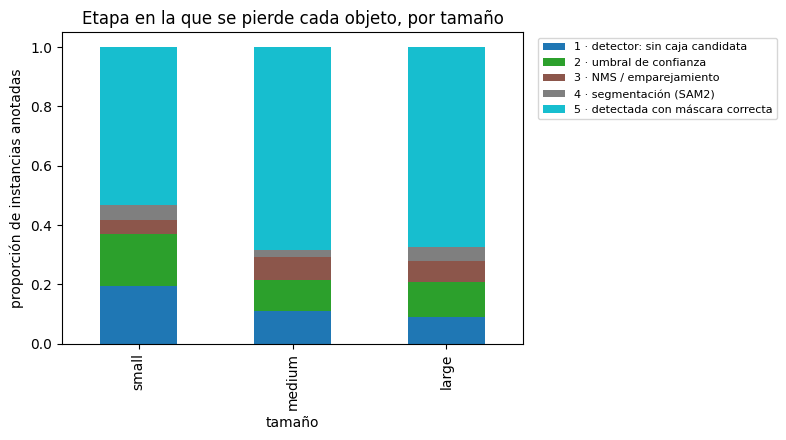

In [63]:
def con_j(df, col, nombre, extra=()):
    df = df.assign(j=df.groupby(['image_id', 'category_id']).cumcount())
    return df[['image_id', 'category_id', 'j', col, *extra]].rename(columns={col: nombre})

claves = ['image_id', 'category_id', 'j']
inst = (con_j(gc, 'detectado', 'caja_ok', ['category', 'rel_area'])
        .merge(con_j(gm, 'detectado', 'mascara_ok'), on=claves)
        .merge(con_j(gd, 'detectado', 'derivada_ok'), on=claves))


def iou_cruda(img_id, cat, j, score_min):
    cand = [d['bbox'] for d in raw.get(img_id, []) if d['category_id'] == cat and d['score'] >= score_min]
    if not cand:
        return 0.0
    return float(box_iou(xywh_to_xyxy(cand), xywh_to_xyxy([gt[img_id][cat][j]])).max())


inst['iou_cruda'] = [iou_cruda(i, c, j, 0.0) for i, c, j in zip(inst['image_id'], inst['category_id'], inst['j'])]
inst['iou_umbral'] = [iou_cruda(i, c, j, UMBRAL) for i, c, j in zip(inst['image_id'], inst['category_id'], inst['j'])]


def etapa_perdida(r):
    if r['iou_cruda'] < 0.5:
        return '1 · detector: sin caja candidata'
    if r['iou_umbral'] < 0.5:
        return '2 · umbral de confianza'
    if not r['caja_ok']:
        return '3 · NMS / emparejamiento'
    if not r['mascara_ok']:
        return '4 · segmentación (SAM2)'
    return '5 · detectada con máscara correcta'


inst['etapa'] = inst.apply(etapa_perdida, axis=1)
inst['tamaño'] = pd.cut(inst['rel_area'], [0, SIZE_SMALL, SIZE_MEDIUM, 1], labels=['small', 'medium', 'large'])
print(inst['etapa'].value_counts().sort_index())
por_tam = pd.crosstab(inst['etapa'], inst['tamaño'], normalize='columns').round(3)
display(por_tam)
display(pd.crosstab(inst['caja_ok'], inst['derivada_ok'], rownames=['caja detector ok'], colnames=['caja derivada ok']))

por_tam.T.plot.bar(stacked=True, figsize=(8, 4.5), colormap='tab10')
plt.ylabel('proporción de instancias anotadas'); plt.title('Etapa en la que se pierde cada objeto, por tamaño')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8); plt.tight_layout(); plt.show()

## G.3 · De la percepción a las respuestas

Para cada respuesta incorrecta (en los dos modos) se cruzan las instancias anotadas de las clases de la pregunta con la etapa de G.2, y se asigna una causa:
- **interpretación del LLM:** el JSON intermedio no coincide con la consigna;
- **percepción:** alguna instancia de la clase se perdió en una etapa de G.2;
- **sin pérdidas de percepción:** todas las instancias se detectaron, pero sobran detecciones (sobreconteo) o se eligió otra instancia, atributo o relación.

Así se ve si un error de una etapa se propaga hasta la respuesta.

In [64]:
etapas_por_cat = {k: Counter(s) for k, s in inst.groupby(['image_id', 'category_id'])['etapa']}
interp_ok = interp.set_index('question_id')['correcta']


def causa(modo, qid, etapas):
    if modo == 'llm' and not interp_ok[qid]:
        return 'interpretación del LLM'
    perdidas = {k: v for k, v in etapas.items() if not k.startswith('5')}
    if perdidas:
        return 'percepción: ' + max(perdidas, key=perdidas.get)
    return 'sin pérdidas de percepción (sobran detecciones u otra instancia)'


filas = []
for modo, comp in (('determinista', comp_det), ('llm', comp_llm)):
    for _, f in comp[~comp['acierto']].iterrows():
        c = por_id[f['question_id']]
        etapas = Counter()
        for clase in c['class_en']:
            for cat in ids_de_clase(clase, indice):
                etapas += etapas_por_cat.get((c['image_id'], cat), Counter())
        filas.append(dict(modo=modo, question_id=f['question_id'], tipo=f['tipo'], pred=f['pred'], ref=f['ref'],
                          instancias_gt=dict(etapas), causa=causa(modo, f['question_id'], etapas)))
errores_qa = pd.DataFrame(filas)
with pd.option_context('display.max_colwidth', 100):
    display(errores_qa)
if len(errores_qa):
    print(pd.crosstab(errores_qa['causa'], errores_qa['modo']))

,modo,question_id,tipo,pred,ref,instancias_gt,causa
0,determinista,DEV-1-Q1,count,1,2,{'1 · detector: sin caja candidata': 2},percepción: 1 · detector: sin caja candidata
1,determinista,DEV-4-Q1,count,2,4,"{'1 · detector: sin caja candidata': 1, '5 · detectada con máscara correcta': 2, '2 · umbral de ...",percepción: 1 · detector: sin caja candidata
2,determinista,DEV-5-Q1,count,2,3,"{'3 · NMS / emparejamiento': 1, '1 · detector: sin caja candidata': 1, '4 · segmentación (SAM2)'...",percepción: 3 · NMS / emparejamiento
3,determinista,DEV-7-Q1,count,1,2,"{'5 · detectada con máscara correcta': 1, '2 · umbral de confianza': 1}",percepción: 2 · umbral de confianza
4,determinista,DEV-8-Q1,count,1,2,"{'5 · detectada con máscara correcta': 1, '2 · umbral de confianza': 1}",percepción: 2 · umbral de confianza
5,determinista,DEV-9-Q1,count,3,2,{'5 · detectada con máscara correcta': 2},sin pérdidas de percepción (sobran detecciones u otra instancia)
6,determinista,DEV-23-Q1,existence,yes,no,{},sin pérdidas de percepción (sobran detecciones u otra instancia)
7,determinista,DEV-15-Q1,relation,insufficient_information,yes,"{'5 · detectada con máscara correcta': 1, '1 · detector: sin caja candidata': 1}",percepción: 1 · detector: sin caja candidata
8,determinista,DEV-25-Q1,relation,insufficient_information,no,"{'5 · detectada con máscara correcta': 1, '2 · umbral de confianza': 1}",percepción: 2 · umbral de confianza
9,determinista,DEV-25-Q2,size,insufficient_information,small,{'2 · umbral de confianza': 1},percepción: 2 · umbral de confianza


modo                                                determinista  llm
causa                                                                
interpretación del LLM                                         0    3
percepción: 1 · detector: sin caja candidata                   3    3
percepción: 2 · umbral de confianza                            4    4
percepción: 3 · NMS / emparejamiento                           1    1
sin pérdidas de percepción (sobran detecciones ...             2    2


## G.4 · La traza como herramienta de diagnóstico

El enunciado pide usar las trazas para evaluar las etapas y analizar la propagación de errores. Para cada pregunta del modo LLM se leen de la traza tres señales: si la interpretación necesitó respaldo, si el mapeo se abstuvo y si la redacción cayó a la plantilla. Se comparan entre respuestas correctas e incorrectas: si una señal es mucho más frecuente en las incorrectas, esa etapa es donde se origina el error.

In [65]:
tr_llm = pd.concat([traza_dev.tabla(), traza_test.tabla()], ignore_index=True)
tr_llm = tr_llm[tr_llm['etapa'].isin(['llm_interpretacion', 'qa_llm'])].copy()
tr_llm['question_id'] = tr_llm['params'].apply(lambda p: p.get('question_id'))
interp_t = tr_llm[tr_llm['etapa'] == 'llm_interpretacion'].set_index('question_id')['artefactos']
qa_t = tr_llm[tr_llm['etapa'] == 'qa_llm'].set_index('question_id')['artefactos']

filas = []
for _, f in comp_llm.iterrows():
    qid = f['question_id']
    filas.append(dict(question_id=qid, acierto=bool(f['acierto']),
                      interpretacion_con_respaldo=not interp_t[qid]['valida'],
                      mapeo_se_abstuvo=any(x.get('metodo') == 'sin_mapeo' for x in qa_t[qid]['resolucion']),
                      redaccion_con_plantilla=(qa_t[qid].get('verbalizacion') or {}).get('metodo') == 'plantilla'))
señales = pd.DataFrame(filas)
print(señales.groupby('acierto')[['interpretacion_con_respaldo', 'mapeo_se_abstuvo', 'redaccion_con_plantilla']]
      .mean().round(2))
print('Preguntas por grupo:', señales['acierto'].value_counts().to_dict())

         interpretacion_con_respaldo  mapeo_se_abstuvo  \
acierto                                                  
False                            0.0              0.15   
True                             0.0              0.00   

         redaccion_con_plantilla  
acierto                           
False                       0.77  
True                        0.19  
Preguntas por grupo: {True: 27, False: 13}


## G.5 · Resumen de métricas y configuración

Se guarda `metricas.json` con la configuración completa (modelos, umbrales, semilla, versiones) y las métricas de cada etapa, para que el reporte cite números que se puedan auditar.

In [66]:
tr = pd.concat([traza_dev.tabla(), traza_test.tabla()], ignore_index=True)
tiempos = tr.groupby(['traza', 'etapa'], sort=False)['segundos'].agg(['count', 'mean', 'sum']).round(3)
display(tiempos)

CONFIG = dict(semilla=SEED, detector=MODEL_ID, umbral_crudo=RAW_THR, umbral=UMBRAL, nms_iou=NMS_IOU,
              deteccion='completa + recortes (EXP-011)', grilla=GRILLA, solape=SOLAPE, margen=MARGEN,
              postproceso=POSTPROCESO,
              segmentador=SAM_ID, max_objetos=MAX_OBJ, size_thresholds=[SIZE_SMALL, SIZE_MEDIUM],
              llm=LLM_ID, llm_decodificacion='greedy', llm_intentos=LLM_INTENTOS, llm_max_tokens=LLM_MAX_TOKENS,
              mapeo_metodo=METODO_MAPEO, mapeo_parametros=PARAMS_MAPEO, mapeo_e5=E5_ID, mapeo_traductor=MT_ID,
              verbalizacion_intentos=VERB_INTENTOS, verbalizacion_max_tokens=VERB_MAX_TOKENS,
              verbalizacion='respuesta_base_compacta_v1',
              torch=torch.__version__, transformers=transformers.__version__)
metricas = dict(
    config=CONFIG,
    cajas_detector=m_caja, cajas_derivadas=m_der, mascaras=m_masc,
    scenejson_desarrollo=resumen_scene, test_con_error=sorted(errores_test),
    qa_determinista=dict(exactitud=round(float(comp_det['acierto'].mean()), 4), **resumen_fidelidad(fid_det)),
    qa_llm=dict(exactitud=round(float(comp_llm['acierto'].mean()), 4),
                interpretacion_correcta=round(float(interp['correcta'].mean()), 4), mapeo=mapeo_elegido,
                verbalizacion=resumen_verb, fidelidad_texto=dict(estado='pendiente_revision_manual',
                    archivo='auditoria_llm.csv', respuestas=len(tabla_auditoria)), **resumen_fidelidad(fid_llm)),
    perdidas_por_etapa=inst['etapa'].value_counts().sort_index().to_dict(),
    tiempos=tiempos.reset_index().to_dict('records'))
with (OUT_DIR / 'metricas.json').open('w', encoding='utf-8') as f:
    json.dump(metricas, f, ensure_ascii=False, indent=2, default=lambda o: o.item() if hasattr(o, 'item') else str(o))
print(json.dumps({k: metricas[k] for k in ('qa_determinista', 'qa_llm')}, ensure_ascii=False, indent=1))


count   mean      sum
traza      etapa                                    
desarrollo deteccion             120  2.354  282.490
           filtrado              120  0.000    0.029
           segmentacion          120  2.317  278.098
           scenejson             120  0.387   46.429
           qa_determinista        60  0.000    0.019
           llm_interpretacion     60  1.434   86.020
           qa_llm                 60  0.948   56.896
test       carga                  60  0.016    0.968
           deteccion              60  2.441  146.476
           filtrado               60  0.000    0.016
           segmentacion           60  2.274  136.469
           scenejson              60  0.356   21.370

{
 "qa_determinista": {
  "exactitud": 0.75,
  "fidelidad": 1.0,
  "abstencion": 0.05,
  "respuestas": 60
 },
 "qa_llm": {
  "exactitud": 0.675,
  "interpretacion_correcta": 0.95,
  "mapeo": {
   "metodo": "T1",
   "sim_min": 0.7,
   "margen": 0.01,
   "n": 50,
   "correcto": 0.94,
   "silencioso": 0.02,
   "abstencion": 0.04
  },
  "verbalizacion": {
   "preguntas_cerradas": {
    "con_ficha": 34,
    "aceptadas": 25
   },
   "descripciones": {
    "total": 20,
    "metodo": {
     "llm": 20
    }
   },
   "intentos": 69,
   "fidelidad_texto": "pendiente_revision_manual"
  },
  "fidelidad_texto": {
   "estado": "pendiente_revision_manual",
   "archivo": "auditoria_llm.csv",
   "respuestas": 60
  },
  "fidelidad": 1.0,
  "abstencion": 0.1,
  "respuestas": 60
 }
}


# Parte H · Experimento controlado

**Hipótesis:** el umbral que maximiza el F1 de detección (0,20, A.9) no tiene por qué ser el mejor para responder preguntas. Las detecciones de confianza baja que suman F1 (recall) pueden inflar los conteos y cambiar la instancia elegida.

**Diseño:**
- **Línea base:** el motor usa todos los objetos del SceneJSON (`conf_min = 0`, equivalente a 0,20).
- **Variable única:** `conf_min` del motor, en {0,25; 0,30; 0,35; 0,40}.
- **Fijo:** detector, umbral, NMS, máscaras y SceneJSON. El envío no cambia, así que el F1 de cajas y máscaras tampoco; solo cambia qué objetos considera el motor al responder.
- **Métricas:** exactitud por tipo contra la referencia de E.6, fidelidad y tasa de abstención.

**Por qué este experimento:** no necesita GPU (reutiliza las escenas), cambia una sola cosa y apunta al punto más débil del modo determinista (conteo).

**Cuidados al interpretar:**
- Hay solo 10 preguntas de conteo: cada una vale 10 puntos de exactitud.
- Elegir `conf_min` mirando estas mismas 20 imágenes es ajustar sobre desarrollo. Si se adopta, hay que declararlo y no esperar la misma mejora en test.
- Hay que registrar el resultado aunque no mejore.

,exactitud,exactitud_count,exactitud_existence,exactitud_position,exactitud_relation,exactitud_size,fidelidad,abstencion,respuestas
conf_min,,,,,,,,,
0.00,0.750,0.4,0.9,1.0,0.8,0.8,1.0,0.0500,60
0.25,0.750,0.4,0.9,1.0,0.8,0.8,1.0,0.0500,60
0.30,0.725,0.3,0.9,1.0,0.8,0.8,1.0,0.0500,60
0.35,0.725,0.3,0.9,1.0,0.8,0.8,1.0,0.0500,60
0.40,0.725,0.3,1.0,0.8,0.8,0.8,1.0,0.0667,60


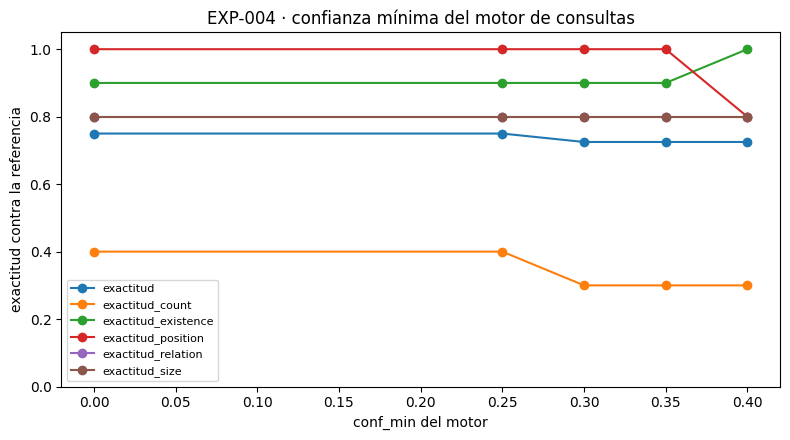

In [67]:
UMBRALES_QA = [0.0, 0.25, 0.30, 0.35, 0.40]
filas = []
for tau in UMBRALES_QA:
    resp_tau, reg_tau = responder_benchmark(scenejsons, consignas, interpretar_determinista, resolver_vocabulario,
                                            Traza(f'exp_conf_min_{tau}'), 'determinista', conf_min=tau)
    comp_tau = exactitud(resp_tau, ref)
    fila = dict(conf_min=tau, exactitud=round(float(comp_tau['acierto'].mean()), 3))
    fila.update({f'exactitud_{t}': round(float(v), 2) for t, v in comp_tau.groupby('tipo')['acierto'].mean().items()})
    fila.update(resumen_fidelidad(tabla_fidelidad(scenejsons, resp_tau, reg_tau, conf_min=tau)))
    filas.append(fila)
experimento = pd.DataFrame(filas).set_index('conf_min')
display(experimento)

ax = experimento.filter(like='exactitud').plot(marker='o', figsize=(8, 4.5))
ax.set_xlabel('conf_min del motor'); ax.set_ylabel('exactitud contra la referencia'); ax.set_ylim(0, 1.05)
ax.set_title('EXP-004 · confianza mínima del motor de consultas'); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

with (OUT_DIR / 'exp004_conf_min.json').open('w', encoding='utf-8') as f:
    json.dump(dict(experimento='EXP-004', hipotesis='subir conf_min mejora el conteo sin cambiar el SceneJSON',
                   variable='conf_min', linea_base=0.0, fijo=CONFIG, resultados=experimento.reset_index().to_dict('records')),
              f, ensure_ascii=False, indent=2)

**Conclusión (EXP-004, corrida de la versión 13):** la hipótesis se **refutó**. Subir `conf_min` empeoró la exactitud global (0,750 con 0,00; 0,725 con 0,25 y 0,30; 0,650 con 0,35; 0,550 con 0,40) y no mejoró el conteo (0,4 pasó a 0,3). Los 6 errores de conteo de la línea base son **subconteos** (el sistema contó menos objetos que la referencia), así que el problema no era que sobraran detecciones sino que faltaban. G.3 lo confirma: de las 10 respuestas deterministas incorrectas, 6 se originan porque el detector no produjo ninguna caja candidata y 4 porque la candidata quedó bajo el umbral de confianza. Subir `conf_min` solo agrava lo segundo.

Se mantiene `conf_min = 0` en el envío. **Intento que no mejoró**, registrado como pide el enunciado.

**Hipótesis siguiente (no ejecutada):** bajar el umbral de detección (A.8 muestra F1 0,646 con 0,15 contra 0,651 con 0,20, con más recall) podría recuperar como máximo las 4 respuestas perdidas por umbral; las otras 6 no dependen de ningún umbral.

**EXP-005 (mapeo de menciones, F.6):** compara cuatro métodos por código (e5 directo, traductor, LLM traduciendo y acuerdo) contra la línea base de la corrida v13. El primer intento (`e5_directo`) **no mejoró**: 44 % correcto y 48 % equivocado sin aviso. El resultado de esta corrida se lee de la tabla de F.6 y de `exp005_mapeo.json`.

**EXP-006 (redacción, F.7 y F.9b):** compara la redacción libre de la corrida V2 (8 de 19 descripciones con afirmaciones sin respaldo, según la revisión manual) con la redacción hecho por hecho y verificador de vocabulario cerrado. El resultado de esta corrida se lee de la auditoría de F.9b.

# Parte H.2 · Refinamiento de la percepción (EXP-007 a EXP-012)

**Punto de partida (G.2 y B.8 de la línea base EXP-001, antes de adoptar EXP-011):** los objetos pequeños son los que más se pierden. El 31,1 % no tiene ninguna caja candidata del detector (13,7 % en medianos, 9,5 % en grandes) y otro 19,4 % queda bajo el umbral. El recall de cajas es 0,49 / 0,70 / 0,76 (pequeño / mediano / grande). Como la detección es la base de máscaras, JSON y preguntas, se intenta mejorarla.

**Estas pruebas son hipótesis, no resultados:** no sabemos si funcionan. Se registran aunque no mejoren.
**Regla:** nada de esta parte modifica `raw`, `UMBRAL`, las escenas ni el CSV. Si una variante se adopta, se hace en un paso aparte y explícito.

**Adopción:** EXP-011 cumplió el criterio y se adoptó en A.3b, A.5, A.7 y D.1. Por eso `raw` ya contiene la detección con recortes, y en esta parte la **línea base** es `raw_completa` (solo la imagen completa, idéntica a EXP-001) con `tipo='iou'` (NMS clásico).

## H.2.1 · EXP-007 · Detección por recortes (tiling)

**Hipótesis:** OWLv2 redimensiona la imagen a un tamaño fijo. Si además se detecta sobre recortes solapados, cada objeto pequeño ocupa una fracción mayor de la entrada y el detector lo propone con más puntaje. Se espera subir el recall de objetos pequeños sin bajar mucho la precisión.

**Referencia:** EXP-001 (OWLv2 base sobre la imagen completa, umbral 0,20, NMS 0,5, F1 de cajas 0,6512).
**Único cambio:** además de la pasada sobre la imagen completa, 4 pasadas sobre recortes (grilla 2×2, solape 25 %). Modelo, vocabulario, `RAW_THR`, umbral y NMS no cambian.

**Cómo funciona:**
1. Pasada completa, igual que hoy: cubre objetos medianos y grandes.
2. Cada recorte se detecta por separado y sus cajas se llevan a coordenadas de la imagen completa.
3. Se descartan las cajas que tocan un borde *interior* del recorte (probables objetos cortados). Los bordes que coinciden con el borde de la imagen se conservan.
4. Se juntan todas y el NMS por categoría de siempre elimina duplicados.

**Riesgos:** más falsos positivos al ampliar texturas; cajas duplicadas o desplazadas; objetos más grandes que un recorte (solo los cubre la pasada completa); costo ≈ 5 pasadas por imagen.

**Criterio de decisión (fijado antes de correr; ajustarlo ahora si el grupo no está de acuerdo):** se adopta solo si, sobre las 120 imágenes y con el mejor umbral de cada variante, el F1 de cajas sube al menos 0,02, el recall de objetos pequeños sube al menos 0,05 y la precisión no baja más de 0,05. Si no, se descarta.

### Código (funciones y controles)

In [68]:
@torch.no_grad()
def detectar_con(modelo, procesador, imagen, umbral):
    """Igual que `detect` (A.3), pero con el modelo y el procesador explícitos: no toca los globales."""
    w, h = imagen.size
    inputs = procesador(text=[queries], images=imagen, return_tensors='pt').to(device)
    outputs = modelo(**inputs)
    lado = max(w, h)
    res = procesador.image_processor.post_process_object_detection(
        outputs, threshold=umbral, target_sizes=torch.tensor([[lado, lado]], device=device))[0]
    dets = []
    for box, score, label in zip(res['boxes'].cpu().tolist(), res['scores'].cpu().tolist(), res['labels'].cpu().tolist()):
        x1, y1, x2, y2 = box
        dets.append({'category_id': categories[label]['id'], 'category': categories[label]['name'],
                     'score': round(score, 4), 'bbox': [round(x1, 1), round(y1, 1), round(x2 - x1, 1), round(y2 - y1, 1)]})
    return dets


def generar_recortes(ancho, alto, grilla=(2, 2), solape=0.25):
    """Recortes (x0, y0, x1, y1) que cubren toda la imagen. `solape` = fracción de cada recorte que
    comparte con su vecino: un objeto más chico que ese solape cabe entero en algún recorte."""
    def ejes(largo, n):
        if n == 1:
            return [(0, largo)]
        lado = largo / (n - (n - 1) * solape)
        paso = lado * (1 - solape)
        return [(int(round(i * paso)), min(largo, int(round(i * paso + lado)))) for i in range(n)]
    xs, ys = ejes(ancho, grilla[0]), ejes(alto, grilla[1])
    return [(x0, y0, x1, y1) for (y0, y1) in ys for (x0, x1) in xs]


def detect_tiling(imagen, detectar, grilla=(2, 2), solape=0.25, margen=0.02, umbral=0.05):
    """Detección sobre la imagen completa + recortes. Devuelve cajas en coordenadas de la imagen completa."""
    ancho, alto = imagen.size
    dets = [dict(d, origen='completa') for d in detectar(imagen, umbral)]
    for k, (x0, y0, x1, y1) in enumerate(generar_recortes(ancho, alto, grilla, solape)):
        tw, th = x1 - x0, y1 - y0
        mx, my = max(2.0, margen * tw), max(2.0, margen * th)
        for d in detectar(imagen.crop((x0, y0, x1, y1)), umbral):
            x, y, w, h = d['bbox']
            xa, ya, xb, yb = max(0.0, x), max(0.0, y), min(float(tw), x + w), min(float(th), y + h)
            if xb - xa < 1 or yb - ya < 1:
                continue
            if ((x0 > 0 and xa <= mx) or (x1 < ancho and xb >= tw - mx)
                    or (y0 > 0 and ya <= my) or (y1 < alto and yb >= th - my)):
                continue                    # caja cortada por un borde interior del recorte
            dets.append(dict(d, bbox=[round(xa + x0, 1), round(ya + y0, 1), round(xb - xa, 1), round(yb - ya, 1)],
                             origen=f'recorte_{k}'))
    return dets


GRILLA, SOLAPE, MARGEN = (2, 2), 0.25, 0.02
detectar_base = lambda im, u: detectar_con(model, processor, im, u)

# Control 1 (sin GPU): los recortes cubren toda la imagen
for (W, H) in {(info['width'], info['height']) for info in img_info.values()}:
    cub = np.zeros((H, W), bool)
    for x0, y0, x1, y1 in generar_recortes(W, H, GRILLA, SOLAPE):
        cub[y0:y1, x0:x1] = True
    assert cub.all(), (W, H)
print('Recortes de una imagen de 640x480:', generar_recortes(640, 480, GRILLA, SOLAPE))

# Control 2: `detectar_con` reproduce lo ya guardado en `raw` (misma imagen, mismo modelo)
img_id0 = next(iter(img_info))
im0 = Image.open(paths[img_name(img_info[img_id0])]).convert('RGB')
print('Detecciones crudas guardadas vs recalculadas:', len(raw_completa[img_id0]), len(detectar_base(im0, RAW_THR)))

Recortes de una imagen de 640x480: [(0, 0, 366, 274), (274, 0, 640, 274), (0, 206, 366, 480), (274, 206, 640, 480)]
Detecciones crudas guardadas vs recalculadas: 78 78


### Celda 3 · markdown + código (imágenes piloto y funciones de resumen)

## H.2.2 · Imágenes de prueba (piloto)

Se eligen las 15 imágenes donde la línea base **más objetos pequeños anotados pierde**. Sirven para una primera señal rápida (≈ 1 minuto de GPU).

**Cuidado:** se eligieron *porque* la línea base falla ahí, así que cualquier mejora en este subconjunto está inflada (regresión a la media). La decisión se toma con las 120 imágenes (H.2.5), no con el piloto.

In [69]:
N_PILOTO = 15
m0, pred0, gt0 = evaluar(0.20, 0.5, detalle=True, fuente={i: filtrar(raw_completa[i], 0.20, 0.5, tipo='iou') for i in img_info})                     # línea base (EXP-001)
print('Control: F1 de la línea base =', m0['f1'])
chicas_perdidas = (gt0[(gt0['rel_area'] <= SIZE_SMALL) & (~gt0['detectado'])]
                   .groupby('image_id').size().sort_values(ascending=False))
piloto = list(chicas_perdidas.index[:N_PILOTO])
print('Imágenes piloto:', piloto, '| objetos pequeños perdidos en ellas:', int(chicas_perdidas.iloc[:N_PILOTO].sum()),
      'de', int(chicas_perdidas.sum()), 'en total')


def resumen_subconjunto(pred, gt_, ids, nombre):
    g = gt_[gt_['image_id'].isin(ids)].copy()
    p = pred[pred['image_id'].isin(ids)]
    g['tamaño'] = pd.cut(g['rel_area'], [0, SIZE_SMALL, SIZE_MEDIUM, 1], labels=['small', 'medium', 'large'])
    rec = g.groupby('tamaño', observed=True)['detectado'].mean()
    TP, FP, FN = int((p['estado'] == 'TP').sum()), int((p['estado'] == 'FP').sum()), int((~g['detectado']).sum())
    pr = TP / (TP + FP) if TP + FP else 0.0
    re_ = TP / (TP + FN) if TP + FN else 0.0
    return dict(variante=nombre, imagenes=len(ids), TP=TP, FP=FP, FN=FN, precision=round(pr, 3), recall=round(re_, 3),
                f1=round(2 * pr * re_ / (pr + re_), 3) if pr + re_ else 0.0,
                recall_small=round(float(rec.get('small', np.nan)), 3),
                recall_medium=round(float(rec.get('medium', np.nan)), 3),
                recall_large=round(float(rec.get('large', np.nan)), 3))

Control: F1 de la línea base = 0.6512
Imágenes piloto: [78, 43, 100, 50, 61, 45, 91, 96, 15, 40, 115, 104, 89, 106, 26] | objetos pequeños perdidos en ellas: 283 de 539 en total


### Celda 4 · markdown + código (correr el piloto)

## H.2.3 · Piloto: base vs. recortes

Se detecta con recortes solo en las imágenes piloto; el resto queda con las detecciones de siempre. Así el cambio mide únicamente el efecto de los recortes. Se compara en el subconjunto piloto y se cuenta cuántos objetos anotados se **rescatan** y cuántos se **pierden**.

In [70]:
traza_exp = Traza('exp007_008_percepcion')
raw_til = {}
for img_id in piloto:
    info = img_info[img_id]
    with traza_exp.etapa(Path(img_name(info)).stem, 'deteccion_tiling', modelo=MODEL_ID, grilla=GRILLA,
                         solape=SOLAPE, margen=MARGEN, umbral_crudo=RAW_THR) as paso:
        im = Image.open(paths[img_name(info)]).convert('RGB')
        raw_til[img_id] = detect_tiling(im, detectar_base, GRILLA, SOLAPE, MARGEN, RAW_THR)
        paso['artefactos'].update(crudas_base=len(raw[img_id]), crudas_tiling=len(raw_til[img_id]))

fuente_til = {i: filtrar(raw_til.get(i, raw_completa[i]), 0.20, 0.5, tipo='iou') for i in img_info}   # fuera del piloto: sin cambios
m1, pred1, gt1 = evaluar(UMBRAL, NMS_IOU, detalle=True, fuente=fuente_til)
display(pd.DataFrame([resumen_subconjunto(pred0, gt0, piloto, 'base'),
                      resumen_subconjunto(pred1, gt1, piloto, 'tiling')]).set_index('variante'))

def con_j(df):
    return df.assign(j=df.groupby(['image_id', 'category_id']).cumcount())
cmp_ = (con_j(gt0).merge(con_j(gt1)[['image_id', 'category_id', 'j', 'detectado']],
                         on=['image_id', 'category_id', 'j'], suffixes=('_base', '_til')))
cmp_ = cmp_[cmp_['image_id'].isin(piloto)]
rescatadas = cmp_[(~cmp_['detectado_base']) & cmp_['detectado_til']]
perdidas_ = cmp_[cmp_['detectado_base'] & (~cmp_['detectado_til'])]
print('Objetos anotados rescatados por los recortes:', len(rescatadas), '| perdidos:', len(perdidas_))
t_base = traza_dev.tabla().query("etapa == 'deteccion'")['segundos'].mean()
t_til = traza_exp.tabla().query("etapa == 'deteccion_tiling'")['segundos'].mean()
print(f'Tiempo de detección por imagen: base {t_base:.2f} s | recortes {t_til:.2f} s')

,imagenes,TP,FP,FN,precision,recall,f1,recall_small,recall_medium,recall_large
variante,,,,,,,,,,
base,15,250,102,318,0.710,0.440,0.543,0.387,0.649,0.889
tiling,15,337,202,231,0.625,0.593,0.609,0.556,0.742,0.889


Objetos anotados rescatados por los recortes: 89 | perdidos: 2
Tiempo de detección por imagen: base 2.35 s | recortes 2.49 s


### Celda 5 · código (mirar qué rescató)

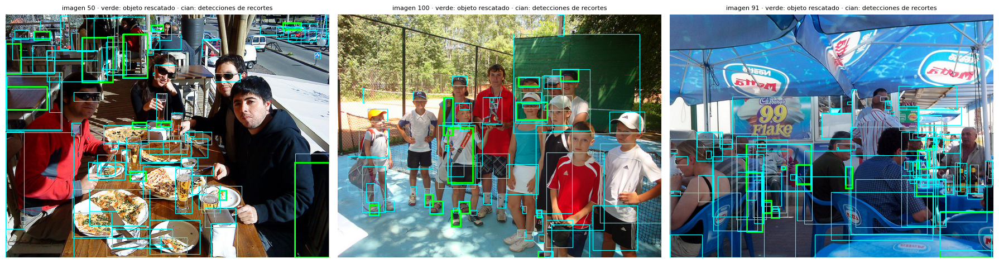

In [71]:
top = rescatadas.groupby('image_id').size().sort_values(ascending=False).index[:3]
if len(top):
    fig, axes = plt.subplots(1, len(top), figsize=(6 * len(top), 6), squeeze=False)
    for ax, img_id in zip(axes[0], top):
        ax.imshow(Image.open(paths[img_name(img_info[img_id])]).convert('RGB')); ax.axis('off')
        for _, r in rescatadas[rescatadas['image_id'] == img_id].iterrows():
            x, y, w, h = r['bbox']
            ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, edgecolor='lime', lw=2))
        for d in fuente_til[img_id]:
            if d['origen'] != 'completa':
                x, y, w, h = d['bbox']
                ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, edgecolor='cyan', lw=0.8))
        ax.set_title(f'imagen {img_id} · verde: objeto rescatado · cian: detecciones de recortes', fontsize=8)
    plt.tight_layout(); plt.show()

### Celda 6 · markdown + código (las 120 imágenes y la decisión)

## H.2.4 · Las 120 imágenes: barrido de umbral y decisión

Se completa la detección con recortes en las 120 imágenes (≈ 5 pasadas por imagen) y se repite el barrido de umbral de A.8 para **ambas** variantes: los puntajes de las cajas de recortes pueden distribuirse distinto, así que cada variante se compara con *su* mejor umbral. Se aplica el criterio fijado en H.2.1.

0 3s
20 48s
40 92s
80 177s
100 216s


,variante,umbral,TP,FP,FN,precision,recall,f1,cobertura
0,base,0.05,1342,2722,448,0.3302,0.7497,0.4585,0.2772
1,base,0.10,1267,1207,523,0.5121,0.7078,0.5943,0.3386
2,base,0.15,1164,650,626,0.6417,0.6503,0.6459,0.4005
3,base,0.20,1042,368,748,0.7390,0.5821,0.6512,0.4615
4,base,0.25,928,200,862,0.8227,0.5184,0.6361,0.5225
5,base,0.30,782,134,1008,0.8537,0.4369,0.5780,0.5779
6,base,0.35,663,86,1127,0.8852,0.3704,0.5223,0.6457
7,base,0.40,547,59,1243,0.9026,0.3056,0.4566,0.7088
8,base,0.50,354,14,1436,0.9620,0.1978,0.3281,0.8142
0,tiling,0.05,1458,4484,332,0.2454,0.8145,0.3771,0.2506


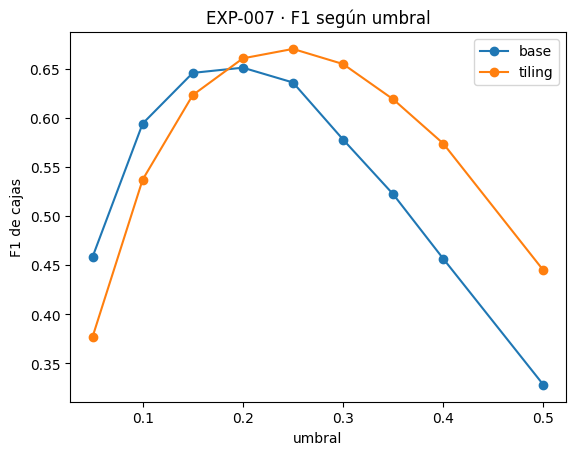

Mejor umbral: base 0.2 (F1 0.6512) | recortes 0.25 (F1 0.6703)
Recall por tamaño: base {'small': 0.4886, 'medium': 0.7025, 'large': 0.7619} | recortes {'small': 0.5493, 'medium': 0.7165, 'large': 0.7321}
ΔF1 = +0.019 | Δrecall small = +0.061 | Δprecisión = -0.009
CRITERIO DE ADOPCIÓN: NO se cumple


In [72]:
EJECUTAR_TILING_COMPLETO = True       # ≈ 5 pasadas por imagen: unos minutos de GPU (estimado)
if EJECUTAR_TILING_COMPLETO:
    t0 = time.time()
    for k, (img_id, info) in enumerate(img_info.items()):
        if img_id in raw_til:
            continue
        with traza_exp.etapa(Path(img_name(info)).stem, 'deteccion_tiling', modelo=MODEL_ID, grilla=GRILLA,
                             solape=SOLAPE, margen=MARGEN, umbral_crudo=RAW_THR) as paso:
            im = Image.open(paths[img_name(info)]).convert('RGB')
            raw_til[img_id] = detect_tiling(im, detectar_base, GRILLA, SOLAPE, MARGEN, RAW_THR)
            paso['artefactos'].update(crudas_base=len(raw[img_id]), crudas_tiling=len(raw_til[img_id]))
        if k % 20 == 0:
            print(k, f'{time.time() - t0:.0f}s')
    with open(OUT_DIR / 'detections_raw_owlv2_tiling.json', 'w') as f:
        json.dump(dict(model=MODEL_ID, raw_threshold=RAW_THR, grilla=GRILLA, solape=SOLAPE, margen=MARGEN,
                       detections=raw_til), f)
assert len(raw_til) == len(img_info), 'Faltan imágenes: ejecutar con EJECUTAR_TILING_COMPLETO = True'


def barrido(fuente_raw, nombre, umbrales=(0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5)):
    filas = []
    for t in umbrales:
        m_ = evaluar(t, NMS_IOU, fuente={i: filtrar(fuente_raw.get(i, []), t, NMS_IOU, tipo='iou') for i in img_info})
        filas.append(dict(variante=nombre, **m_))
    return pd.DataFrame(filas)




def recall_por_tamano(fuente_raw, umbral):
    _, _, g = evaluar(umbral, NMS_IOU, detalle=True,
                      fuente={i: filtrar(fuente_raw.get(i, []), umbral, NMS_IOU, tipo='iou') for i in img_info})
    g = g.assign(tamaño=pd.cut(g['rel_area'], [0, SIZE_SMALL, SIZE_MEDIUM, 1], labels=['small', 'medium', 'large']))
    return g.groupby('tamaño', observed=True)['detectado'].mean().round(4)



tab_base, tab_til = barrido(raw_completa, 'base'), barrido(raw_til, 'tiling')
display(pd.concat([tab_base, tab_til])[['variante', 'umbral', 'TP', 'FP', 'FN', 'precision', 'recall', 'f1', 'cobertura']])
for tab in (tab_base, tab_til):
    plt.plot(tab['umbral'], tab['f1'], marker='o', label=tab['variante'].iloc[0])
plt.xlabel('umbral'); plt.ylabel('F1 de cajas'); plt.legend(); plt.title('EXP-007 · F1 según umbral'); plt.show()

mb, mt = tab_base.sort_values('f1').iloc[-1], tab_til.sort_values('f1').iloc[-1]
rb, rt = recall_por_tamano(raw_completa, mb['umbral']), recall_por_tamano(raw_til, mt['umbral'])
dF1, dRs, dP = mt['f1'] - mb['f1'], rt['small'] - rb['small'], mt['precision'] - mb['precision']
print(f"Mejor umbral: base {mb['umbral']} (F1 {mb['f1']}) | recortes {mt['umbral']} (F1 {mt['f1']})")
print(f"Recall por tamaño: base {rb.to_dict()} | recortes {rt.to_dict()}")
print(f'ΔF1 = {dF1:+.3f} | Δrecall small = {dRs:+.3f} | Δprecisión = {dP:+.3f}')
cumple = bool(dF1 >= 0.02 and dRs >= 0.05 and dP >= -0.05)
print('CRITERIO DE ADOPCIÓN:', 'SE CUMPLE' if cumple else 'NO se cumple')
with (OUT_DIR / 'exp007_tiling.json').open('w', encoding='utf-8') as f:
    json.dump(dict(experimento='EXP-007', config=dict(grilla=GRILLA, solape=SOLAPE, margen=MARGEN, modelo=MODEL_ID),
                   base=mb.to_dict(), tiling=mt.to_dict(), recall_base=rb.to_dict(), recall_tiling=rt.to_dict(),
                   criterio_cumplido=cumple),
              f, ensure_ascii=False, indent=2, default=lambda o: o.item() if hasattr(o, 'item') else str(o))

**Conclusión (EXP-007, corrida de la versión 16):**

| Condición (fijada antes de correr) | Resultado | ¿Cumple? |
| :--- | :--- | :---: |
| F1 de cajas sube ≥ 0,02 | +0,019 (0,6512 → 0,6703) | ❌ por 0,001 |
| Recall de objetos pequeños sube ≥ 0,05 | +0,061 (0,4886 → 0,5493) | ✅ |
| Precisión no baja más de 0,05 | −0,009 | ✅ |

**Decisión:** no cumple por 0,001 en el F1. Se decide descartar la opción de tiling.

## H.2.5 · EXP-008 · Modelo `owlv2-large-patch14-ensemble`

**Hipótesis:** un detector más grande propone más cajas correctas, también de objetos pequeños, sin cambiar el resto de la pipeline.
**Referencia:** EXP-001. **Único cambio:** el modelo (mismo vocabulario, `RAW_THR`, NMS; el umbral se re-elige por el mismo barrido que en A.8).
**Criterio de decisión:** el mismo que en H.2.1 (ΔF1 ≥ 0,02, Δrecall de pequeños ≥ 0,05, Δprecisión ≥ −0,05).
**Antes de la corrida completa se mide:** memoria, tiempo por imagen y resolución de entrada.

In [73]:
from transformers import Owlv2Processor, Owlv2ForObjectDetection
MODEL_ID_L = 'google/owlv2-large-patch14-ensemble'
if device == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0), '| total', round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1),
          'GB | libre antes de cargar', round(torch.cuda.mem_get_info()[0] / 1e9, 1), 'GB')
processor_L = Owlv2Processor.from_pretrained(MODEL_ID_L)
model_L = Owlv2ForObjectDetection.from_pretrained(MODEL_ID_L).to(device).eval()
print('Resolución de entrada base / grande:', processor.image_processor.size, '/', processor_L.image_processor.size)
print('Parámetros (millones) base / grande:', round(sum(p.numel() for p in model.parameters()) / 1e6),
      '/', round(sum(p.numel() for p in model_L.parameters()) / 1e6))

muestra = [Image.open(paths[img_name(img_info[i])]).convert('RGB') for i in list(img_info)[:5]]
def medir(modelo, procesador):
    detectar_con(modelo, procesador, muestra[0], RAW_THR)            # calentamiento
    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats(); t0 = time.perf_counter()
    for im in muestra:
        detectar_con(modelo, procesador, im, RAW_THR)
    torch.cuda.synchronize()
    return (time.perf_counter() - t0) / len(muestra), torch.cuda.max_memory_allocated() / 1e9
s_b, g_b = medir(model, processor); s_l, g_l = medir(model_L, processor_L)
print(f'base  : {s_b:.2f} s/imagen | pico de memoria del proceso {g_b:.1f} GB')
print(f'grande: {s_l:.2f} s/imagen | pico de memoria del proceso {g_l:.1f} GB')
print(f'Estimado para las 120 imágenes: {120 * s_l / 60:.1f} min | para las 60 de test: {60 * s_l / 60:.1f} min')

GPU: Tesla T4 | total 15.6 GB | libre antes de cargar 9.4 GB


preprocessor_config.json:   0%|          | 0.00/427 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.10k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/121 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.75GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/610 [00:00<?, ?it/s]

Resolución de entrada base / grande: SizeDict(height=960, width=960, longest_edge=None, shortest_edge=None, max_height=None, max_width=None) / SizeDict(height=1008, width=1008, longest_edge=None, shortest_edge=None, max_height=None, max_width=None)
Parámetros (millones) base / grande: 155 / 438
base  : 0.47 s/imagen | pico de memoria del proceso 7.4 GB
grande: 2.37 s/imagen | pico de memoria del proceso 7.6 GB
Estimado para las 120 imágenes: 4.7 min | para las 60 de test: 2.4 min


In [74]:
EJECUTAR_GRANDE_COMPLETO = True
raw_L = {}
if EJECUTAR_GRANDE_COMPLETO:
    t0 = time.time()
    for k, (img_id, info) in enumerate(img_info.items()):
        with traza_exp.etapa(Path(img_name(info)).stem, 'deteccion_grande', modelo=MODEL_ID_L, umbral_crudo=RAW_THR) as paso:
            im = Image.open(paths[img_name(info)]).convert('RGB')
            raw_L[img_id] = detectar_con(model_L, processor_L, im, RAW_THR)
            paso['artefactos']['detecciones_crudas'] = len(raw_L[img_id])
        if k % 20 == 0:
            print(k, f'{time.time() - t0:.0f}s')
    with open(OUT_DIR / 'detections_raw_owlv2_large.json', 'w') as f:
        json.dump(dict(model=MODEL_ID_L, raw_threshold=RAW_THR, detections=raw_L), f)
assert len(raw_L) == len(img_info)

tab_L = barrido(raw_L, 'owlv2-large')
display(pd.concat([tab_base, tab_L])[['variante', 'umbral', 'TP', 'FP', 'FN', 'precision', 'recall', 'f1', 'cobertura']])
mL = tab_L.sort_values('f1').iloc[-1]
rL = recall_por_tamano(raw_L, mL['umbral'])
dF1, dRs, dP = mL['f1'] - mb['f1'], rL['small'] - rb['small'], mL['precision'] - mb['precision']
print(f"Mejor umbral: base {mb['umbral']} (F1 {mb['f1']}) | grande {mL['umbral']} (F1 {mL['f1']})")
print(f'ΔF1 = {dF1:+.3f} | Δrecall small = {dRs:+.3f} | Δprecisión = {dP:+.3f}')
cumple_L = bool(dF1 >= 0.02 and dRs >= 0.05 and dP >= -0.05)
print('CRITERIO DE ADOPCIÓN:', 'SE CUMPLE' if cumple_L else 'NO se cumple')
with (OUT_DIR / 'exp008_large.json').open('w', encoding='utf-8') as f:
    json.dump(dict(experimento='EXP-008', modelo=MODEL_ID_L, base=mb.to_dict(), grande=mL.to_dict(),
                   recall_base=rb.to_dict(), recall_grande=rL.to_dict(), criterio_cumplido=cumple_L,
                   segundos_por_imagen=dict(base=round(s_b, 3), grande=round(s_l, 3))),
              f, ensure_ascii=False, indent=2, default=lambda o: o.item() if hasattr(o, 'item') else str(o))
traza_exp.guardar()
del model_L; torch.cuda.empty_cache()           # libera memoria para las celdas siguientes

0 2s
20 51s
40 98s
60 146s
80 193s
100 241s


,variante,umbral,TP,FP,FN,precision,recall,f1,cobertura
0,base,0.05,1342,2722,448,0.3302,0.7497,0.4585,0.2772
1,base,0.10,1267,1207,523,0.5121,0.7078,0.5943,0.3386
2,base,0.15,1164,650,626,0.6417,0.6503,0.6459,0.4005
3,base,0.20,1042,368,748,0.7390,0.5821,0.6512,0.4615
4,base,0.25,928,200,862,0.8227,0.5184,0.6361,0.5225
5,base,0.30,782,134,1008,0.8537,0.4369,0.5780,0.5779
6,base,0.35,663,86,1127,0.8852,0.3704,0.5223,0.6457
7,base,0.40,547,59,1243,0.9026,0.3056,0.4566,0.7088
8,base,0.50,354,14,1436,0.9620,0.1978,0.3281,0.8142
0,owlv2-large,0.05,1340,2606,450,0.3396,0.7486,0.4672,0.3355


Mejor umbral: base 0.2 (F1 0.6512) | grande 0.15 (F1 0.6071)
ΔF1 = -0.044 | Δrecall small = +0.003 | Δprecisión = -0.116
CRITERIO DE ADOPCIÓN: NO se cumple


**Conclusión (EXP-008, corridas del 27/10):** el modelo grande **no cumple** el criterio y se descarta.

| Condición (fijada antes de correr) | Resultado | ¿Cumple? |
| :--- | :--- | :---: |
| F1 de cajas sube ≥ 0,02 | −0,044 (0,6512 → 0,6071, mejor umbral 0,15) | ❌ |
| Recall de objetos pequeños sube ≥ 0,05 | +0,003 | ❌ |
| Precisión no baja más de 0,05 | −0,116 | ❌ |

Al mismo umbral (0,15) los dos modelos tienen casi los mismos falsos positivos (642 contra 650), pero el grande acierta 104 objetos menos: sus puntajes separan peor los aciertos de los errores. Cuesta ≈ 5 veces más (2,1 s contra 0,4 s por imagen en una T4). El tamaño del modelo no es el cuello de botella. **Intento que no mejoró**, registrado como pide el enunciado.


## H.2.6 · EXP-009 · Recortes solo para objetos chicos y medianos

**Por qué:** en EXP-007 los recortes subieron el recall de objetos chicos (+0,061) pero bajaron el de grandes (0,762 → 0,732): en un recorte, el detector ve una parte de un objeto grande y la etiqueta como el objeto entero.
**Hipótesis:** si de los recortes solo se conservan cajas de hasta el 10 % del área de la imagen, se mantiene la mejora en objetos chicos y se recupera la de grandes.
**Único cambio respecto de EXP-007:** se descartan las cajas de recortes con área > 10 % (el corte `medium`/`large` del proyecto; no se prueban otros valores). Las detecciones de la imagen completa no cambian. No usa GPU: reutiliza `raw_til`.
**Criterio (el mismo de EXP-007, fijado antes de correr):** contra la línea base, F1 ≥ +0,02, recall de chicos ≥ +0,05 y precisión que no baje más de 0,05.


In [75]:
CORTE_RECORTES = SIZE_MEDIUM          # 0.10, fijado antes de correr

# Si la sesión se reinició, se recargan las detecciones de EXP-007 desde el archivo
if 'raw_til' not in globals() or len(raw_til) != len(img_info):
    with open(OUT_DIR / 'detections_raw_owlv2_tiling.json') as f:
        raw_til = {int(k): v for k, v in json.load(f)['detections'].items()}

def recortes_solo_chicos(raw_x, corte):
    """Conserva todo lo de la imagen completa y, de los recortes, solo cajas de hasta `corte` del área.
    El área es la de la caja PREDICHA: no usa anotaciones."""
    out = {}
    for i, dets in raw_x.items():
        area_img = img_info[i]['width'] * img_info[i]['height']
        out[i] = [d for d in dets
                  if d['origen'] == 'completa' or d['bbox'][2] * d['bbox'][3] / area_img <= corte]
    return out

raw_til9 = recortes_solo_chicos(raw_til, CORTE_RECORTES)

tab_base = barrido(raw_completa, 'base')
tab_til  = barrido(raw_til, 'EXP-007 recortes')
tab_til9 = barrido(raw_til9, 'EXP-009 recortes chicos')

mejores = [t.sort_values('f1').iloc[-1] for t in (tab_base, tab_til, tab_til9)]
filas_exp9 = []
for fila, fuente in zip(mejores, (raw_completa, raw_til, raw_til9)):
    rec = recall_por_tamano(fuente, fila['umbral'])
    filas_exp9.append(dict(variante=fila['variante'], umbral=fila['umbral'], TP=fila['TP'], FP=fila['FP'], FN=fila['FN'],
                      precision=fila['precision'], recall=fila['recall'], f1=fila['f1'],
                      recall_small=rec['small'], recall_medium=rec['medium'], recall_large=rec['large']))
display(pd.DataFrame(filas_exp9).set_index('variante'))

mb9, m9 = filas_exp9[0], filas_exp9[2]
dF1, dRs, dP = m9['f1'] - mb9['f1'], m9['recall_small'] - mb9['recall_small'], m9['precision'] - mb9['precision']
cumple9 = bool(dF1 >= 0.02 and dRs >= 0.05 and dP >= -0.05)
print(f'ΔF1 = {dF1:+.3f} | Δrecall small = {dRs:+.3f} | Δprecisión = {dP:+.3f}')
print('CRITERIO DE ADOPCIÓN:', 'SE CUMPLE' if cumple9 else 'NO se cumple')

with (OUT_DIR / 'exp009_recortes_chicos.json').open('w', encoding='utf-8') as f:
    json.dump(dict(experimento='EXP-009', referencia='EXP-001', corte_recortes=CORTE_RECORTES,
                   resultados=filas_exp9, criterio_cumplido=cumple9),
              f, ensure_ascii=False, indent=2, default=lambda o: o.item() if hasattr(o, 'item') else str(o))


,umbral,TP,FP,FN,precision,recall,f1,recall_small,recall_medium,recall_large
variante,,,,,,,,,,
base,0.20,1042,368,748,0.7390,0.5821,0.6512,0.4886,0.7025,0.7619
EXP-007 recortes,0.25,1109,410,681,0.7301,0.6196,0.6703,0.5493,0.7165,0.7321
EXP-009 recortes chicos,0.25,1105,403,685,0.7328,0.6173,0.6701,0.5493,0.7165,0.7083


ΔF1 = +0.019 | Δrecall small = +0.061 | Δprecisión = -0.006
CRITERIO DE ADOPCIÓN: NO se cumple


**Conclusión (EXP-009, corrida del 27/10):** hipótesis **refutada**; no se adopta. El F1 queda igual que EXP-007 (0,6701; ΔF1 +0,019) y el recall de grandes **empeora** (0,732 → 0,708): las cajas grandes de los recortes ayudaban a encontrar objetos grandes.

El control de la celda siguiente lo explica: la base con umbral 0,25 tiene el mismo recall de grandes que EXP-009 (0,7083; con 0,20 es 0,7619). La caída en grandes del tiling viene de subir el umbral global de 0,20 a 0,25, no de los recortes.


In [76]:
# Control: recall por tamaño de la línea base con el umbral de la base (0,20) y con el de los recortes (0,25)
print('Base a 0.20:', recall_por_tamano(raw_completa, 0.20).to_dict())
print('Base a 0.25:', recall_por_tamano(raw_completa, 0.25).to_dict())


Base a 0.20: {'small': 0.4886, 'medium': 0.7025, 'large': 0.7619}
Base a 0.25: {'small': 0.426, 'medium': 0.6338, 'large': 0.7083}


## H.2.7 · EXP-010 · Umbral según el origen de la caja
**Por qué:** la base a 0,25 tiene el mismo recall de grandes que EXP-009 (0,7083): la caída en grandes del tiling se debe a subir el umbral global de 0,20 a 0,25, no a los recortes.
**Único cambio respecto de EXP-007:** umbral 0,20 para las cajas de la imagen completa y 0,25 para las de los recortes. Los valores salen de EXP-001 y EXP-007; no se barren.
**Criterio (el mismo de EXP-007):** contra la base, F1 ≥ +0,02, recall de chicos ≥ +0,05 y precisión que no baje más de 0,05.


In [77]:
U_COMPLETA, U_RECORTE = 0.20, 0.25          # fijados antes de correr

raw_til10 = {i: [d for d in dets if d['score'] >= (U_COMPLETA if d['origen'] == 'completa' else U_RECORTE)]
             for i, dets in raw_til.items()}
fuente10 = {i: filtrar(raw_til10.get(i, []), 0.0, NMS_IOU, tipo='iou') for i in img_info}
m10 = evaluar(0.0, NMS_IOU, fuente=fuente10)
r10 = recall_por_tamano(raw_til10, 0.0)

fila10 = dict(variante='EXP-010 umbral por origen', TP=m10['TP'], FP=m10['FP'], FN=m10['FN'],
              precision=m10['precision'], recall=m10['recall'], f1=m10['f1'],
              recall_small=r10['small'], recall_medium=r10['medium'], recall_large=r10['large'])
display(pd.DataFrame(filas_exp9 + [fila10]).set_index('variante'))

mb9 = filas_exp9[0]
dF1, dRs, dP = fila10['f1'] - mb9['f1'], fila10['recall_small'] - mb9['recall_small'], fila10['precision'] - mb9['precision']
cumple10 = bool(dF1 >= 0.02 and dRs >= 0.05 and dP >= -0.05)
print(f'ΔF1 = {dF1:+.3f} | Δrecall small = {dRs:+.3f} | Δprecisión = {dP:+.3f}')
print('CRITERIO DE ADOPCIÓN:', 'SE CUMPLE' if cumple10 else 'NO se cumple')


,umbral,TP,FP,FN,precision,recall,f1,recall_small,recall_medium,recall_large
variante,,,,,,,,,,
base,0.20,1042,368,748,0.7390,0.5821,0.6512,0.4886,0.7025,0.7619
EXP-007 recortes,0.25,1109,410,681,0.7301,0.6196,0.6703,0.5493,0.7165,0.7321
EXP-009 recortes chicos,0.25,1105,403,685,0.7328,0.6173,0.6701,0.5493,0.7165,0.7083
EXP-010 umbral por origen,NaN,1152,511,638,0.6927,0.6436,0.6672,0.5683,0.7465,0.7679


ΔF1 = +0.016 | Δrecall small = +0.080 | Δprecisión = -0.046
CRITERIO DE ADOPCIÓN: NO se cumple


**Conclusión (EXP-010, corrida del 27/10):** no se adopta. Recupera el recall de grandes (~0,76) y es la variante con más recall en todos los tamaños, pero suma muchos falsos positivos y queda con ΔF1 **+0,016** (F1 0,6672; Δrecall de chicos +0,080; Δprecisión −0,046).


## H.2.8 · EXP-011 y EXP-012 · Otra forma de unir las cajas de los recortes
**Por qué:** en EXP-007 a EXP-010 los recortes suben el recall, pero el NMS por IoU no elimina cajas parciales que quedan dentro de otra de la misma clase.
- **EXP-011:** NMS por categoría con IoS ≥ 0,5 (intersección / área de la caja más chica), el criterio por defecto de SAHI.
- **EXP-012:** Weighted Boxes Fusion entre dos fuentes (imagen completa y recortes), con `iou_thr` 0,55 y `skip_box_thr` 0,05, sus valores por defecto.
**Único cambio respecto de EXP-007:** cómo se unen las cajas. Detecciones, modelo y vocabulario iguales; no usa GPU. El umbral se re-elige con el barrido.
**Criterio:** el de EXP-007 (contra la base: F1 ≥ +0,02, recall de chicos ≥ +0,05, precisión ≥ −0,05).
**Aviso:** son el 5.º y 6.º intento sobre las mismas 120 imágenes; si alguno se adopta, hay que declararlo como posible ajuste a desarrollo.


In [78]:
!pip install -q ensemble-boxes
from ensemble_boxes import weighted_boxes_fusion

if 'raw_til' not in globals() or len(raw_til) != len(img_info):
    with open(OUT_DIR / 'detections_raw_owlv2_tiling.json') as f:
        raw_til = {int(k): v for k, v in json.load(f)['detections'].items()}

# --- EXP-011 · NMS por categoría con IoS (como SAHI) ---
# `nms_ios` está definida en A.3b (es la que usa la pipeline).

# --- EXP-012 · WBF entre imagen completa y recortes ---
def wbf_origen(dets, ancho, alto, iou=0.55, skip=0.05):
    fuentes = [[d for d in dets if d['origen'] == 'completa'], [d for d in dets if d['origen'] != 'completa']]
    boxes, scores, labels = [], [], []
    for ds in fuentes:
        boxes.append([[max(0, d['bbox'][0] / ancho), max(0, d['bbox'][1] / alto),
                       min(1, (d['bbox'][0] + d['bbox'][2]) / ancho), min(1, (d['bbox'][1] + d['bbox'][3]) / alto)] for d in ds])
        scores.append([d['score'] for d in ds]); labels.append([d['category_id'] for d in ds])
    if not any(scores):
        return []
    b, s, l = weighted_boxes_fusion(boxes, scores, labels, iou_thr=iou, skip_box_thr=skip)
    return [{'category_id': int(c), 'score': float(sc), 'bbox': [x1 * ancho, y1 * alto, (x2 - x1) * ancho, (y2 - y1) * alto]}
            for (x1, y1, x2, y2), sc, c in zip(b, s, l) if x2 > x1 and y2 > y1]

raw_wbf = {i: wbf_origen(d, img_info[i]['width'], img_info[i]['height']) for i, d in raw_til.items()}

UMBRALES = (0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5)
def barrido_con(postproceso, raw_x, nombre):
    filas_b = []
    for t in UMBRALES:
        fuente = {i: postproceso([d for d in raw_x.get(i, []) if d['score'] >= t]) for i in img_info}
        filas_b.append(dict(variante=nombre, **evaluar(t, NMS_IOU, fuente=fuente)))
    return pd.DataFrame(filas_b)

nms_iou_05 = lambda ds: filtrar(ds, 0.0, NMS_IOU, tipo='iou')
tabs = [barrido_con(nms_iou_05, raw_completa, 'base'),
        barrido_con(nms_iou_05, raw_til, 'EXP-007 recortes + NMS IoU'),
        barrido_con(nms_ios, raw_til, 'EXP-011 recortes + NMS IoS'),
        barrido_con(nms_iou_05, raw_wbf, 'EXP-012 recortes + WBF')]
mejores_exp = pd.DataFrame([t.sort_values('f1').iloc[-1] for t in tabs]).set_index('variante')
display(mejores_exp[['umbral', 'TP', 'FP', 'FN', 'precision', 'recall', 'f1']])

b = mejores_exp.iloc[0]
for nombre in mejores_exp.index[2:]:
    m_ = mejores_exp.loc[nombre]
    print(f"{nombre}: ΔF1 = {m_['f1'] - b['f1']:+.3f} | Δprecisión = {m_['precision'] - b['precision']:+.3f} | "
          f"criterio de F1 {'SE CUMPLE' if m_['f1'] - b['f1'] >= 0.02 else 'NO se cumple'}")


,umbral,TP,FP,FN,precision,recall,f1
variante,,,,,,,
base,0.20,1042,368,748,0.7390,0.5821,0.6512
EXP-007 recortes + NMS IoU,0.25,1109,410,681,0.7301,0.6196,0.6703
EXP-011 recortes + NMS IoS,0.20,1135,432,655,0.7243,0.6341,0.6762
EXP-012 recortes + WBF,0.15,1175,596,615,0.6635,0.6564,0.6599


EXP-011 recortes + NMS IoS: ΔF1 = +0.025 | Δprecisión = -0.015 | criterio de F1 SE CUMPLE
EXP-012 recortes + WBF: ΔF1 = +0.009 | Δprecisión = -0.076 | criterio de F1 NO se cumple


In [79]:
filas_ios = []
for t in (0.15, 0.20, 0.25, 0.30):
    fte = {i: nms_ios([d for d in raw_til.get(i, []) if d['score'] >= t]) for i in img_info}
    m_, _, g = evaluar(t, NMS_IOU, detalle=True, fuente=fte)
    g = g.assign(tamaño=pd.cut(g['rel_area'], [0, SIZE_SMALL, SIZE_MEDIUM, 1], labels=['small', 'medium', 'large']))
    rec = g.groupby('tamaño', observed=True)['detectado'].mean()
    filas_ios.append(dict(umbral=t, f1=m_['f1'], precision=m_['precision'], recall=m_['recall'],
                          small=rec['small'], medium=rec['medium'], large=rec['large']))
display(pd.DataFrame(filas_ios).set_index('umbral').round(4))

# Control: ¿cuánto aporta el IoS solo, sin recortes? (barrido completo de umbral)
tab_ios_solo = barrido_con(nms_ios, raw_completa, 'base + NMS IoS (sin recortes)')
display(tab_ios_solo[['umbral', 'TP', 'FP', 'FN', 'precision', 'recall', 'f1']])
m_ios_solo = tab_ios_solo.sort_values('f1').iloc[-1]
print(f"Control · IoS sin recortes: mejor F1 {m_ios_solo['f1']} (umbral {m_ios_solo['umbral']}) | base 0.6512 | EXP-011 {mejores_exp.loc['EXP-011 recortes + NMS IoS', 'f1']}")


,f1,precision,recall,small,medium,large
umbral,,,,,,
0.15,0.6592,0.6458,0.6732,0.6290,0.7306,0.7560
0.20,0.6762,0.7243,0.6341,0.5816,0.7060,0.7202
0.25,0.6745,0.7875,0.5899,0.5285,0.6725,0.6964
0.30,0.6545,0.8288,0.5408,0.4763,0.6356,0.6250


,umbral,TP,FP,FN,precision,recall,f1
0,0.05,1198,1368,592,0.4669,0.6693,0.5500
1,0.10,1153,698,637,0.6229,0.6441,0.6333
2,0.15,1083,413,707,0.7239,0.6050,0.6592
3,0.20,984,254,806,0.7948,0.5497,0.6499
4,0.25,891,150,899,0.8559,0.4978,0.6295
5,0.30,760,105,1030,0.8786,0.4246,0.5725
6,0.35,647,69,1143,0.9036,0.3615,0.5164
7,0.40,538,51,1252,0.9134,0.3006,0.4523
8,0.50,352,14,1438,0.9617,0.1966,0.3265


Control · IoS sin recortes: mejor F1 0.6592 (umbral 0.15) | base 0.6512 | EXP-011 0.6762


**Conclusión (EXP-011 y EXP-012, corrida del 27/10):**

| Condición (fijada antes de correr) | EXP-011 (recortes + NMS IoS, umbral 0,20) | EXP-012 (recortes + WBF) |
| :--- | :--- | :--- |
| F1 de cajas sube ≥ 0,02 | +0,025 (0,6512 → 0,6762) ✅ | +0,009 (0,6599) ❌ |
| Recall de objetos pequeños sube ≥ 0,05 | +0,093 (0,489 → 0,582) ✅ | — |
| Precisión no baja más de 0,05 | −0,015 ✅ | −0,076 ❌ |

- **EXP-011 se adopta** (A.3b, A.5, A.7 y D.1). Supera a la base en todos los umbrales entre 0,15 y 0,30 (0,659 / 0,676 / 0,675 / 0,655) y vuelve al umbral de la base (0,20).
- **Control:** el NMS por IoS sin recortes mejora poco (mejor F1 0,6592 con umbral 0,15, +0,008). La mayor parte de la mejora viene de combinar recortes e IoS.
- **Limitación:** a umbral 0,20 el recall de objetos grandes baja (0,762 → 0,720). El IoS descarta la caja de menor puntaje cuando una queda dentro de otra; si un recorte propone una parte del objeto con más puntaje que la caja entera, gana la parte. SAHI evita esto fusionando cajas (NMM); queda como trabajo futuro.
- **EXP-012 no se adopta:** WBF promedia cajas de objetos distintos y suma falsos positivos.
- **Aviso metodológico:** EXP-011 es el 5.º intento sobre las mismas 120 imágenes de desarrollo. El criterio se fijó antes de correr y la técnica viene de la literatura (SAHI), pero la mejora puede ser algo menor en test.


# Parte I · Envío

## I.1 · Armar y validar el CSV

80 filas, en el orden y con los ids de `sample_submission.csv`. Las 20 filas del benchmark llevan `questions` (modo determinista) y `questions_llm` (modo LLM). Cada fila pasa por `validar_scenejson` antes de escribirse, que ahora también comprueba que la `evidence` apunte a ids existentes. Una fila inválida corta la ejecución, en lugar de subir un CSV que Kaggle rechazaría.

In [80]:
sub_ref = pd.read_csv(archivo_referencia('sample_submission.csv'))
assert list(sub_ref.columns) == ['image_id', 'SceneJSON']
assert len(sub_ref) == 80 and sub_ref['image_id'].is_unique
todas = {**scenejsons, **scenes_test}
faltan = [i for i in sub_ref['image_id'] if i not in todas]
assert not faltan, f'Faltan escenas: {faltan}'

filas = []
for image_id in sub_ref['image_id']:                 # mismo orden y mismos ids que el ejemplo
    escena = todas[image_id]
    if image_id.startswith('tpi_'):
        escena = {**escena, 'questions': respuestas.get(image_id, []),
                  'questions_llm': respuestas_llm.get(image_id, [])}
    esperadas = {c['question_id'] for c in consignas if Path(c['image_file']).stem == image_id}
    if esperadas:
        for campo in ('questions', 'questions_llm'):
            qs = escena.get(campo, [])
            assert len(qs) == len(esperadas) and {q['question_id'] for q in qs} == esperadas, (image_id, campo)
    errs = validar_scenejson(escena)
    assert not errs and escena['image']['id'] == image_id, (image_id, errs[:2])
    filas.append(dict(image_id=image_id,
                      SceneJSON=json.dumps(escena, ensure_ascii=False, allow_nan=False,
                                           separators=(',', ':'))))

sub = pd.DataFrame(filas)
sub.to_csv(OUT_DIR / 'submission.csv', index=False)

chk = pd.read_csv(OUT_DIR / 'submission.csv')
assert chk.shape == (80, 2) and chk['image_id'].tolist() == sub_ref['image_id'].tolist()
print('Forma:', chk.shape, '| columnas:', list(chk.columns))
print('Ids únicos:', chk['image_id'].is_unique, '| coinciden con el ejemplo:', set(chk['image_id']) == set(sub_ref['image_id']))
print('Tamaño del archivo (MB):', round((OUT_DIR / 'submission.csv').stat().st_size / 1e6, 1))
print('Escena más grande (MB):', round(chk['SceneJSON'].str.len().max() / 1e6, 2))
print('Escenas de respaldo (con error):', [i for i in sub['image_id'] if todas[i]['generation_status'] == 'error'])

Forma: (80, 2) | columnas: ['image_id', 'SceneJSON']
Ids únicos: True | coinciden con el ejemplo: True
Tamaño del archivo (MB): 18.5
Escena más grande (MB): 1.35
Escenas de respaldo (con error): []


## I.2 · Verificaciones del CSV escrito

Se relee el archivo, se resume el tamaño de cada escena y se dibujan tres escenas de test desde el CSV, para comprobar que lo que se sube es lo que se calculó.

In [81]:
chk = pd.read_csv(OUT_DIR / 'submission.csv')
resumen = pd.DataFrame([
    dict(image_id=f['image_id'],
         objetos=len((sc := json.loads(f['SceneJSON']))['objects']),
         relaciones=len(sc['relations']),
         MB=round(len(f['SceneJSON']) / 1e6, 2))
    for _, f in chk.iterrows()])
display(resumen.describe().round(2))
display(resumen.head())

,objetos,relaciones,MB
count,80.00,80.00,80.00
mean,31.64,2650.65,0.20
std,19.71,3250.31,0.22
min,4.00,26.00,0.01
25%,17.75,609.50,0.06
50%,27.00,1457.00,0.12
75%,39.00,3010.00,0.23
max,119.00,19998.00,1.35


,image_id,objetos,relaciones,MB
0,test_0001,31,1916,0.15
1,test_0002,11,250,0.04
2,test_0003,19,694,0.06
3,test_0004,13,322,0.03
4,test_0005,13,318,0.03


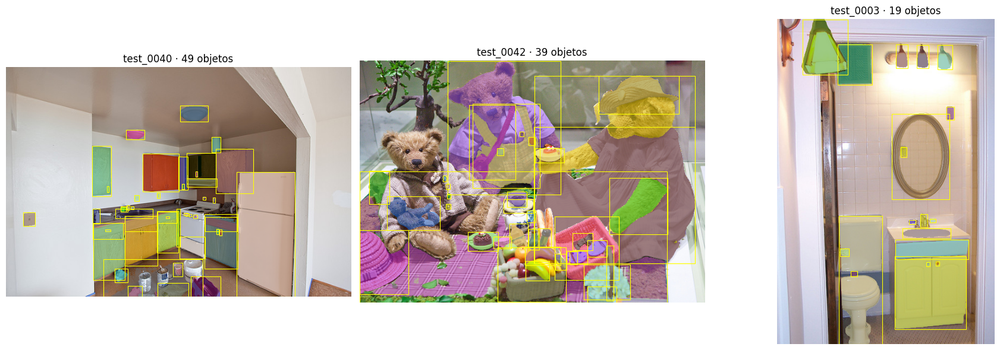

In [82]:
por_stem = {Path(n).stem: p for n, p in paths.items()}
rng = np.random.default_rng(0)
muestra = chk[chk['image_id'].str.startswith('test_')].sample(3, random_state=1)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (_, f) in zip(axes, muestra.iterrows()):
    sc = json.loads(f['SceneJSON'])
    h, w = sc['image']['height'], sc['image']['width']
    canvas = np.array(Image.open(por_stem[f['image_id']]).convert('RGB')).astype(float)
    for o in sc['objects']:
        m = mask_utils.decode(mask_utils.frPyObjects(o['mask'], h, w)).astype(bool)
        canvas[m] = 0.5 * canvas[m] + 0.5 * rng.integers(0, 255, 3)
    ax.imshow(canvas.astype(np.uint8)); ax.axis('off')
    for o in sc['objects']:
        x0, y0, x1, y1 = o['bbox']
        ax.add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor='yellow', lw=0.8))
    ax.set_title(f"{f['image_id']} · {len(sc['objects'])} objetos")
plt.tight_layout(); plt.show()

## I.3 · Trazas y artefactos

Se guardan las trazas completas (percepción y preguntas) y se listan los archivos producidos.

In [83]:
for t in (traza_dev, traza_test):
    print('Traza guardada:', t.guardar(), f'({len(t.eventos)} eventos)')
print(sorted(p.name for p in OUT_DIR.iterdir() if p.is_file()))

Traza guardada: /kaggle/working/traza_desarrollo.jsonl (660 eventos)
Traza guardada: /kaggle/working/traza_test.jsonl (300 eventos)
['__notebook__.ipynb', 'auditoria_llm.csv', 'detections_raw_owlv2.json', 'detections_raw_owlv2_large.json', 'detections_raw_owlv2_tiling.json', 'eval_exp001.json', 'exp004_conf_min.json', 'exp005_mapeo.json', 'exp007_tiling.json', 'exp008_large.json', 'exp009_recortes_chicos.json', 'llm_interpretaciones.jsonl', 'metricas.json', 'scenejson_dev.jsonl', 'scenejson_validacion.json', 'submission.csv', 'traza_desarrollo.jsonl', 'traza_exp007_008_percepcion.jsonl', 'traza_test.jsonl']
